# 1. Complex numbers

If you know linear algebra from ML (vectors, dot products, matrices), the one new ingredient is the **complex number**: a number that carries a size *and* a rotation. This folder builds the idea in five steps, one notebook each, and every step is a prerequisite for the next:

| # | Notebook | What you learn | Why quantum computing needs it |
|---|---|---|---|
| **1** | **`1_complex_numbers`** (you are here) | real part, imaginary part, what `i` does, addition and subtraction, magnitude, phase, conjugate, polar form, Euler's formula, multiplication as rotation | an amplitude has a size (→ probability) and a phase (→ interference) |
| 2 | `2_complex_vectors` | lists of complex numbers, adding and scaling them, conjugate and norm of a vector | a qubit state is a vector `(α, β)` |
| 3 | `3_complex_vectors_space` | linear combinations, basis, dimension, linear independence | superposition is a linear combination; `n` qubits live in `2ⁿ` dimensions |
| 4 | `4_inner_product_space` | inner product, norm, orthogonality, normalization | overlaps between states and measurement probabilities (Born rule) |
| 5 | `5_Hilbert_space` | completeness, finite-dimensional complex Hilbert spaces, subspaces | the formal home of qubit states; ties steps 1–4 together |

---
## 1. Complex numbers — from the basics to why qubits need them

**Video intro (optional warm-up):** [Complex numbers on YouTube](https://www.youtube.com/watch?v=2i5AqFWc-Qo)

**How to read this notebook**
- Every point follows the same pattern: *idea in plain words → the formula (only when needed, every symbol explained) → a Python line → a picture.*
- Python writes the imaginary unit as `1j` (not `i`): `3 + 2j` is the number 3 + 2i.
- Suggested order: the "why" (1.1) → real part → imaginary part → what `i` does → addition and subtraction → magnitude → phase → conjugate → polar form → Euler's formula → multiplication → why it matters for quantum computing.

| Section | Point | One-line meaning | Python |
|---|---|---|---|
| 1.1 | Why complex numbers exist | `x² = −1` has no answer on the number line, so add a dimension | — |
| 1.2 | Real part | `a` in `z = a + bi`: how far **right** | `z.real` |
| 1.3 | Imaginary part | `b` in `z = a + bi`: how far **up** | `z.imag` |
| 1.4 | What `i` does (the imaginary unit) | a quarter turn (90°) | `1j * z` |
| 1.5 | Complex addition and subtraction | add or subtract the parts separately = slide the arrow | `z + w`, `z - w` |
| 1.6 | Magnitude (modulus) | the **length** of the arrow | `abs(z)` |
| 1.7 | Phase (argument) | the **angle** of the arrow | `np.angle(z)` |
| 1.8 | Complex conjugate | mirror image across the real axis | `z.conjugate()` |
| 1.9 | Polar form | describe the point by (length, angle) instead of (right, up) | `cmath.polar(z)` |
| 1.10 | Euler's formula | continuous rotation: the "angle dial" | `np.exp(1j * theta)` |
| 1.11 | Complex multiplication | lengths multiply, angles add | `z * w` |
| 1.12 | Why magnitude and conjugate matter in quantum computing | probabilities and overlaps | `abs(z)**2`, `np.vdot` |
| 1.13 | Why rotation appears where nothing rotates | radio waves, quantum systems, oscillation | — |
| 1.14 | ML example | rotary embeddings (RoPE) | — |
| 1.15 | Summary | everything on one page | — |
| 1.16 | The big picture | four takeaways: magnitude + rotation, what `i` adds, solvable equations, a language for rotation | — |


<div style="border-left: 5px solid #dc2626; background: rgba(220, 38, 38, 0.10); padding: 10px 16px; border-radius: 4px;">

<b style="color:#dc2626">🔴 HINT CARD</b>: nine ideas to keep at hand (details in sections 1.6 to 1.14). A complex number is `z = a + bi`: `a` is the real part (how far right), `b` the imaginary part (how far up).

| Idea | In plain words | Formula | Python | Example (`z = 3 + 2i` unless noted) |
|---|---|---|---|---|
| **1. Magnitude** (modulus) | **how long** the arrow is: the distance from the origin. Details: [section 1.6](#16-magnitude-modulus) | `r = √(a² + b²)` | `abs(z)` | `√13 ≈ 3.61` |
| **2. Phase** (argument) | **which way** the arrow points: the angle from the positive real axis, counter-clockwise. Details: [section 1.7](#17-phase-argument) | `θ = atan2(b, a)` | `np.angle(z)` | `33.7°` (0.588 rad) |
| **3. Complex conjugate** | the **mirror image** across the real axis: keep `a`, flip the sign of `b`. Details: [section 1.8](#18-complex-conjugate) | `z* = a − bi` | `z.conjugate()` | `3 − 2i` |
| **4. Polar form** | the same point written as (length, angle) instead of (right, up). Details: [section 1.9](#19-polar-form) | `z = r·(cos θ + i·sin θ) = r·e^{iθ}` | `cmath.polar(z)`, `cmath.rect(r, θ)` | `(3.61, 33.7°)` |
| **5. Euler's formula** | the **angle dial**: turn `θ` and the point glides around the circle of length 1. Details: [section 1.10](#110-eulers-formula-continuous-rotation) | `e^{iθ} = cos θ + i·sin θ` | `np.exp(1j * theta)` | `e^{i·0.588} ≈ 0.83 + 0.55i` (`z` shrunk to length 1) |
| **6. Multiplication** | **lengths multiply, angles add**: turn by the angle of `w`, stretch by its length. Details: [section 1.11](#111-complex-multiplication-lengths-multiply-angles-add) | `(r₁·e^{iθ₁})·(r₂·e^{iθ₂}) = r₁r₂·e^{i(θ₁+θ₂)}` | `z * w` | `(3 + 2i)·i = −2 + 3i` (quarter turn, same length) |
| **7. Probability and overlap** (quantum computing) | the **squared length of an amplitude is a probability**; the conjugate makes the overlap of two states come out right. Details: [section 1.12](#112-why-magnitude-and-conjugate-matter-in-quantum-computing) | `P = α·α*`, overlap `Σ conj(uᵢ)·vᵢ` | `abs(alpha)**2`, `np.vdot(u, v)` | amplitudes `0.6` and `0.8i` give `0.36` and `0.64` (sum 1) |
| **8. Why rotation appears** | two linked quantities that trade places (position and velocity, electric and magnetic field) make the state go **around a circle**; adding arrows gives **interference**. Details: [section 1.13](#113-why-does-rotation-show-up-in-systems-that-do-not-visibly-rotate) | `z·e^{iθ}` turns by `θ`; `z₁ + z₂` interferes | `z * np.exp(1j * shift)`, `z1 + z2` | spring: `(x, v) = (cos t, −sin t)` |
| **9. ML example: RoPE** | rotate each pair of embedding numbers `(x₁, x₂)` by an angle that grows with the token position `m`, so scores depend only on the **distance** between tokens. Details: [section 1.14](#114-example-for-an-ml-engineer--rotary-embeddings-rope) | `z → z·e^{imθ}` | `z * np.exp(1j * m * theta)` | `(3, 2)`, `m = 2`, `θ = 0.3`: `≈ 1.35 + 3.34i` |

Also after 1.10: the one-page recap is [section 1.15](#115-summary--complex-numbers), the four big takeaways are [section 1.16](#116-the-big-picture-four-takeaways).

</div>

### 1.1 Why complex numbers exist: the equation x² = −1

**The problem.** Find a number `x` such that `x * x == -1`.

On the ordinary number line there is **no answer**: a positive number squared is positive, a negative number squared is *also* positive, and 0² = 0. The animation below shows the same fact: slide `x` along the real line and `x²` never reaches −1, so `x² = −1` has no real solution.

**Mathematicians had met this situation before, and each time the fix was to add room:**

| Equation | Needs a new kind of number | What the fix did |
|---|---|---|
| x + 1 = 0 | −1 (negative numbers) | extended the line to the left |
| 2x = 1 | 1/2 (fractions) | filled gaps between the integers |
| x² = 2 | √2 (irrational numbers) | filled gaps between the fractions |
| **x² = −1** | **i (complex numbers)** | **added a second dimension** |

<b style="color:#16a34a">The "extra dimension" trick.</b> The number line is 1-dimensional: every number sits on one line, and no spot on it squares to −1. Instead of declaring "no solution", allow a **second axis, perpendicular to the first**, and name its unit step `i`, with one rule: `i · i = −1`. The two missing answers of `x² = −1`, namely `+i` and `−i`, now have a place to live: one step above the line and one step below it (watch the second half of the animation: turn `x` by 90° and `x²` lands exactly on −1). No rule of arithmetic was broken; the answer was simply given somewhere to sit.

**Short history — a trick first, geometry later.**
- **1500s (Cardano, Bombelli).** Cubic equations such as `x³ = 15x + 4` have an obvious real answer (`x = 4`), yet the solution formula passes through `√−121`. Bombelli showed that if you carry those "impossible" pieces along using the rule `i² = −1`, they cancel at the end and the correct real answer pops out. Complex numbers entered as a **calculation trick that worked**.
- **~250 years later (Wessel, Argand, Gauss).** Someone drew the plane. Only then did it become clear what the trick *means*: the second axis is a genuine direction. The cell below replays Bombelli's check.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: find a real `x` with `x² = −1`. Spoiler: there is none, so we look for it in the complex plane.

</div>

**▶ The animation.** It loops by itself. The same ten steps are also shown one by one as pictures under the code cell below, so you can read each step at your own pace.

![Ten steps: x slides along the real line, then turns by 90° while x² turns by 180° until x² = −1](assets/1_1_x_squared_minus_one.gif)

smallest x² + 1 over 2 million real x: 1.0   (never 0)
(1j)² = (-1+0j)   (-1j)² = (-1+0j)
Bombelli: (2+i)³ = (2+11j)   (2+i) + (2-i) = (4+0j)  = 4, a real answer reached through complex numbers


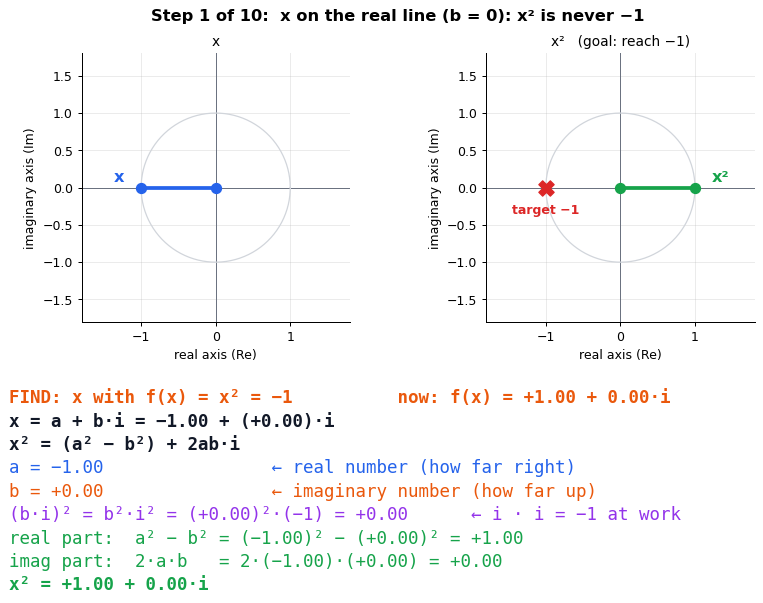

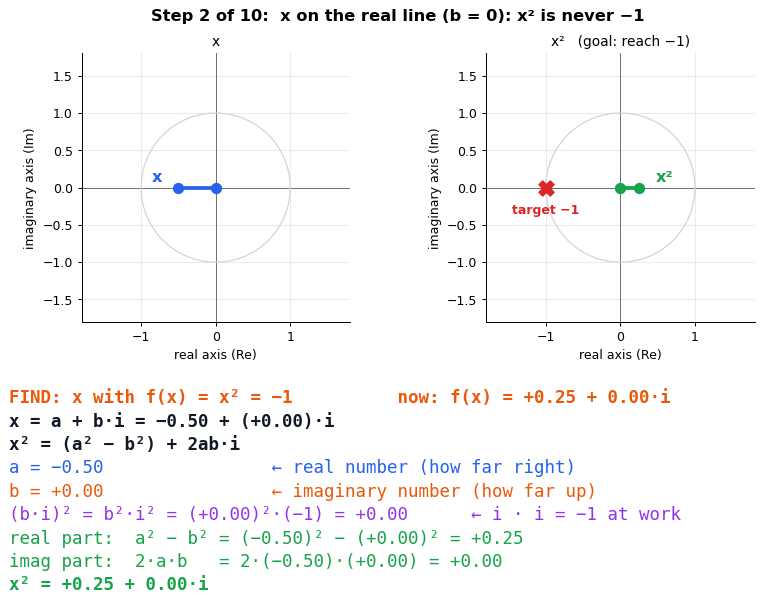

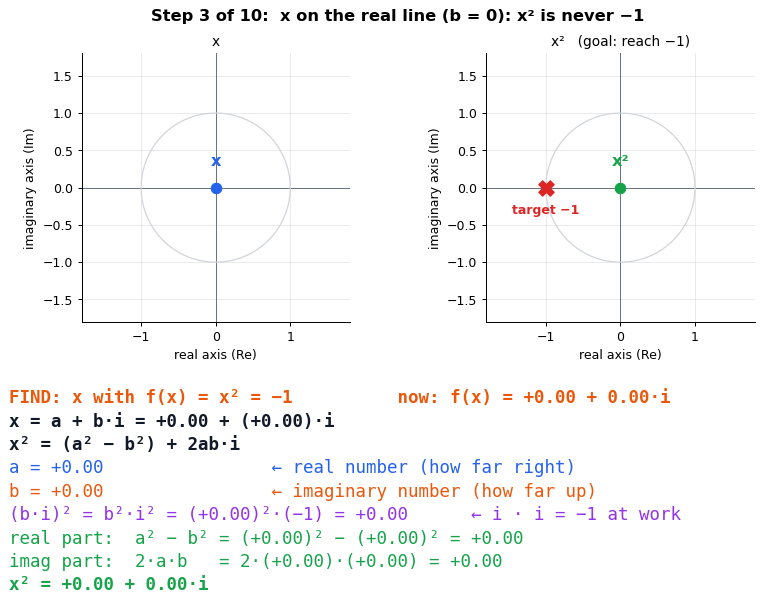

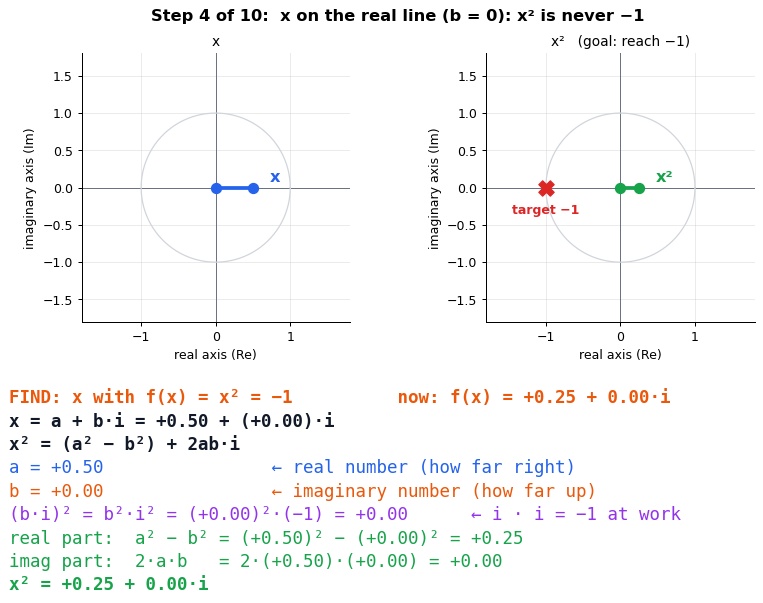

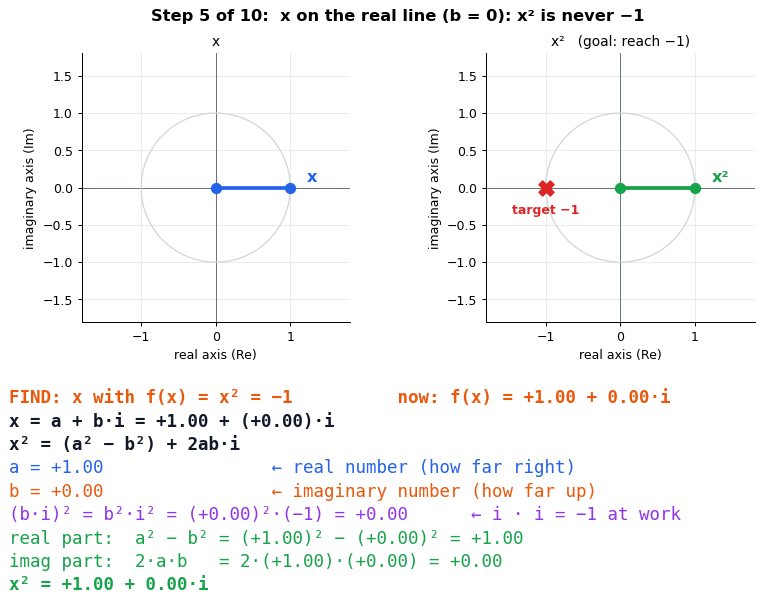

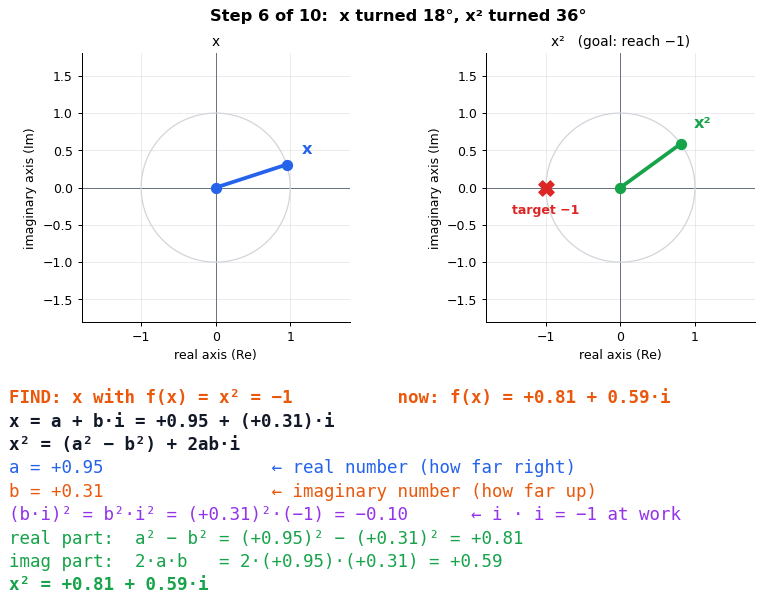

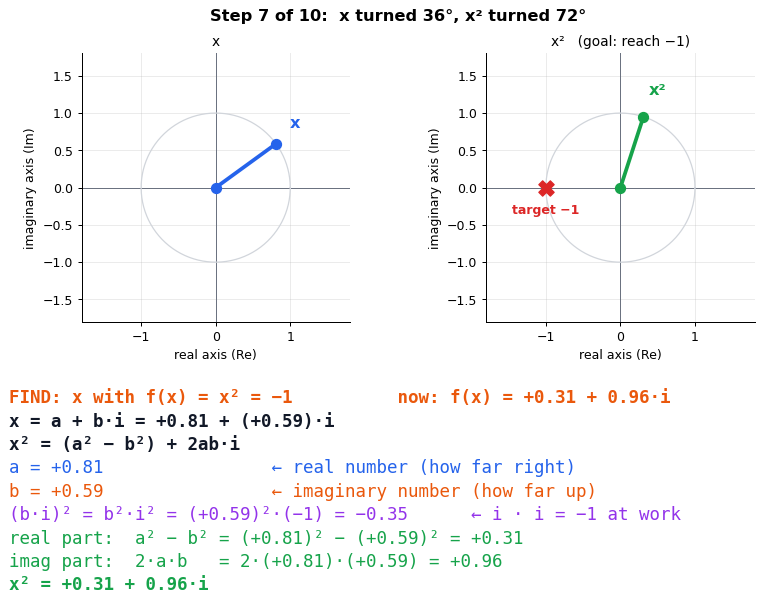

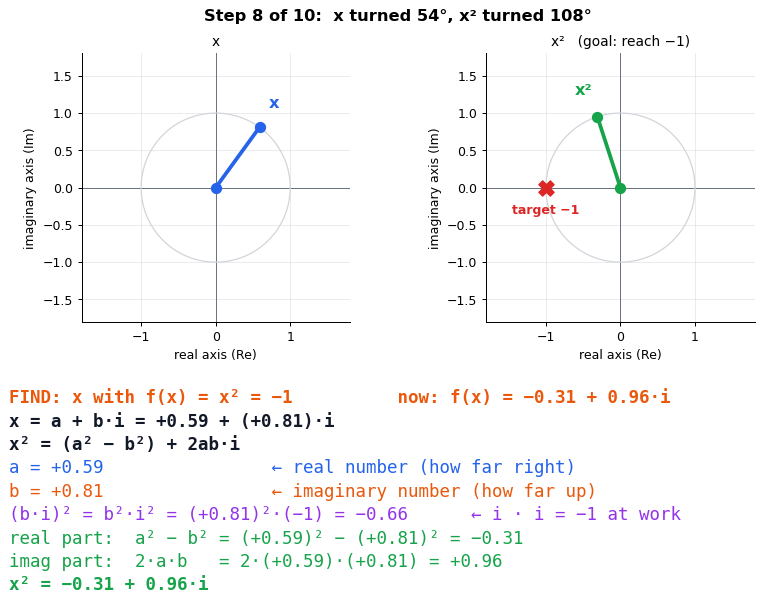

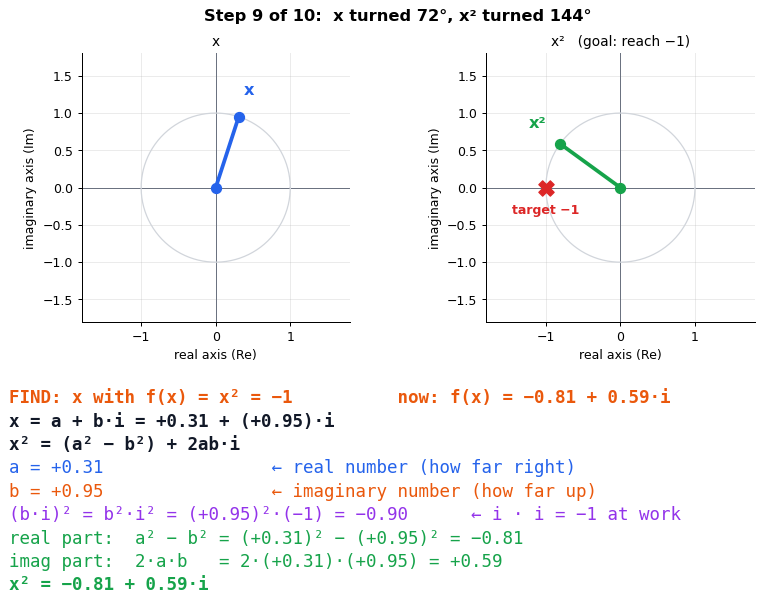

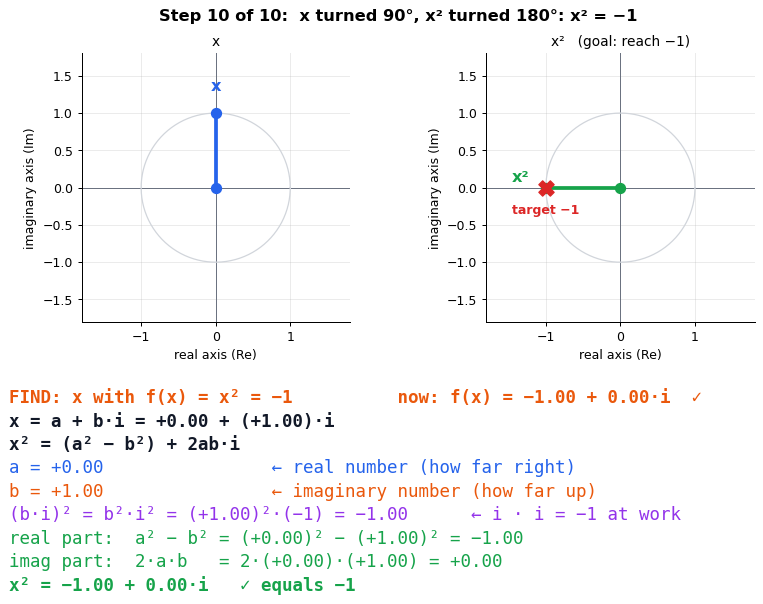

In [1]:
# ---- styling and the plane helper: defined here, reused by every diagram below ----
# pip install numpy matplotlib
import math
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.animation import FuncAnimation, PillowWriter

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# one small colour set used everywhere: blue = z, orange = w, green = result, purple = extra, gray = helper lines
BLUE, ORANGE, GREEN, PURPLE, GRAY, RED = "#2563eb", "#ea580c", "#16a34a", "#9333ea", "#6b7280", "#dc2626"


def new_plane(lim=4, title="", figsize=(5.2, 5.2), ax=None, unit_circle=False, step=None):
    """An empty complex plane: horizontal = real axis, vertical = imaginary axis.
    step=1 puts a tick and a grid line at every whole number, so one grid cell = one step."""
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.axvline(0, color=GRAY, lw=0.8)
    if unit_circle:
        t = np.linspace(0, 2 * np.pi, 300)
        ax.plot(np.cos(t), np.sin(t), color="#d1d5db", lw=1)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    if step:
        ticks = [k * step for k in range(-int(lim // step), int(lim // step) + 1)]
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)
    ax.set_xlabel("real axis (Re)")
    ax.set_ylabel("imaginary axis (Im)")
    ax.set_title(title, fontsize=11)
    return ax


# ---- the example: x² = −1 ----
print("smallest x² + 1 over 2 million real x:", (np.linspace(-1000, 1000, 2_000_001) ** 2 + 1).min(), "  (never 0)")
print("(1j)² =", (1j) ** 2, "  (-1j)² =", (-1j) ** 2)
print("Bombelli: (2+i)³ =", (2 + 1j) ** 3, "  (2+i) + (2-i) =", (2 + 1j) + (2 - 1j), " = 4, a real answer reached through complex numbers")

# ---- dynamic picture, 10 steps: slide x along the real line (steps 1-5), then turn it by 90° (steps 6-10) ----
path = np.array([-1, -0.5, 0, 0.5, 1] + [np.exp(1j * np.radians(d)) for d in (18, 36, 54, 72, 90)], dtype=complex)
FS, ROW, Y0 = 14, 0.0366, 0.385                            # one font size for every formula line; row pitch in figure fraction
num = lambda v: f"{v:+.2f}".replace("-", "−")              # signed number with a proper minus
cx = lambda re, im: f"{num(re)} {'+' if im >= 0 else '−'} {abs(im):.2f}·i"      # complex number as text

fig = plt.figure(figsize=(9, 7.1), dpi=90)
gs = fig.add_gridspec(1, 2, top=0.91, bottom=0.49, left=0.08, right=0.97, wspace=0.28)     # planes: upper part only
axs = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])]
for ax, title in zip(axs, ["x", "x²   (goal: reach −1)"]):
    new_plane(lim=1.8, title=title, ax=ax, unit_circle=True)
axs[1].scatter([-1], [0], marker="X", s=150, color=RED, zorder=3)
axs[1].text(-1, -0.35, "target −1", color=RED, ha="center", fontweight="bold")
lines = [ax.plot([], [], "-o", color=c, lw=3, ms=8)[0] for ax, c in zip(axs, [BLUE, GREEN])]
names = [ax.text(0, 0, s, color=c, fontsize=13, fontweight="bold") for ax, s, c in zip(axs, ["x", "x²"], [BLUE, GREEN])]   # name tags on the arrows

style = dict(family="monospace", fontsize=FS, va="top")                                     # formula block: lower part only
colors = [ORANGE, "#111827", "#111827", BLUE, ORANGE, PURPLE, GREEN, GREEN, GREEN]         # 9 lines, all rewritten at every step
weights = ["bold", "bold", "bold", "normal", "normal", "normal", "normal", "normal", "bold"]
rows = [fig.text(0.02, Y0 - ROW * n, "", color=c, fontweight=w, **style) for n, (c, w) in enumerate(zip(colors, weights))]
status = fig.suptitle("", fontsize=13, fontweight="bold")


def draw(k):
    x = path[k]
    a, b = round(x.real, 2) + 0.0, round(x.imag, 2) + 0.0            # + 0.0 turns -0.0 into 0.0
    re, im = a * a - b * b + 0.0, 2 * a * b + 0.0                      # (a + b·i)² = (a² − b²) + 2ab·i
    for line, name, v in zip(lines, names, [x, x * x]):
        line.set_data([0, v.real], [0, v.imag])
        d = v / abs(v) if abs(v) > 0.05 else 1j                                    # push the name outward, away from the origin
        name.set_position((v.real + 0.22 * d.real, v.imag + 0.22 * d.imag + 0.04))
        name.set_ha("left" if d.real > 0.3 else "right" if d.real < -0.3 else "center")
        name.set_va("top" if d.imag < -0.3 else "bottom")
    for row, text in zip(rows, [
        f"FIND: x with f(x) = x² = −1          now: f(x) = {cx(re, im)}" + ("  ✓" if k == 9 else ""),
        f"x = a + b·i = {num(a)} + ({num(b)})·i",
        "x² = (a² − b²) + 2ab·i",
        f"a = {num(a)}                ← real number (how far right)",
        f"b = {num(b)}                ← imaginary number (how far up)",
        f"(b·i)² = b²·i² = ({num(b)})²·(−1) = {num(-b * b + 0.0)}      ← i · i = −1 at work",
        f"real part:  a² − b² = ({num(a)})² − ({num(b)})² = {num(re)}",
        f"imag part:  2·a·b   = 2·({num(a)})·({num(b)}) = {num(im)}",
        f"x² = {cx(re, im)}" + ("   ✓ equals −1" if k == 9 else ""),
    ]):
        row.set_text(text)
    deg = round(math.degrees(np.angle(x)))
    status.set_text(f"Step {k + 1} of 10:  " + ("x on the real line (b = 0): x² is never −1" if k < 5
                    else "x turned 90°, x² turned 180°: x² = −1" if k == 9 else f"x turned {deg}°, x² turned {2 * deg}°"))
    return lines


anim = FuncAnimation(fig, draw, frames=len(path), interval=1500)

# The JavaScript player of anim.to_jshtml() does not run on GitHub, so the animation is shown in two ways that work everywhere:
#   1) a GIF that loops by itself (saved in assets/, shown in the cell above), and
#   2) every step as an ordinary picture below, so you can read each step at your own pace.
os.makedirs("assets", exist_ok=True)
anim.save("assets/1_1_x_squared_minus_one.gif", writer=PillowWriter(fps=1 / 1.5), dpi=90)
for k in range(len(path)):
    draw(k)
    display(fig)
plt.close(fig)


#### What the animation shows: read the last step line by line

At the last step the lines are `a = 0`, `b = 1`, `i · i = −1`. Each one has a job:

- <b style="color:#2563eb">a = 0</b> is the **real part**. It sets the **horizontal** position (the X axis). Here it is 0, so we do not move sideways.
- <b style="color:#ea580c">b = 1</b> is the **imaginary coefficient**. It sets the **vertical** position (the Y axis). Here we move **1 unit up**.
- <b style="color:#9333ea">i</b> is the **imaginary unit**, defined by `i² = −1`. Multiplying by `i` means **rotate by 90° counter-clockwise**.

**What happens mathematically**

```
x   = 0 + 1·i = i          (a = 0 steps right, b = 1 step up)
x²  = i · i  = i²  = −1
```

**The rotation view: why `x²` lands on −1**

1. Start at **+1** on the real axis.
2. Multiply by `i`: rotate 90° counter-clockwise and arrive at **+i** on the imaginary axis.
3. Multiply by `i` again: rotate another 90° counter-clockwise and arrive at **−1** on the real axis.

Two quarter turns make a half turn, and a half turn takes +1 to −1. That is exactly what the right panel of the animation shows: `x` turns by 90° while `x²` turns twice as fast, by 180°.

#### Step 3 in detail: why `i · i` is always `−1`

This is not something the animation happens to show. It is a **constant**: the same result for every start, every step and every program. Three facts are fixed:

1. **`i` is a quarter turn, always.** `i` has length 1 and angle 90°. Multiplying two complex numbers *multiplies their lengths and adds their angles* (section 1.11). So multiplying by `i` adds exactly 90° and multiplies the length by 1: **a pure turn, no stretching**.
2. **`i · i = i² = −1` by definition.** `i` is *defined* by `i² = −1` (section 1.1), so this is a rule, not a calculation. The angles confirm it: lengths `1 · 1 = 1`, angles `90° + 90° = 180°`. A point of length 1 at angle 180° is `cos 180° + i·sin 180° = −1 + 0i = −1`.
3. **A half turn is `−1`, always.** Multiplying by `−1` turns **any** point by 180° around the origin: `z → −z`. So `i · i` (two quarter turns) and `−1` (one half turn) are the same operation.

> **Why "imaginary", and where does the symbol `i` come from?**
>
> **The name.** *Yes, `i` is the imaginary unit.* The adjective was coined as an insult: René Descartes (1637, *La Géométrie*) called roots of negative numbers *"imaginaires"*: things you can write in an equation but that correspond to no real quantity. The name stuck even though the vertical coordinate `b` in `a + bi` is as real as `a`. Gauss later argued for calling `1`, `−1`, `i` *"direct, inverse, lateral"* units instead; the better name lost to habit.
>
> **The symbol.** Leonhard Euler introduced the letter **`i`** (from Latin *imaginarius*) around **1777**, and it spread through Gauss's use in his 1801 *Disquisitiones Arithmeticae*. Before that, people wrote `√−1` explicitly, which invited sign errors (`√−1 · √−1 ≠ √((−1)(−1)) = 1`).
>
> | Year | Who | What |
> |---|---|---|
> | 1545 | Cardano, *Ars Magna* | Meets square roots of negatives while solving cubics; calls them "sophistic" and useless, but uses them. |
> | 1572 | Bombelli | First consistent rules for computing with `√−1`; shows a cubic with three *real* roots can only be reached *through* complex intermediates. |
> | 1637 | Descartes | Coins "imaginary" as an insult. |
> | 1748 | Euler | `e^{iθ} = cos θ + i sin θ` (section 1.10). |
> | ~1777 | Euler | Introduces the symbol `i`. |
> | 1797 / 1806 | Wessel / Argand | Geometric picture: complex numbers as points in the plane. |
> | 1831 | Gauss | Popularises the complex plane and the name "complex number". |
> | 1843 | Hamilton | Defines complex numbers as ordered pairs `(a, b)` with a multiplication rule, with no mysterious `√−1` needed. |
>
> **Convention check.** Mathematicians and physicists write `i`; electrical engineers write `j` (because `i` means current). Python follows the engineers: `1j`, not `1i`. In quantum computing `i` is also easy to confuse with an *index* (`Σᵢ`, `|i⟩`); context tells them apart.

### 1.2 Real part

$$z = a + bi$$

- `z` — the complex number
- `a` — the **real part**: the horizontal coordinate ("how far **right**")
- `b` — the imaginary part (next section)
- `i` — the imaginary unit

For `z = 3 + 2i` the real part is `a = 3`. In Python: **`z.real`** (a normal float).

A real number is just a complex number with imaginary part 0, so the real number line is the horizontal axis *inside* the plane. Taking the real part means **dropping a vertical line from the point onto the real axis**.

z.real  = 3.0    type: float


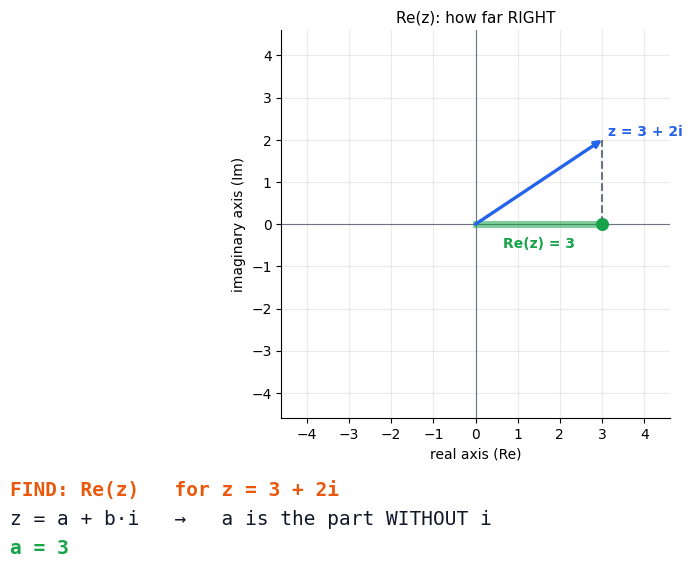

In [2]:
# ---- helpers for the formula strip under every example (reused below) ----
def cstr(z, nd=0):
    """Format a complex number as text: 3 + 2i, −2 + 3i, 0.50 − 1.25i."""
    return f"{z.real:.{nd}f}".replace("-", "−") + (" + " if z.imag >= 0 else " − ") + f"{abs(z.imag):.{nd}f}i"


def show_steps(goal, lines, fs=14, max_h=4.6, tight=True):
    """Big, readable strip under the current figure: one FIND line, then one line per step (same font size)."""
    fig = plt.gcf()
    w, h = fig.get_size_inches()
    w, h = max(w, 9.5), min(h, max_h)
    pitch = fs * 1.5 / 72                                  # inches per text line
    strip = pitch * (len(lines) + 1) + 0.3
    fig.set_size_inches(w, h + strip)
    frac = strip / (h + strip)
    if tight:
        fig.set_layout_engine("constrained", rect=(0, frac, 1, 1 - frac))
    else:
        fig.subplots_adjust(bottom=frac + 0.07)
    top = lambda n: (strip - 0.15 - pitch * n) / (h + strip)
    fig.text(0.01, top(0), goal, color=ORANGE, fontweight="bold", fontsize=fs, family="monospace", va="top")
    for n, line in enumerate(lines, 1):
        last = n == len(lines)
        fig.text(0.01, top(n), line, color=GREEN if last else "#111827", fontweight="bold" if last else "normal",
                 fontsize=fs, family="monospace", va="top")


# ---- helper that draws a complex number as an arrow (reused below) ----
def draw_arrow(ax, tip, color=BLUE, label=None, tail=0, lw=2.4, linestyle="-", offset=(0.12, 0.12), alpha=1.0, ha="left"):
    """Draw the complex number `tip` as an arrow (optionally starting at `tail`)."""
    tail, tip = complex(tail), complex(tip)
    ax.annotate("", xy=(tip.real, tip.imag), xytext=(tail.real, tail.imag),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, linestyle=linestyle, alpha=alpha, shrinkA=0, shrinkB=0))
    if label:
        ax.text(tip.real + offset[0], tip.imag + offset[1], label, color=color, fontweight="bold", ha=ha)


z = 3 + 2j
print("z.real  =", z.real, "   type:", type(z.real).__name__)

ax = new_plane(lim=4.6, title="Re(z): how far RIGHT", figsize=(5.4, 5.2), step=1)
draw_arrow(ax, z, BLUE, "z = 3 + 2i", offset=(0.15, 0.1))
ax.plot([z.real, z.real], [0, z.imag], "--", color=GRAY)                 # drop line
ax.plot([0, z.real], [0, 0], color=GREEN, lw=5, alpha=0.55)              # the part we keep
ax.scatter([z.real], [0], color=GREEN, s=70, zorder=4)
ax.text(z.real / 2, -0.55, "Re(z) = 3", color=GREEN, ha="center", fontweight="bold")
show_steps(f"FIND: Re(z)   for z = {cstr(z)}", [
    "z = a + b·i   →   a is the part WITHOUT i",
    f"a = {z.real:g}"])

plt.show()

### 1.3 Imaginary part

- `b` in `z = a + bi` — the **imaginary part**: the vertical coordinate ("how far **up**")

For `z = 3 + 2i` the imaginary part is `b = 2`. In Python: **`z.imag`**.

Two things beginners trip over:
- **`b` is an ordinary real number** (a float). The *imaginary part* is `2`, not `2i`; the `i` only marks which axis it belongs to.
- Taking the imaginary part means **dropping a horizontal line from the point onto the vertical axis**.
- In code, `3 + 2j` uses `j` and no space between the number and `j`: `2j` is a literal, `2 j` is a syntax error, and the bare name `j` means a variable. Use `1j` for `i`.

**Next:** what the imaginary unit `i` itself does to a point (section 1.4).

z.imag  = 2.0    type: float    <- a plain float, not 2j


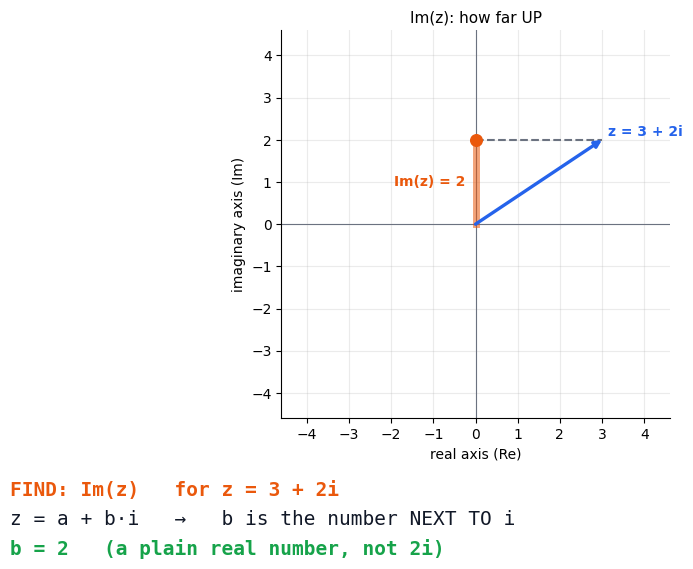

In [3]:
z = 3 + 2j
print("z.imag  =", z.imag, "   type:", type(z.imag).__name__, "   <- a plain float, not 2j")

ax = new_plane(lim=4.6, title="Im(z): how far UP", figsize=(5.4, 5.2), step=1)
draw_arrow(ax, z, BLUE, "z = 3 + 2i", offset=(0.15, 0.1))
ax.plot([0, z.real], [z.imag, z.imag], "--", color=GRAY)                 # drop line
ax.plot([0, 0], [0, z.imag], color=ORANGE, lw=5, alpha=0.55)             # the part we keep
ax.scatter([0], [z.imag], color=ORANGE, s=70, zorder=4)
ax.text(-0.25, z.imag / 2, "Im(z) = 2", color=ORANGE, ha="right", va="center", fontweight="bold")
show_steps(f"FIND: Im(z)   for z = {cstr(z)}", [
    "z = a + b·i   →   b is the number NEXT TO i",
    f"b = {z.imag:g}   (a plain real number, not {z.imag:g}i)"])

plt.show()

### 1.4 What does `i` do? The imaginary unit is a quarter turn

<div style="border-left: 5px solid #dc2626; background: rgba(220, 38, 38, 0.10); padding: 10px 16px; border-radius: 4px;">

<b style="color:#dc2626">🔴 HINT</b>: what kind of number is `i`? It is a number, but not a single decimal like `π`, and it is not only geometry.

1. **A fixed number with a pair of values.** 
`π` lives on the real number line and has one decimal.  `i` lives off the line, on the plane, so it needs **two numbers**:

    | | `π` | `i` |
    |---|---|---|
    | Lives on | the real number line | the plane, off the line |
    | Numeric form | one decimal: `3.14159...` | a pair: `(0, 1)`, i.e. `0 + 1·i` |
    | Python | `math.pi` | `1j` (`complex(0, 1)`) |

    No real number squares to −1, so no single real decimal can represent `i`. It is still a fixed value: you can store it, add it and multiply it in code.

2. **Not "only geometry".** `i` is defined by an algebraic rule, `i² = −1`. The 90° turn is what that rule looks like on the plane. Multiplying pairs, `(a, b)·(c, d) = (ac − bd, ad + bc)`, gives `(0, 1)·(a, b) = (−b, a)`, which is the 90° turn. Geometry and algebra describe the same object.

3. **It turns, it does not flip.** Multiplying by `i` rotates a point 90° counter-clockwise. "Flip" in this notebook means a sign flip (conjugation, section 1.8) or a 180° turn (`−1`).

4. **A numeric form with no complex type: a 2×2 matrix.** `i` can be written as the 90° rotation matrix:

**Multiplying by `i` rotates a point by exactly 90° counter-clockwise** around the origin. Nothing else: no stretching (its length is 1) and no flipping.

Example: for function `f = i * z` where `z = 3 + 2i`. In code, `1j * z` gives `-2 + 3j`: the point (3, 2) moved to (−2, 3).

In plain pair notation the rule is `(a, b) → (−b, a)`: swap the two numbers and negate the first. A programmer's version: `rotate90 = lambda a, b: (-b, a)`.

| Multiply by | Geometric effect |
|---|---|
| 1 | nothing |
| `i` | turn 90° |
| `i · i = −1` | turn 90° twice = **180°** = jump to the opposite side of the origin |
| `i · i · i = −i` | turn 270° (= 90° clockwise) |
| `i · i · i · i = 1` | full 360°, back where you started |

**This is why `i² = −1` is not mysterious.** "Multiply by −1" means "go to the opposite side of the origin", which is a half turn. Ask *"what do I apply twice to get a half turn?"* and the answer is obvious: a **quarter turn**. So `i` is the quarter turn, and `i · i = −1` just says that two quarter turns make a half turn. That is also the geometric answer to the equation from 1.1.

<b style="color:#ea580c">**The imaginary axis is purely geometric.**</b> "Imaginary" is a historical label, not a description. The vertical axis is simply *the direction perpendicular to the real line*, a second coordinate like `y` next to `x`. `2i` means "2 steps in the perpendicular direction", exactly as real as 2 steps to the right.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: start at `z = 3 + 2i` and multiply by `i` four times. Where do we land after each step?

</div>

**▶ The animation.** It loops by itself. The same four steps are also shown one by one as pictures under the code cell below.

![Four steps: z = 3 + 2i is multiplied by i four times, a quarter turn each time, and returns to the start](assets/1_4_multiply_by_i.gif)

z, i·z, i²·z, i³·z, i⁴·z = (3+2j) (-2+3j) (-3-2j) (2-3j) (3+2j)
length after every turn  = [3.606, 3.606, 3.606, 3.606, 3.606]   (a pure rotation never changes it)


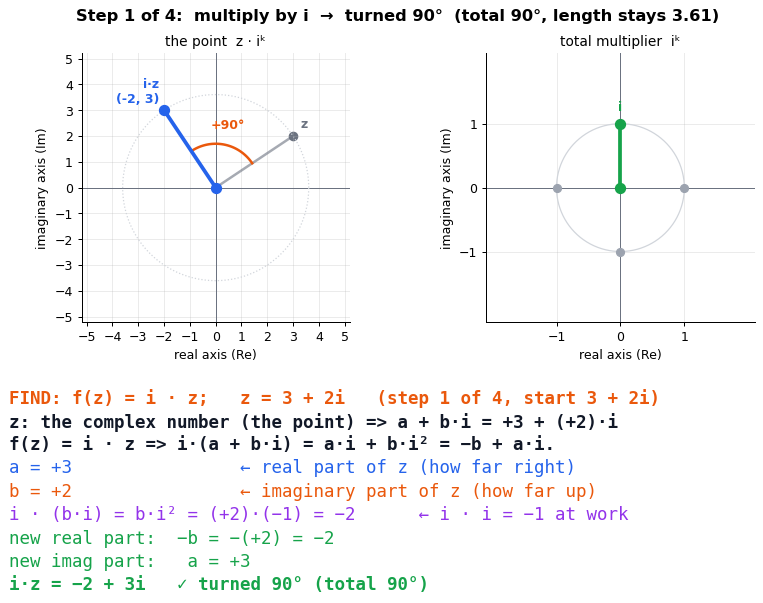

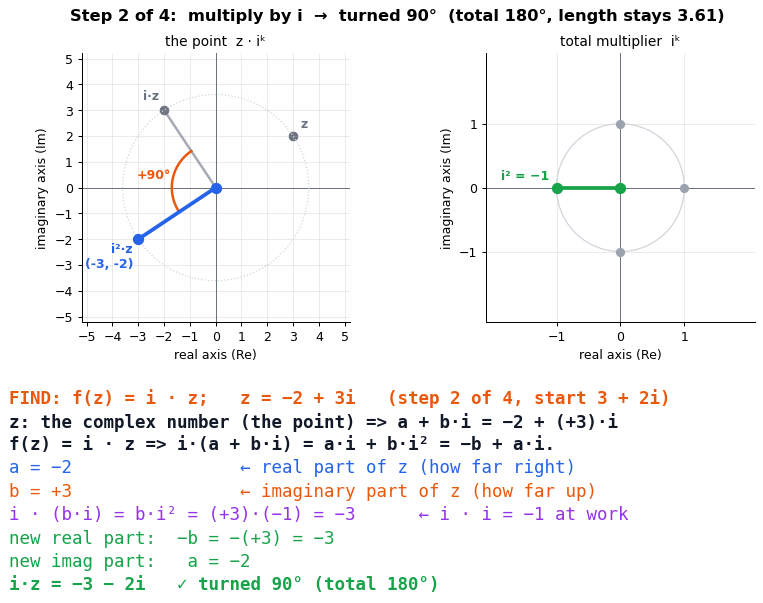

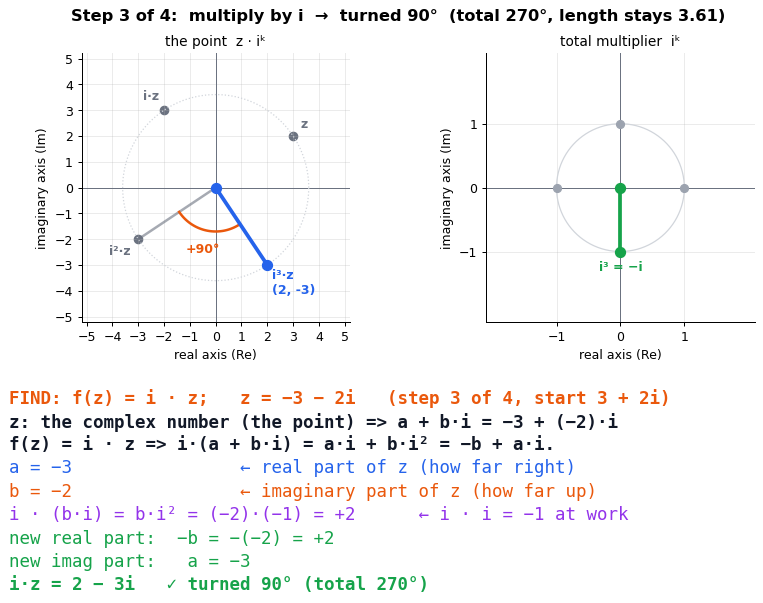

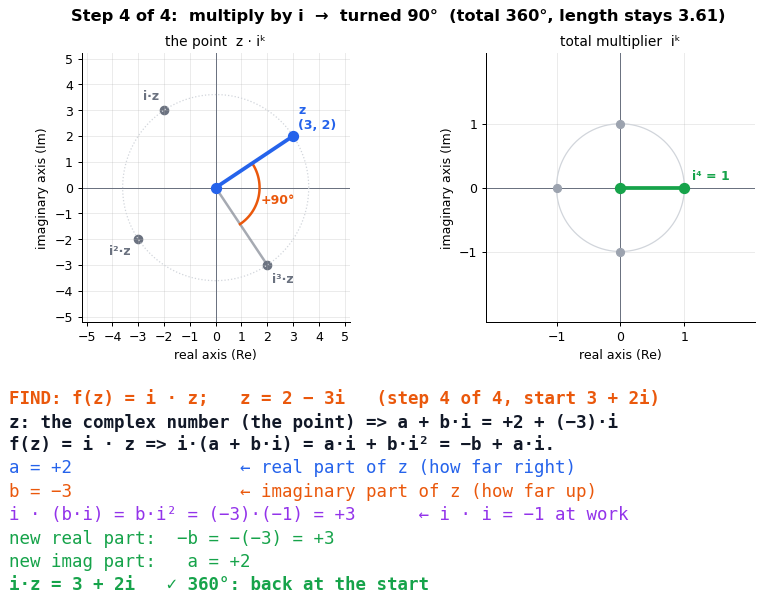

In [4]:
# ---- the example: start at z = 3 + 2i and multiply by i four times ----
z = 3 + 2j
print("z, i·z, i²·z, i³·z, i⁴·z =", *[complex(z * 1j ** k) for k in range(5)])
print("length after every turn  =", [round(abs(z * 1j ** k), 3) for k in range(5)], "  (a pure rotation never changes it)")

# ---- dynamic picture, 4 steps: every step multiplies the current point by i ----
FS, ROW, Y0 = 14, 0.0366, 0.385                            # same font size and layout as the first example
inum = lambda v: f"{v:+.0f}".replace("-", "−")              # signed whole number with a proper minus
pts = [z * (1j) ** k for k in range(5)]                    # z, i·z, i²·z, i³·z, i⁴·z (= z again)
names = ["z", "i·z", "i²·z", "i³·z", "z"]
mult_names = ["", "i", "i² = −1", "i³ = −i", "i⁴ = 1"]
mult_pos = [None, (0, 1.15, "center", "bottom"), (-1.12, 0.08, "right", "bottom"), (0, -1.15, "center", "top"), (1.12, 0.08, "left", "bottom")]

fig = plt.figure(figsize=(9, 7.1), dpi=90)
gs = fig.add_gridspec(1, 2, top=0.91, bottom=0.49, left=0.08, right=0.97, wspace=0.28)
axL, axR = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
new_plane(lim=5.2, title="the point  z · iᵏ", ax=axL)
new_plane(lim=2.1, title="total multiplier  iᵏ", ax=axR, unit_circle=True)
axL.set_xticks(range(-5, 6)); axL.set_yticks(range(-5, 6))                                   # a tick at every whole number
axR.set_xticks([-1, 0, 1]); axR.set_yticks([-1, 0, 1])
t = np.linspace(0, 2 * np.pi, 300)
axL.plot(abs(z) * np.cos(t), abs(z) * np.sin(t), ":", color="#d1d5db", lw=1)              # the circle the point travels on
axR.scatter([1, 0, -1, 0], [0, 1, 0, -1], color="#9ca3af", s=40, zorder=2)                 # the four possible multipliers

ghost, = axL.plot([], [], "-", color=GRAY, lw=2, alpha=0.6)                                # previous position
cur, = axL.plot([], [], "-o", color=BLUE, lw=3, ms=8, zorder=4)                                      # current position
arc, = axL.plot([], [], "-", color=ORANGE, lw=2)                                           # the 90° turn
trail = axL.scatter([], [], color=GRAY, s=45, zorder=1.5)
point_label = axL.text(0, 0, "", color=BLUE, fontweight="bold")
trail_labels = [axL.text(0, 0, "", color=GRAY, fontweight="bold") for _ in range(4)]          # names of the visited points
arc_label = axL.text(0, 0, "", color=ORANGE, fontweight="bold", ha="center", va="center")
curR, = axR.plot([], [], "-o", color=GREEN, lw=3, ms=8, zorder=4)
mult_label = axR.text(0, 0, "", color=GREEN, fontweight="bold", ha="center")

style = dict(family="monospace", fontsize=FS, va="top")
colors = [ORANGE, "#111827", "#111827", BLUE, ORANGE, PURPLE, GREEN, GREEN, GREEN]         # 9 lines, all rewritten at every step
weights = ["bold", "bold", "bold", "normal", "normal", "normal", "normal", "normal", "bold"]
rows = [fig.text(0.02, Y0 - ROW * n, "", color=c, fontweight=w, **style) for n, (c, w) in enumerate(zip(colors, weights))]
status = fig.suptitle("", fontsize=13, fontweight="bold")


def draw(k):                                               # k = 0..3  ->  step k + 1
    prev, new = pts[k], pts[k + 1]
    a, b = prev.real, prev.imag
    ghost.set_data([0, prev.real], [0, prev.imag])
    cur.set_data([0, new.real], [0, new.imag])
    trail.set_offsets([[p.real, p.imag] for p in pts[:k + 1]])
    a0 = np.angle(prev)
    r_arc = 1.7
    arc.set_data(r_arc * np.cos(np.linspace(a0, a0 + np.pi / 2, 40)), r_arc * np.sin(np.linspace(a0, a0 + np.pi / 2, 40)))
    arc_label.set_position((2.45 * np.cos(a0 + np.pi / 4), 2.45 * np.sin(a0 + np.pi / 4)))
    arc_label.set_text("+90°")
    left = new.real < 0
    point_label.set_position((new.real + (-0.2 if left else 0.2), new.imag + (0.3 if new.imag >= 0 else -1.1)))
    point_label.set_ha("right" if left else "left")
    point_label.set_text(f"{names[k + 1]}\n({new.real:.0f}, {new.imag:.0f})")
    for j, tl in enumerate(trail_labels):                  # visited points get their name, unless the current point sits on top of them
        p = pts[j]
        d = p / abs(p)
        tl.set_position((p.real + 0.35 * d.real, p.imag + 0.35 * d.imag))
        tl.set_ha("left" if d.real > 0.3 else "right" if d.real < -0.3 else "center")
        tl.set_va("top" if d.imag < -0.3 else "bottom")
        tl.set_text(names[j] if j <= k and abs(p - new) > 1e-9 else "")
    m = (1j) ** (k + 1)
    curR.set_data([0, m.real], [0, m.imag])
    mx, my, mha, mva = mult_pos[k + 1]
    mult_label.set_position((mx, my)); mult_label.set_ha(mha); mult_label.set_va(mva)
    mult_label.set_text(mult_names[k + 1])
    for row, text in zip(rows, [
        f"FIND: f(z) = i · z;   z = {cstr(prev)}   (step {k + 1} of 4, start {cstr(z)})",
        f"z: the complex number (the point) => a + b·i = {inum(a)} + ({inum(b)})·i",
        "f(z) = i · z => i·(a + b·i) = a·i + b·i² = −b + a·i. ",
        f"a = {inum(a)}                ← real part of z (how far right)",
        f"b = {inum(b)}                ← imaginary part of z (how far up)",
        f"i · (b·i) = b·i² = ({inum(b)})·(−1) = {inum(-b)}      ← i · i = −1 at work",
        f"new real part:  −b = −({inum(b)}) = {inum(-b)}",
        f"new imag part:   a = {inum(a)}",
        f"i·z = {cstr(new)}" + ("   ✓ 360°: back at the start" if k == 3 else f"   ✓ turned 90° (total {90 * (k + 1)}°)"),
    ]):
        row.set_text(text)
    status.set_text(f"Step {k + 1} of 4:  multiply by i  →  turned 90°  (total {90 * (k + 1)}°, length stays {abs(z):.2f})")
    return cur, ghost, arc, curR


anim = FuncAnimation(fig, draw, frames=4, interval=2000)

# Same two views as in 1.1: a GIF that loops by itself (shown in the cell above) and every step as an ordinary picture.
os.makedirs("assets", exist_ok=True)
anim.save("assets/1_4_multiply_by_i.gif", writer=PillowWriter(fps=1 / 2.0), dpi=90)
for k in range(4):
    draw(k)
    display(fig)
plt.close(fig)


#### What the animation shows: four steps, four quarter turns

Each step calls `f(z) = i · z` on the current point. `z` is just a name for the input (after `z = 3 + 2j`, `f(z)` is the same call as `f(3 + 2j)`), and the result of one call is the input of the next.

| Step | Call | What `f(z) = i · z` does | Result | turn |
|---|-------------|---|---|---|
| 1 | `f(3 + 2i)` | `i·(3 + 2i) = 3i + 2i² = −2 + 3i` | `−2 + 3i` | 90° |
| 2 | `f(−2 + 3i)` | `i·(−2 + 3i) = −2i + 3i² = −3 − 2i` | `−3 − 2i` | 180° |
| 3 | `f(−3 − 2i)` | `i·(−3 − 2i) = −3i − 2i² = 2 − 3i` | `2 − 3i` | 270° |
| 4 | `f(2 − 3i)` | `i·(2 − 3i) = 2i − 3i² = 3 + 2i` | `3 + 2i` | 360°, back at the start |

- Inside `f`, with `z = a + b·i`: `i·z = −b + a·i` because `i² = −1`. So `(a, b) → (−b, a)`, a 90° turn.
- Grey dots are visited points, the blue dot is the new one. The length never changes (circle of radius √13 ≈ 3.61).
- Right plane: total multiplier `i`, `i² = −1`, `i³ = −i`, `i⁴ = 1`.

**The same four steps in plain Python:**

In [5]:
# No import is needed.
# Complex numbers are built into standard Python, like int and float.
# 2j is a literal. 
# 3 + 2j is a complex number written directly in code, the same way 2.5 is a float.

def f(z):
    return 1j * z          # multiply by i

z = 3 + 2j
for step in range(1, 5):
    z = f(z)
    print(step, z)

1 (-2+3j)
2 (-3-2j)
3 (2-3j)
4 (3+2j)


In [6]:
# The same logic WITHOUT the built-in complex type and without 1j:
# a complex number is two floats, "j" is our own constant (0, 1), and one multiplication rule does the rest.

class Complex:
    def __init__(self, re, im):
        self.re, self.im = re, im

    def __add__(self, other):                  # two separate sums: re + re, im + im
        return Complex(self.re + other.re, self.im + other.im)

    def __sub__(self, other):                  # two separate differences: re - re, im - im
        return Complex(self.re - other.re, self.im - other.im)

    def __mul__(self, other):                  # (a + bj)(c + dj) = (ac - bd) + (ad + bc)j
        return Complex(self.re * other.re - self.im * other.im,
                       self.re * other.im + self.im * other.re)

    def __repr__(self):                        # print it like Python does: (3+2j)
        return f"({self.re:g}{self.im:+g}j)"

def f(z):
    return i * z

i = Complex(0, 1) # our own imaginary unit: the point (0, 1)
z = Complex(3, 2)
for step in range(1, 5):
    z = f(z)
    print(step, z)

1 (-2+3j)
2 (-3-2j)
3 (2-3j)
4 (3+2j)


#### `i` is a constant: what never changes, and what you transform

`i` is not a variable. It is a **fixed number**, like `π` or `e`: one value, the same in every formula, every step and every program. In `f(z) = i · z` the two names play different roles:

- **`z` is the variable**: the input. It changes from call to call (`3 + 2i`, then `−2 + 3i`, ...).
- **`i` is the constant**: the same point `(0, 1)` in every step.

**Details of the constant `i`**


- **In Python** `1j` is a literal, so it is always this constant. The name `i` is **not** special in Python (it is usually a loop counter), so write `1j`, not `i`.
- **Do not treat `√−1` as an ordinary square root.** It is only another spelling of `i`; what you compute with is the rule `i² = −1`.

**Transformations: you change `z`, never `i`.** A transformation is a function `f(z)` whose logic combines the variable `z` with constants:

| Transformation | Constant inside | Effect on the point |
|---|---|---|
| `i · z` | `i` | turn 90° |
| `i² · z = −z` | `i² = −1` | turn 180° |
| `z + i` | `i` | shift up by 1 (a shift, not a turn) |
| `z*` (conjugate) | none | mirror across the real axis (the same as swapping `i` for `−i`) |

**Example: conjugating `z = 3 + 2i` with the constant written out**

1. **Original number:** `z = 3 + 2i`
2. **Replace `i` with its definition** (same constant, other spelling): `z = 3 + 2·√−1`
3. **Apply the transformation:** change the sign of the imaginary part: `z* = 3 − 2·√−1`
4. **Write it with `i` again:** `z* = 3 − 2i`
5. **Result:** `(3, 2) → (3, −2)`

$$\boxed{(a + bi)^* = a - bi}$$

The constant `i` is the same before and after (`(0, 1)`, `i² = −1`). Only the number `z` changed: the sign of its imaginary part. Conjugation is explained in section 1.8.

### 1.5 Complex addition and subtraction

Add or subtract **part by part**, like 2D vectors:

$$(a + bi) \pm (c + di) = (a \pm c) + (b \pm d)i$$

`a, c` are the real parts, `b, d` the imaginary parts. In Python: **`z + w`** and **`z - w`**.

**The idea:** two separate calculations that never mix. Real parts only meet real parts, imaginary parts only meet imaginary parts.

| Operation | Real part | Imaginary part | Picture |
|---|---|---|---|
| `z + w` | real + real: `a + c` | imaginary + imaginary: `b + d` | **slide**: walk along `z`, then along `w` (tip to tail) |
| `z − w` | real − real: `a − c` | imaginary − imaginary: `b − d` | the arrow **from the tip of `w` to the tip of `z`**, the same as `z + (−w)` where `−w` is `w` turned 180° |

For `z = 3 + 1i` and `w = 1 + 2i`: `z + w = (3 + 1) + (1 + 2)i = 4 + 3i` and `z − w = (3 − 1) + (1 − 2)i = 2 − 1i`.

Why it matters later: amplitudes are **added** before they are squared, and arrows pointing in different directions can reinforce or cancel (*interference*, section 1.13).

z + w = (4+3j)    (real: 3+1 = 4, imaginary: 1+2 = 3)
z - w = (2-1j)    (real: 3-1 = 2, imaginary: 1-2 = -1)


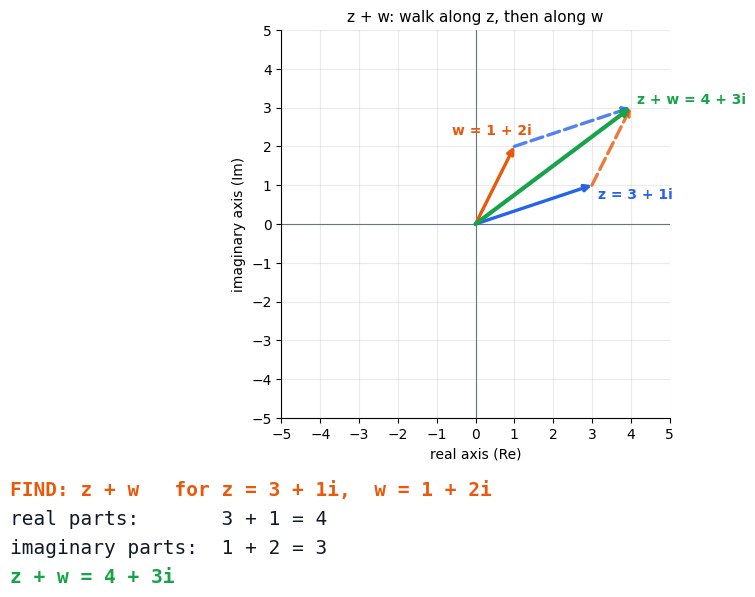

In [7]:
z, w = 3 + 1j, 1 + 2j
print("z + w =", z + w, "   (real: 3+1 = 4, imaginary: 1+2 = 3)")
print("z - w =", z - w, "   (real: 3-1 = 2, imaginary: 1-2 = -1)")

ax = new_plane(lim=5, title="z + w: walk along z, then along w", figsize=(5.8, 5.4), step=1)
draw_arrow(ax, z, BLUE, "z = 3 + 1i", offset=(0.15, -0.35))
draw_arrow(ax, w, ORANGE, "w = 1 + 2i", offset=(-1.6, 0.3))
draw_arrow(ax, z + w, ORANGE, tail=z, linestyle="--", alpha=0.8)              # w copied to the tip of z
draw_arrow(ax, z + w, BLUE, tail=w, linestyle="--", alpha=0.8)                # z copied to the tip of w
draw_arrow(ax, z + w, GREEN, "z + w = 4 + 3i", lw=3, offset=(0.15, 0.1))
show_steps(f"FIND: z + w   for z = {cstr(z)},  w = {cstr(w)}", [
    f"real parts:       {z.real:g} + {w.real:g} = {(z + w).real:g}",
    f"imaginary parts:  {z.imag:g} + {w.imag:g} = {(z + w).imag:g}",
    f"z + w = {cstr(z + w)}"])

plt.show()

### 1.6 Magnitude (modulus)

$$|z| = \sqrt{a^2 + b^2}$$

- `|z|` — the **magnitude** (also called modulus or absolute value) of `z`
- `a` — the real part, `b` — the imaginary part
- `a² + b²` — Pythagoras: the two legs of a right triangle squared and added
- `√` — take the square root to get the hypotenuse, i.e. the **length of the arrow** from the origin to the point

It is always a real number ≥ 0, and it is the same thing as `np.linalg.norm([a, b])`. In Python: **`abs(z)`**.

Example: `z = 3 + 4i` has `|z| = 5` (the classic 3-4-5 triangle). All numbers with the same magnitude sit on the same **circle** around the origin.

<span style="color:#dc2626">**What it is for.** It turns a complex number (two numbers) into **one real number: how big it is**, ignoring the direction. Use it whenever the question is "how much / how far / how strong", not "which way".</span>

**When to use it:**
- **Strength of a signal or amplitude:** how strong a radio wave, a sound or a quantum amplitude is. The phase (direction) does not matter here.
- **Distance between two points:** `|z − w|` is the distance between `z` and `w` (subtraction from 1.5). For `z = 3 + 1i` and `w = 1 + 2i`: `|2 − 1i| = √5 ≈ 2.24`.
- **Probability:** for a quantum amplitude, **`|z|²` is the probability** of a measurement result (section 1.12).
- **Making the length 1:** `z / |z|` keeps the direction and sets the length to 1. For `z = 3 + 4i`: `(3 + 4i) / 5 = 0.6 + 0.8i`. A qubit state must have total length 1.
- **Comparing:** complex numbers <span style="color:#dc2626">**cannot be ordered with `<`, but their magnitudes can: `|z| < |w|`. Also used for the size of an error, `|computed − expected|`.**</span>

If the direction matters, use the phase instead (section 1.7).

abs(z)                = 5.0
sqrt(a^2 + b^2)       = 5.0
np.linalg.norm([a,b]) = 5.0


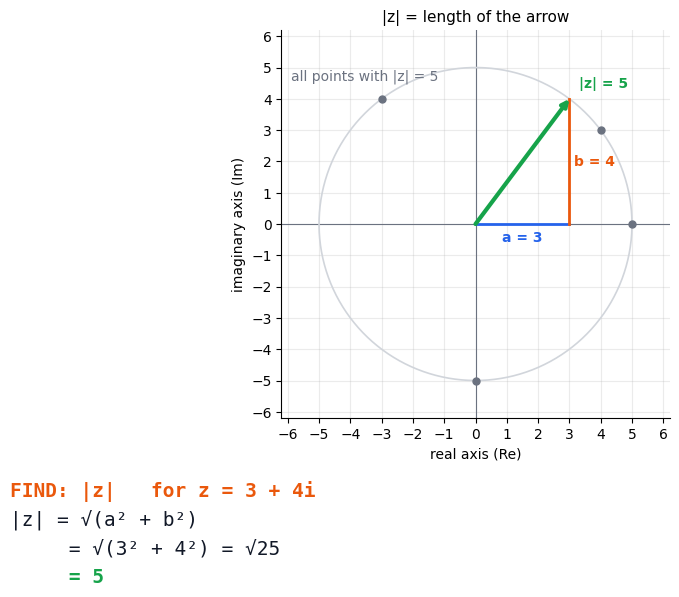

In [8]:
z = 3 + 4j
print("abs(z)                =", abs(z))
print("sqrt(a^2 + b^2)       =", math.sqrt(z.real**2 + z.imag**2))
print("np.linalg.norm([a,b]) =", np.linalg.norm([z.real, z.imag]))

ax = new_plane(lim=6.2, title="|z| = length of the arrow", figsize=(5.8, 5.6), step=1)
t = np.linspace(0, 2 * np.pi, 300)
ax.plot(5 * np.cos(t), 5 * np.sin(t), color="#d1d5db", lw=1.2)
ax.text(-5.9, 4.6, "all points with |z| = 5", color=GRAY)
for p in (5, 4 + 3j, -3 + 4j, -5j):
    ax.scatter([complex(p).real], [complex(p).imag], color=GRAY, s=25, zorder=3)
ax.plot([0, z.real], [0, 0], color=BLUE, lw=2)
ax.plot([z.real, z.real], [0, z.imag], color=ORANGE, lw=2)
draw_arrow(ax, z, GREEN, lw=3)
ax.text(1.5, -0.55, "a = 3", color=BLUE, ha="center", fontweight="bold")
ax.text(3.15, 2.0, "b = 4", color=ORANGE, va="center", fontweight="bold")
ax.text(3.3, 4.35, "|z| = 5", color=GREEN, fontweight="bold")
show_steps(f"FIND: |z|   for z = {cstr(z)}", [
    "|z| = √(a² + b²)",
    f"     = √({z.real:g}² + {z.imag:g}²) = √{z.real ** 2 + z.imag ** 2:g}",
    f"     = {abs(z):g}"])

plt.show()

### 1.7 Phase (argument)

#### What is the phase?

The **phase** (also *argument*, `arg z`) is **the angle of the arrow**, measured from the positive real axis, counter-clockwise, in **radians** (π radians = 180°).

- **Where it starts:** the positive real axis, the direction of the number `1`. The phase of `1` is `0`.
- **Which way:** counter-clockwise is positive, clockwise is negative. `i` (straight up) has phase `+90°`, `−i` (straight down) has `−90°`.
- **What a radian is:** on a circle of radius 1, the angle in radians is the **length of the arc** you walk. A full circle is 2π ≈ 6.28 long, so a full turn is `2π`, a half turn is `π ≈ 3.14` and a quarter turn is `π/2 ≈ 1.57`. Degrees are the same angle in another unit: `1 rad ≈ 57.3°`.
- **Only the direction counts:** the length is ignored. `1 + i`, `2 + 2i` and `10 + 10i` all have phase 45° (`π/4`).
- **One direction, many angles:** adding a full turn changes nothing, so 30°, 390° and −330° are the same direction. Code returns the one between −π and π.

np.angle(z)     = 0.6435 rad = 36.87 deg
np.angle(2 * z) = 0.6435 rad   <- twice as long, same phase: only the direction counts
one full turn   = 6.2832 rad = 360 deg;   1 rad = 57.3 deg


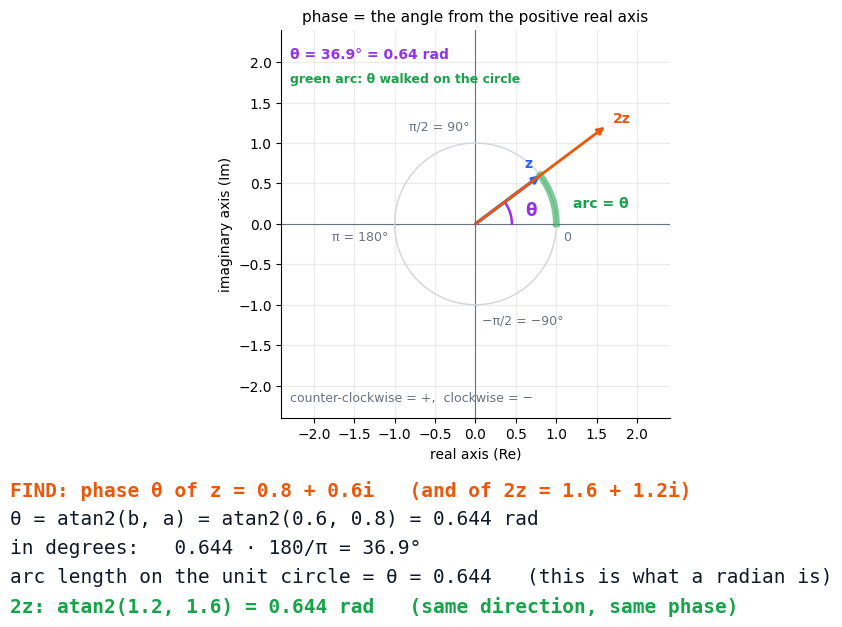

In [9]:
z = 0.8 + 0.6j                                  # length 1, so its tip sits on the unit circle
print("np.angle(z)     =", round(np.angle(z), 4), "rad =", round(np.degrees(np.angle(z)), 2), "deg")
print("np.angle(2 * z) =", round(np.angle(2 * z), 4), "rad   <- twice as long, same phase: only the direction counts")
print("one full turn   =", round(2 * np.pi, 4), "rad = 360 deg;   1 rad =", round(np.degrees(1), 2), "deg")

theta = np.angle(z)
ax = new_plane(lim=2.4, title="phase = the angle from the positive real axis", figsize=(5.8, 5.6), unit_circle=True, step=0.5)
draw_arrow(ax, z, BLUE, "z", offset=(-0.2, 0.1))
draw_arrow(ax, 2 * z, ORANGE, "2z", lw=2, offset=(0.1, 0.05))
a = np.linspace(0, theta, 60)
ax.plot(0.45 * np.cos(a), 0.45 * np.sin(a), color=PURPLE, lw=1.8)             # the angle itself
ax.plot(np.cos(a), np.sin(a), color=GREEN, lw=5, alpha=0.55)                  # the same angle as a length on the unit circle
ax.text(0.62, 0.1, "θ", color=PURPLE, fontweight="bold", fontsize=12)
ax.text(1.2, 0.2, "arc = θ", color=GREEN, fontweight="bold")
for x, y, label, ha, va in [(1.08, -0.08, "0", "left", "top"), (-0.08, 1.12, "π/2 = 90°", "right", "bottom"),
                            (-1.08, -0.08, "π = 180°", "right", "top"), (0.08, -1.12, "−π/2 = −90°", "left", "top")]:
    ax.text(x, y, label, color=GRAY, ha=ha, va=va, fontsize=9)
ax.text(-2.3, 2.05, f"θ = {np.degrees(theta):.1f}° = {theta:.2f} rad", color=PURPLE, fontweight="bold")
ax.text(-2.3, 1.75, "green arc: θ walked on the circle", color=GREEN, fontweight="bold", fontsize=9)
ax.text(-2.3, -2.2, "counter-clockwise = +,  clockwise = −", color=GRAY, fontsize=9)

show_steps(f"FIND: phase θ of z = {cstr(z, 1)}   (and of 2z = {cstr(2 * z, 1)})", [
    f"θ = atan2(b, a) = atan2({z.imag:g}, {z.real:g}) = {theta:.3f} rad",
    f"in degrees:   {theta:.3f} · 180/π = {math.degrees(theta):.1f}°",
    f"arc length on the unit circle = θ = {theta:.3f}   (this is what a radian is)",
    f"2z: atan2({(2 * z).imag:g}, {(2 * z).real:g}) = {np.angle(2 * z):.3f} rad   (same direction, same phase)"])

plt.show()

**How to read the picture.**
- The **purple arc** is the angle `θ` between the positive real axis and the arrow `z`, counter-clockwise.
- The **green arc** is the same angle as a *length*: the piece of the unit circle you walk from `1` to the tip of `z`. Its length is `θ` in radians.
- `z` and `2z` lie on the same ray, so they have the same phase. <span style="color:#dc2626">The phase says **how far the arrow is turned** from the positive real axis (the angle). It says nothing about the length: that is the magnitude (section 1.6).</span>
- The grey labels mark four directions to remember: `0`, `π/2`, `π`, `−π/2`.

$$\theta = \operatorname{atan2}(b,\, a)$$

- `θ` (theta) — the phase; `a` — the real part, `b` — the imaginary part
- `atan2` — the two-argument arctangent: it looks at the signs of both `a` and `b`, so it knows the quadrant

In Python: **`np.angle(z)`** (or `cmath.phase(z)`), in radians between −π and π. `np.degrees(...)` converts to degrees.

| Number | Radians | Degrees |
|---|---|---|
| `1` | 0 | 0° |
| `i` | π/2 | 90° |
| `−1` | π | 180° |
| `−i` | −π/2 | −90° |

**Pitfall.** Plain `atan(b / a)` cannot tell `3 + 2i` from `−3 − 2i` (same ratio), so it is wrong in two of the four quadrants, and it divides by zero when `a = 0`. Use `atan2`.

#### How `atan2` works

**Yes, it is the arctangent** (the inverse of the tangent) with a fix. `atan(t)` answers "which angle has tangent `t`?", but it only sees the ratio `b / a`, so it can only return angles from −90° to 90° (the right half of the plane). `atan2(b, a)` gets the two numbers separately and uses their signs to put the answer in the right quadrant. Mind the order: **`b` first, then `a`**.

**How to calculate it:**
1. `a > 0` (right half): `atan2(b, a) = atan(b / a)`.
2. `a < 0` (left half): compute `atan(b / a)`, then add 180° if `b ≥ 0` or subtract 180° if `b < 0`.
3. `a = 0`: straight up, `+90°`, if `b > 0`; straight down, `−90°`, if `b < 0`; both zero means no direction (`0` by convention).

| Number | `a` | `b` | `atan(b / a)` | Fix | `atan2(b, a)` |
|---|---|---|---|---|---|
| `3 + 2i` | 3 | 2 | 33.7° | none (`a > 0`) | **33.7°** |
| `−2 + 3i` | −2 | 3 | −56.3° | +180° (`a < 0`, `b ≥ 0`) | **123.7°** |
| `−3 − 2i` | −3 | −2 | 33.7° | −180° (`a < 0`, `b < 0`) | **−146.3°** |
| `2 − 3i` | 2 | −3 | −56.3° | none (`a > 0`) | **−56.3°** |

The same rules in code, checked against the built-in `math.atan2`:

In [10]:
import math


def my_atan2(b, a):
    if a > 0:
        return math.atan(b / a)
    if a < 0:
        return math.atan(b / a) + (math.pi if b >= 0 else -math.pi)
    if b > 0:
        return math.pi / 2             # a = 0: straight up
    if b < 0:
        return -math.pi / 2            # a = 0: straight down
    return 0.0                         # a = b = 0: no direction


for z in (3 + 2j, -2 + 3j, -3 - 2j, 2 - 3j, 1j):
    mine = math.degrees(my_atan2(z.imag, z.real))
    ref = math.degrees(math.atan2(z.imag, z.real))
    print(f"{z!s:>8}   mine = {mine:7.1f}°   math.atan2 = {ref:7.1f}°")

  (3+2j)   mine =    33.7°   math.atan2 =    33.7°
 (-2+3j)   mine =   123.7°   math.atan2 =   123.7°
 (-3-2j)   mine =  -146.3°   math.atan2 =  -146.3°
  (2-3j)   mine =   -56.3°   math.atan2 =   -56.3°
      1j   mine =    90.0°   math.atan2 =    90.0°


<span style="color:#dc2626">**What it is for.** The phase says **which way** a complex number points, that is how far it is turned from the positive real axis, ignoring how big it is.</span>

  (3+2j)   phase = +0.588 rad =   +33.7 deg
 (-2+3j)   phase = +2.159 rad =  +123.7 deg
 (-3-2j)   phase = -2.554 rad =  -146.3 deg
  (2-3j)   phase = -0.983 rad =   -56.3 deg

z = -3+2j :  np.angle = 2.554    plain atan(b/a) = -0.588  <- wrong quadrant


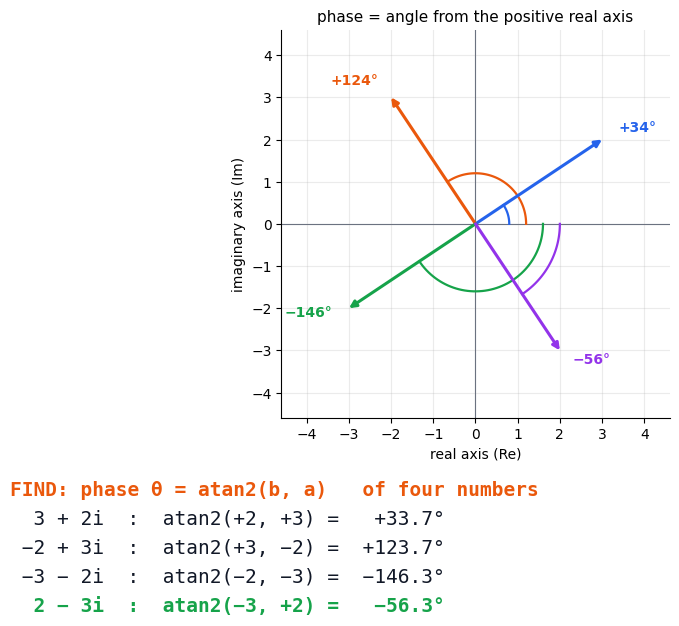

In [11]:
# ---- helper that draws an angle arc (reused below) ----
def draw_arc(ax, radius, start, end, color=GRAY, label=None, label_radius=None):
    """Draw an angle arc around the origin (angles in radians)."""
    a = np.linspace(start, end, 60)
    ax.plot(radius * np.cos(a), radius * np.sin(a), color=color, lw=1.6)
    if label:
        m, r = (start + end) / 2, label_radius or radius * 1.3
        ax.text(r * np.cos(m), r * np.sin(m), label, color=color, ha="center", va="center", fontweight="bold")


for z in (3 + 2j, -2 + 3j, -3 - 2j, 2 - 3j):
    print(f"{z!s:>8}   phase = {np.angle(z):+.3f} rad = {np.degrees(np.angle(z)):+7.1f} deg")

z = -3 + 2j
print("\nz = -3+2j :  np.angle =", round(np.angle(z), 3), "   plain atan(b/a) =", round(math.atan(z.imag / z.real), 3), " <- wrong quadrant")

ax = new_plane(lim=4.6, title="phase = angle from the positive real axis", figsize=(6, 5.8), step=1)
for p, c, r in zip((3 + 2j, -2 + 3j, -3 - 2j, 2 - 3j), (BLUE, ORANGE, GREEN, PURPLE), (0.8, 1.2, 1.6, 2.0)):
    draw_arrow(ax, p, c, lw=2.2)
    th = np.angle(p)
    draw_arc(ax, r, 0, th, color=c)
    ax.text(p.real * 1.1 + (0.1 if p.real > 0 else -0.1), p.imag * 1.1, f"{np.degrees(th):+.0f}°".replace("-", "−"), color=c,
            ha="left" if p.real > 0 else "right", fontweight="bold")
nums = (3 + 2j, -2 + 3j, -3 - 2j, 2 - 3j)
show_steps("FIND: phase θ = atan2(b, a)   of four numbers", [
    f"{cstr(p):>8}  :  atan2({p.imag:+.0f}, {p.real:+.0f}) = {np.degrees(np.angle(p)):+7.1f}°".replace("-", "−") for p in nums])

plt.show()

### 1.8 Complex conjugate

<span style="color:#dc2626">**The idea in one sentence.** Conjugation keeps the real part and flips the sign of the imaginary part. On the plane that is a **mirror image across the real axis**: the point `(a, b)` goes to `(a, −b)`.</span>

$$z^* = a - bi$$

- `z*` — the **complex conjugate** of `z` (mathematicians often write `z̄`). The name comes from Latin *coniugare*, "to yoke together": `z` and `z*` are a matched pair
- `a` — the real part, **unchanged**
- `−b` — the imaginary part, <span style="color:#dc2626">**sign flipped**</span>

In Python: **`z.conjugate()`** or `np.conj(z)` (on a numpy array it flips every element).

What changes and what stays, for `z = 3 + 2i` and its conjugate `z* = 3 − 2i`:

| | `z` | `z*` | |
|---|---|---|---|
| Real part `a` | `3` | `3` | stays the same |
| Imaginary part `b` | `2` | `−2` | **flips sign** |
| Length (magnitude) | `√13 ≈ 3.61` | `√13 ≈ 3.61` | stays the same |
| Phase (angle) | `+33.7°` | `−33.7°` | **flips sign** |
| Position | above the real axis | below the real axis | mirror image |

<span style="color:#dc2626">**Why do we need it?** Multiply a number by its own conjugate and the imaginary parts cancel, leaving **a real number: the squared length**, `z · z* = |z|²`. Plain `z · z` does not do this (for `z = i` it gives `−1`, not a length).</span>

**Where it is needed:**
- **Length and probability:** `|z|² = z · z*` is always real and never negative. A quantum probability is `|α|² = α · α*` (section 1.12).
- **Division:** to compute `1 / z`, multiply top and bottom by `z*`, which makes the bottom real: `1 / (3 + 2i) = (3 − 2i) / 13`.
- **Overlap of two states:** the inner product uses a conjugate, `Σ conj(uᵢ) · vᵢ`; without it a state can get length 0 (section 1.12).
- **Getting the parts back:** `(z + z*) / 2 = a` is the real part and `(z − z*) / (2i) = b` is the imaginary part.

The example below shows the main trick with numbers.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `z = 3 + 2i`, build its conjugate `z*` by hand, then multiply `z` by `z*`. What do we get?

</div>

z        = (3+2j)
conj(z)  = (3-2j)
length   = 3.606     conj length = 3.606   <- same length
phase    = 33.7 deg  conj phase  = -33.7 deg  <- sign flips
z * conj(z) = (13+0j)   <- real, equals |z|^2 = 13.0
z * z       = (5+12j)   <- NOT real; do not confuse with z * conj(z)
i**2 = (-1+0j)   (-i)**2 = (-1+0j)   <- both square to -1
conj(z * w)      = (11+10j)
conj(z)*conj(w)  = (11+10j)   <- identical


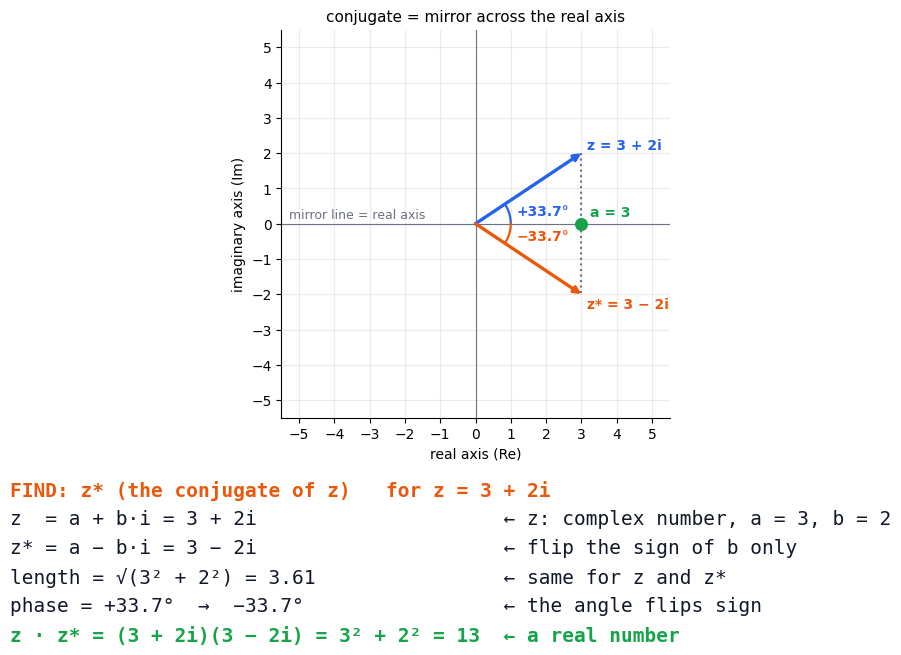

In [12]:
z = 3 + 2j
zc = z.conjugate()
print("z        =", z)
print("conj(z)  =", zc)
print("length   =", round(abs(z), 3), "    conj length =", round(abs(zc), 3), "  <- same length")
print("phase    =", round(np.degrees(np.angle(z)), 1), "deg  conj phase  =", round(np.degrees(np.angle(zc)), 1), "deg  <- sign flips")
print("z * conj(z) =", z * zc, "  <- real, equals |z|^2 =", round(abs(z) ** 2, 6))
print("z * z       =", z * z, "  <- NOT real; do not confuse with z * conj(z)")

# i has a twin, -i. Conjugation swaps them, so sums and products survive the swap.
w = 1 - 4j
print("i**2 =", 1j ** 2, "  (-i)**2 =", (-1j) ** 2, "  <- both square to -1")
print("conj(z * w)      =", (z * w).conjugate())
print("conj(z)*conj(w)  =", zc * w.conjugate(), "  <- identical")

theta = np.angle(z)
deg = np.degrees(theta)
ax = new_plane(lim=5.5, title="conjugate = mirror across the real axis", figsize=(5.8, 5.4), step=1)
draw_arrow(ax, z, BLUE, "z = 3 + 2i", offset=(0.15, 0.1))
draw_arrow(ax, zc, ORANGE, "z* = 3 − 2i", offset=(0.15, -0.4))
ax.plot([z.real, zc.real], [z.imag, zc.imag], ":", color=GRAY)                  # the two tips are mirror images
draw_arc(ax, 1.0, 0, theta, color=BLUE)                                         # angle of z
draw_arc(ax, 1.0, 0, -theta, color=ORANGE)                                      # angle of z*: same size, opposite sign
ax.text(1.15, 0.15, f"{deg:+.1f}°", color=BLUE, fontweight="bold", va="bottom")
ax.text(1.15, -0.15, f"{-deg:+.1f}°".replace("-", "−"), color=ORANGE, fontweight="bold", va="top")
ax.scatter([z.real], [0], color=GREEN, s=70, zorder=4)                          # a: the part that stays
ax.text(z.real + 0.25, 0.2, "a = 3", color=GREEN, fontweight="bold")
ax.text(-5.3, 0.15, "mirror line = real axis", color=GRAY, fontsize=9)

row = lambda left, note: f"{left:<42}← {note}"
show_steps(f"FIND: z* (the conjugate of z)   for z = {cstr(z)}", [
    row(f"z  = a + b·i = {cstr(z)}", f"z: complex number, a = {z.real:g}, b = {z.imag:g}"),
    row(f"z* = a − b·i = {cstr(zc)}", "flip the sign of b only"),
    row(f"length = √({z.real:g}² + {z.imag:g}²) = {abs(z):.2f}", "same for z and z*"),
    row(f"phase = {deg:+.1f}°  →  {-deg:+.1f}°".replace("-", "−"), "the angle flips sign"),
    row(f"z · z* = ({cstr(z)})({cstr(zc)}) = {z.real:g}² + {z.imag:g}² = {abs(z) ** 2:.0f}", "a real number")])

plt.show()

#### What the example shows: conjugation in five steps

Remember the rule:

$$\boxed{(a + bi)^* = a - bi}$$

**The idea behind conjugation.** <span style="color:#dc2626">In general `(a + bi)(a − bi) = a² + b²`: the cross terms always cancel, so `z · z*` is **always a real, non-negative number, the squared length**.</span>

### 1.9 Polar form

You can describe the same point in two ways, just like Cartesian vs. polar coordinates in graphics code:

| Style | You store | Easy operations |
|---|---|---|
| **Rectangular** `(a, b)` | how far right, how far up | addition |
| **Polar** `(r, θ)` | how far away, in which direction | multiplication, rotation |

$$z = r\,(\cos\theta + i\sin\theta)$$

- `r` — the magnitude `|z|` (section 1.6)
- `θ` — the phase (section 1.7)
- `cos θ` — the fraction of the length that points **right**, so `a = r·cos θ`
- `sin θ` — the fraction that points **up**, so `b = r·sin θ`

Python converts both ways: **`cmath.polar(z)`** returns `(r, θ)` and **`cmath.rect(r, θ)`** returns `z`.

rectangular (a, b) = (3.0, 2.0)
polar       (r, θ) = (3.6056, 0.5880 rad = 33.7°)
back again: (3+2j)
check a = r cos θ: 3.0    b = r sin θ: 2.0


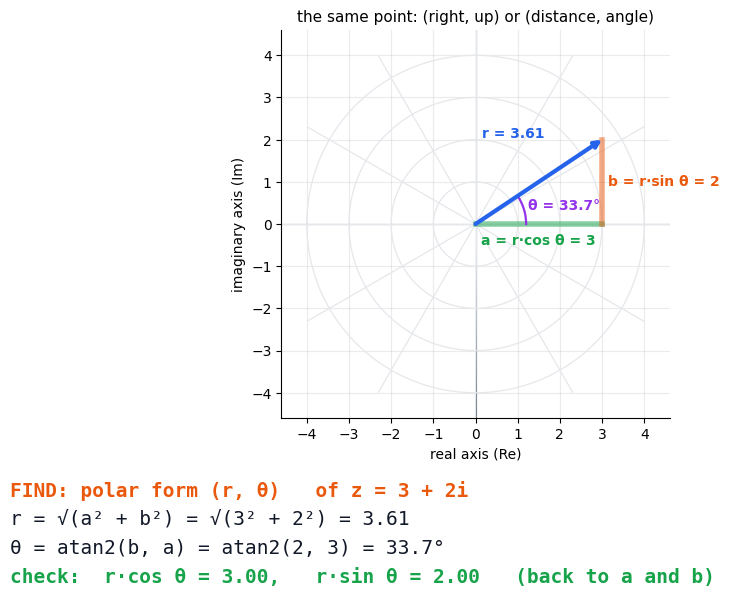

In [13]:
import cmath


z = 3 + 2j
r, theta = cmath.polar(z)
print(f"rectangular (a, b) = ({z.real}, {z.imag})")
print(f"polar       (r, θ) = ({r:.4f}, {theta:.4f} rad = {math.degrees(theta):.1f}°)")
print("back again:", np.round(cmath.rect(r, theta), 6))
print("check a = r cos θ:", round(r * math.cos(theta), 6), "   b = r sin θ:", round(r * math.sin(theta), 6))

ax = new_plane(lim=4.6, title="the same point: (right, up) or (distance, angle)", figsize=(6.2, 5.8), step=1)
for rad in (1, 2, 3, 4):
    t = np.linspace(0, 2 * np.pi, 200)
    ax.plot(rad * np.cos(t), rad * np.sin(t), color="#e5e7eb", lw=0.9)
for ang in range(0, 360, 30):
    ax.plot([0, 4.6 * np.cos(np.radians(ang))], [0, 4.6 * np.sin(np.radians(ang))], color="#e5e7eb", lw=0.9)
draw_arrow(ax, z, BLUE, lw=3)
ax.plot([0, z.real], [0, 0], color=GREEN, lw=4, alpha=0.5)
ax.plot([z.real, z.real], [0, z.imag], color=ORANGE, lw=4, alpha=0.5)
draw_arc(ax, 1.2, 0, theta, color=PURPLE)
ax.text(1.25, 0.35, "θ = 33.7°", color=PURPLE, fontweight="bold")
ax.text(0.15, 2.05, f"r = {r:.2f}", color=BLUE, fontweight="bold")
ax.text(1.5, -0.5, "a = r·cos θ = 3", color=GREEN, ha="center", fontweight="bold")
ax.text(3.15, 1.0, "b = r·sin θ = 2", color=ORANGE, va="center", fontweight="bold")
show_steps(f"FIND: polar form (r, θ)   of z = {cstr(z)}", [
    f"r = √(a² + b²) = √({z.real:g}² + {z.imag:g}²) = {r:.2f}",
    f"θ = atan2(b, a) = atan2({z.imag:g}, {z.real:g}) = {math.degrees(theta):.1f}°",
    f"check:  r·cos θ = {r * math.cos(theta):.2f},   r·sin θ = {r * math.sin(theta):.2f}   (back to a and b)"])

plt.show()

### 1.10 Euler's formula: continuous rotation

**Why calculate a rotation at all?** Anything that repeats is a rotation in disguise: a wheel, a clock hand, a sound wave, the mains power, a qubit's phase. Describing it with sines and cosines gets messy. <span style="color:#dc2626">**One number, `e^{iθ}`, describes the whole turn, and one multiplication turns by `θ`.**</span>

**Famous example: the Fourier transform.** <span style="color:#dc2626">**Every sound, image or radio signal is a sum of arrows spinning at different speeds.**</span> Each arrow is `e^{iωt}` (`ω` = how fast it spins, `t` = time). Add the arrows and you rebuild the signal; the Fourier transform does the reverse and finds which spins are hidden inside. Audio equalizers, Wi-Fi, MRI scanners and image/audio compression are built on it.

$$e^{i\theta} = \cos\theta + i\sin\theta$$

- `e` — Euler's number, 2.718… (`np.e`), the base of the natural exponential
- `i` — the imaginary unit (`1j` in Python)
- `θ` (theta) — an angle in radians
- right-hand side — the point on the **unit circle** (length 1) at angle `θ`: `cos θ` steps right, `sin θ` steps up. It is the polar form from 1.9 with `r = 1`

**What it means.** Multiplying by `i` is a *jump* of exactly 90°. `e^{iθ}` is the **dial**: turn the knob `θ` smoothly from 0 to 2π and the point glides **once around the circle**, passing through every angle on the way. `i` itself is just one setting of the dial: `e^{iπ/2} = i`.

| Dial setting `θ` | Result `e^{iθ}` | Meaning |
|---|---|---|
| 0 | 1 | no turn |
| π/2 | `i` | quarter turn |
| π | −1 | half turn (Euler's identity: `e^{iπ} + 1 = 0`) |
| 3π/2 | −`i` | three-quarter turn |
| 2π | 1 | full circle, back at the start |

**Why this is the right tool for rotation.** Exponents add when you multiply: `e^α · e^β = e^{α+β}`. The same rule works here: `e^{iα} · e^{iβ} = e^{i(α+β)}`, so **angles add**. It replaces the sine/cosine addition formulas you would otherwise have to memorise.

**Compact polar form.** Any complex number can be written `z = r · e^{iθ}`: length `r`, direction `θ`.

**Shadows are waves.** The horizontal shadow of the rotating arrow is `cos θ` and the vertical shadow is `sin θ` (right picture). A rotating arrow *casts waves*, a fact we use in 1.13. (Where the formula comes from: write the series of `e^x`, put `x = iθ`, and the even powers form `cos θ` while the odd powers form `i·sin θ`.)

exp(i θ)    = (0.6967+0.7174j)
cos θ + i sin θ = (0.6967+0.7174j)
|e^{iθ}|    = 1.0   <- always 1: on the unit circle

special settings:
  θ =    0:  e^(iθ) = (1+0j)
  θ =  π/2:  e^(iθ) = 1j
  θ =    π:  e^(iθ) = (-1+0j)
  θ = 3π/2:  e^(iθ) = -1j
  θ =   2π:  e^(iθ) = (1+0j)
Euler's identity e^(iπ) + 1 = 0j  (zero up to rounding)
angles add: (-0.0292+0.999574j) = (-0.0292+0.999574j)


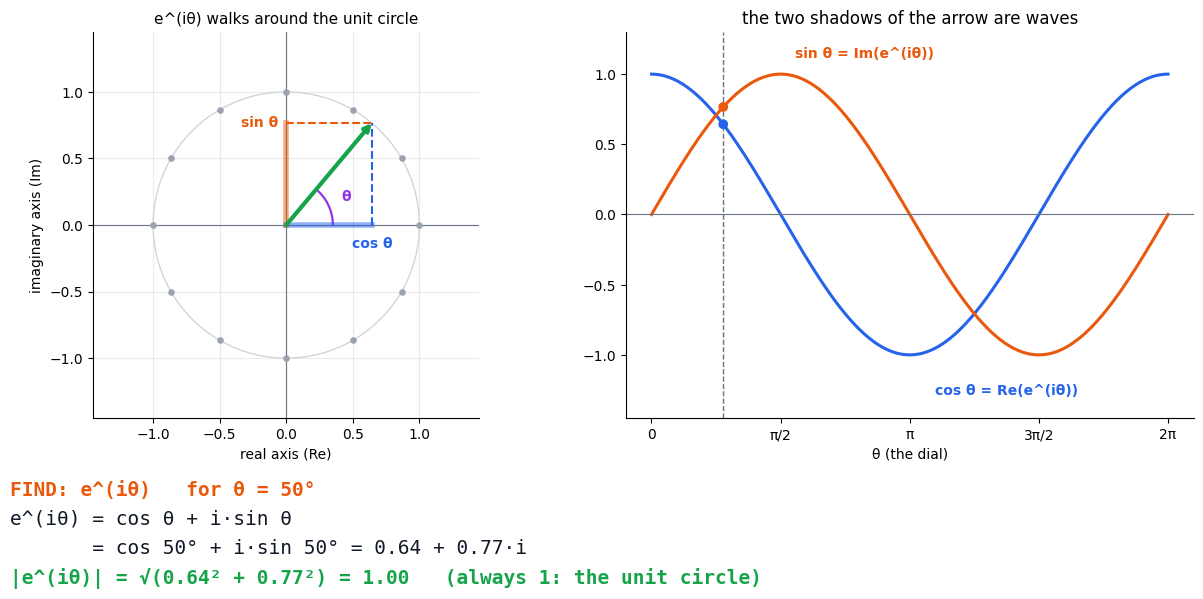

In [14]:
theta = 0.8
print("exp(i θ)    =", np.round(np.exp(1j * theta), 4))
print("cos θ + i sin θ =", np.round(np.cos(theta) + 1j * np.sin(theta), 4))
print("|e^{iθ}|    =", round(abs(np.exp(1j * theta)), 6), "  <- always 1: on the unit circle")
print("\nspecial settings:")
for name, th in [("0", 0), ("π/2", np.pi / 2), ("π", np.pi), ("3π/2", 3 * np.pi / 2), ("2π", 2 * np.pi)]:
    print(f"  θ = {name:>4}:  e^(iθ) = {np.round(np.exp(1j * th), 10) + 0.0}")
print("Euler's identity e^(iπ) + 1 =", np.round(np.exp(1j * np.pi) + 1, 10) + 0.0, " (zero up to rounding)")
a_, b_ = 0.5, 1.1
print("angles add:", np.round(np.exp(1j * a_) * np.exp(1j * b_), 6), "=", np.round(np.exp(1j * (a_ + b_)), 6))

th0 = np.radians(50)
p = np.exp(1j * th0)
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

ax = new_plane(lim=1.45, title="e^(iθ) walks around the unit circle", ax=axs[0], unit_circle=True)
for k in range(12):
    q = np.exp(1j * k * np.pi / 6)
    ax.scatter([q.real], [q.imag], color="#9ca3af", s=14, zorder=2)
draw_arrow(ax, p, GREEN, lw=3)
draw_arc(ax, 0.35, 0, th0, color=PURPLE, label="θ", label_radius=0.5)
ax.plot([p.real, p.real], [0, p.imag], "--", color=BLUE)
ax.plot([0, p.real], [0, 0], color=BLUE, lw=4, alpha=0.5)
ax.plot([0, 0], [0, p.imag], color=ORANGE, lw=4, alpha=0.5)
ax.plot([0, p.real], [p.imag, p.imag], "--", color=ORANGE)
ax.text(p.real, -0.17, "cos θ", color=BLUE, ha="center", fontweight="bold")
ax.text(-0.06, p.imag, "sin θ", color=ORANGE, ha="right", va="center", fontweight="bold")

ax = axs[1]
th = np.linspace(0, 2 * np.pi, 400)
ax.plot(th, np.cos(th), color=BLUE, lw=2.2)
ax.plot(th, np.sin(th), color=ORANGE, lw=2.2)
ax.axvline(th0, color=GRAY, ls="--", lw=1)
ax.scatter([th0, th0], [np.cos(th0), np.sin(th0)], color=[BLUE, ORANGE], zorder=3)
ax.text(3.45, -1.28, "cos θ = Re(e^(iθ))", color=BLUE, fontweight="bold")
ax.text(1.75, 1.12, "sin θ = Im(e^(iθ))", color=ORANGE, fontweight="bold")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
ax.set_xticklabels(["0", "π/2", "π", "3π/2", "2π"])
ax.set_ylim(-1.45, 1.3)
ax.set_xlabel("θ (the dial)")
ax.set_title("the two shadows of the arrow are waves")
show_steps("FIND: e^(iθ)   for θ = 50°", [
    "e^(iθ) = cos θ + i·sin θ",
    f"       = cos 50° + i·sin 50° = {np.cos(th0):.2f} + {np.sin(th0):.2f}·i",
    f"|e^(iθ)| = √({np.cos(th0):.2f}² + {np.sin(th0):.2f}²) = {abs(p):.2f}   (always 1: the unit circle)"])

plt.show()

### 1.11 Complex multiplication: lengths multiply, angles add

$$(r_1 e^{i\theta_1})\cdot(r_2 e^{i\theta_2}) = (r_1 r_2)\; e^{i(\theta_1 + \theta_2)}$$

- `r₁, r₂` — the magnitudes of the two numbers
- `θ₁, θ₂` — their phases
- result — magnitude `r₁·r₂` (**scale**) and phase `θ₁+θ₂` (**rotate**)

So multiplying by `w` means: **turn by the phase of `w`, stretch by the magnitude of `w`.** If `|w| = 1`, the multiplication is a pure rotation, which is exactly the case quantum gates use.

Python: **`z * w`**. The picture shows `z`, `w` and `z·w`: the length of the result is the product of the lengths, and its angle is the sum of the angles.

**Is it just a 2D vector?** As stored data, yes: `3 + 2j` and `[3, 2]` are the same two floats, and they add the same way. The *only* difference is this multiplication. Ordinary 2D vectors have no product that turns and scales and can be undone.

|z| = 2.236   |w| = 1.500   |z*w| = 3.354   |z|*|w| = 3.354
phase z = 26.6°   phase w = 50.0°   phase z*w = 76.6°   (sum = 76.6°)


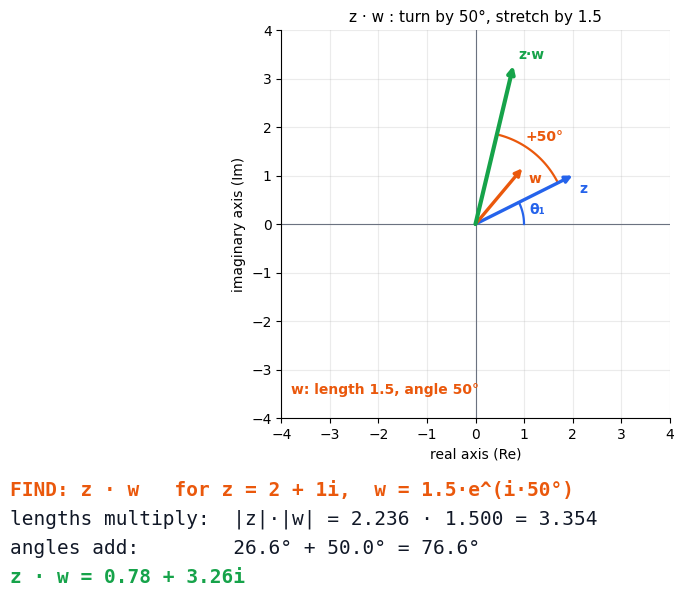

In [15]:
z = 2 + 1j
w = 1.5 * np.exp(1j * np.radians(50))          # length 1.5, angle 50°
zw = z * w

print(f"|z| = {abs(z):.3f}   |w| = {abs(w):.3f}   |z*w| = {abs(zw):.3f}   |z|*|w| = {abs(z) * abs(w):.3f}")
print(f"phase z = {np.degrees(np.angle(z)):.1f}°   phase w = {np.degrees(np.angle(w)):.1f}°   "
      f"phase z*w = {np.degrees(np.angle(zw)):.1f}°   (sum = {np.degrees(np.angle(z) + np.angle(w)):.1f}°)")

ax = new_plane(lim=4, title="z · w : turn by 50°, stretch by 1.5", figsize=(6.2, 5.8))
draw_arrow(ax, z, BLUE, "z", offset=(0.15, -0.35))
draw_arrow(ax, w, ORANGE, "w", offset=(0.12, -0.3))
ax.text(-3.8, -3.5, "w: length 1.5, angle 50°", color=ORANGE, fontweight="bold")
draw_arrow(ax, zw, GREEN, "z·w", lw=3, offset=(0.1, 0.15))
a1, a2 = np.angle(z), np.angle(zw)
draw_arc(ax, 1.0, 0, a1, color=BLUE, label="θ₁", label_radius=1.3)
draw_arc(ax, 1.9, a1, a2, color=ORANGE, label="+50°", label_radius=2.3)
show_steps(f"FIND: z · w   for z = {cstr(z)},  w = 1.5·e^(i·50°)", [
    f"lengths multiply:  |z|·|w| = {abs(z):.3f} · {abs(w):.3f} = {abs(zw):.3f}",
    f"angles add:        {np.degrees(np.angle(z)):.1f}° + {np.degrees(np.angle(w)):.1f}° = {np.degrees(np.angle(zw)):.1f}°",
    f"z · w = {cstr(zw, 2)}"])

plt.show()

#### 1.11a Nothing in the real number system naturally turns

Multiply a **real** number by another real number and the point can only **stretch, shrink, or flip** (multiplying by −1) *along the same line*. Real multiplication has no way to change the direction of something by, say, 30°. Rotation is not available anywhere in the real number system.

Complex numbers add exactly this: a **rotation is just a multiplication**. That is the whole trade: a simple, useful geometric transformation (turn + scale) that now lives inside ordinary algebra, with no special rotation machinery needed.

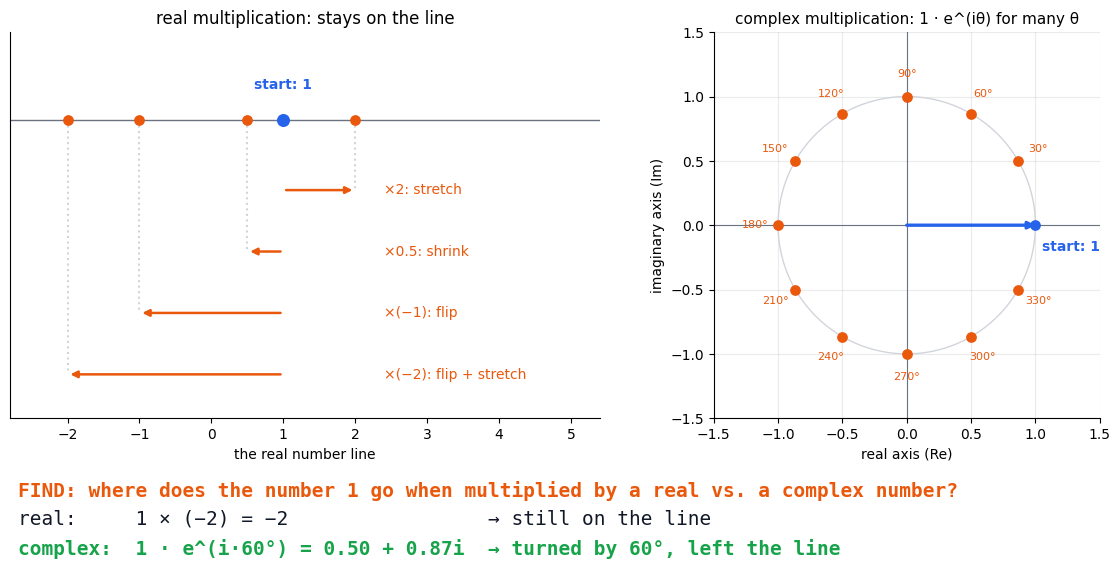

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))

# left: real multiplication stays on the line
ax = axs[0]
ax.axhline(0, color=GRAY, lw=1)
ax.scatter([1], [0], color=BLUE, s=70, zorder=3)
ax.text(1, 0.35, "start: 1", color=BLUE, ha="center", fontweight="bold")
for factor, y, lab in [(2, -0.8, "×2: stretch"), (0.5, -1.5, "×0.5: shrink"), (-1, -2.2, "×(−1): flip"), (-2, -2.9, "×(−2): flip + stretch")]:
    ax.annotate("", xy=(factor, y), xytext=(1, y), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.8))
    ax.scatter([factor], [0], color=ORANGE, s=45, zorder=3)
    ax.plot([factor, factor], [0, y], ":", color="#d1d5db")
    ax.text(2.4, y, lab, va="center", color=ORANGE)
ax.set_xlim(-2.8, 5.4)
ax.set_ylim(-3.4, 1.0)
ax.set_yticks([])
ax.set_xlabel("the real number line")
ax.set_title("real multiplication: stays on the line")

# right: complex multiplication turns
ax = new_plane(lim=1.5, title="complex multiplication: 1 · e^(iθ) for many θ", ax=axs[1], unit_circle=True)
for ang in range(0, 360, 30):
    q = 1 * np.exp(1j * np.radians(ang))
    ax.scatter([q.real], [q.imag], color=ORANGE if ang else BLUE, s=45, zorder=3)
    if ang:
        ax.text(q.real * 1.18, q.imag * 1.18, f"{ang}°", color=ORANGE, ha="center", va="center", fontsize=8)
draw_arrow(ax, 1, BLUE, "start: 1", offset=(0.05, -0.2))
c_ = np.exp(1j * np.radians(60))
left1, left2 = "1 × (−2) = −2", f"1 · e^(i·60°) = {cstr(c_, 2)}"
show_steps("FIND: where does the number 1 go when multiplied by a real vs. a complex number?", [
    f"real:     {left1:<30}→ still on the line",
    f"complex:  {left2:<30}→ turned by 60°, left the line"])

plt.show()

#### 1.11b Rotation matrix vs. complex number: four numbers vs. one

A 2D rotation by angle θ written as a matrix needs **four stored numbers**:

$$R(\theta) = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix}$$

- `cos θ, sin θ` — the two distinct values; each appears twice (with a sign flip on one), so the matrix stores **4 slots** for what is really 1 piece of information.
- Combining two rotations means a **matrix product** (8 multiplications and 4 additions).

As a **complex number** the same rotation is **exactly one number**: `c = cos θ + i sin θ = e^{iθ}`. Combining two rotations is **one complex multiplication** and the angles add automatically.

| | Rotation matrix | Complex number |
|---|---|---|
| Numbers you store | 4 (a 2×2 array) | **1** (one complex number) |
| Apply to a point | matrix × vector | `c * z` |
| Combine two rotations | matrix × matrix | `c1 * c2` (angles add) |
| Undo a rotation | transpose the matrix | conjugate: `c.conjugate()` |
| Order of rotations matters? | matrices in general: yes | rotations in the plane: no (they commute) |

*Honest accounting:* the memory saving is tiny (2 floats vs. 4). The real win is **simplicity**: one symbol, and composing rotations is just multiplication.

In [17]:
def as_matrix(c):
    """The 2x2 matrix that does the same thing as 'multiply by the complex number c'."""
    return np.array([[c.real, -c.imag], [c.imag, c.real]])


def as_vec(z):
    return np.array([z.real, z.imag])


theta = np.radians(30)
c = np.exp(1j * theta)                      # ONE complex number
R = as_matrix(c)                            # FOUR numbers
z = 3 + 2j

print("complex number c      :", np.round(c, 4), "   -> numbers stored:", 1)
print("rotation matrix R     :\n", R, "\n   -> numbers stored:", R.size)
print("\nc * z   =", as_vec(c * z))
print("R @ z   =", R @ as_vec(z), "   <- same result")

c1, c2 = np.exp(1j * np.radians(30)), np.exp(1j * np.radians(45))
print("\ncombine 30° then 45°:")
print("  complex :", np.round(c1 * c2, 4), "  (one multiply)   angle =", round(np.degrees(np.angle(c1 * c2)), 1), "°")
print("  matrix  :\n", as_matrix(c2) @ as_matrix(c1), "\n  (one matrix product)")

A, B = np.random.default_rng(0).normal(size=(2, 2)), np.random.default_rng(1).normal(size=(2, 2))
print("\nrotations commute  :", np.allclose(as_matrix(c1) @ as_matrix(c2), as_matrix(c2) @ as_matrix(c1)))
print("generic 2x2 matrices commute:", np.allclose(A @ B, B @ A))
print("undo = conjugate   :", np.allclose(c * c.conjugate(), 1))

complex number c      : (0.866+0.5j)    -> numbers stored: 1
rotation matrix R     :
 [[ 0.866 -0.5  ]
 [ 0.5    0.866]] 
   -> numbers stored: 4

c * z   = [1.5981 3.2321]
R @ z   = [1.5981 3.2321]    <- same result

combine 30° then 45°:
  complex : (0.2588+0.9659j)   (one multiply)   angle = 75.0 °
  matrix  :
 [[ 0.2588 -0.9659]
 [ 0.9659  0.2588]] 
  (one matrix product)

rotations commute  : True
generic 2x2 matrices commute: False
undo = conjugate   : True


### 1.12 Why magnitude and conjugate matter in quantum computing

Two of the points above do most of the work in quantum computing:

**1. Magnitude squared is a probability.** A qubit state is a pair of complex amplitudes `(α, β)`. The probability of measuring 0 is `|α|²` and of measuring 1 is `|β|²`. These must add up to 1.

**2. The conjugate builds the inner product.** To measure how much two states `u` and `v` overlap you compute `Σ conj(uᵢ) · vᵢ` (`np.vdot(u, v)` in numpy). The conjugate is not decoration: **without it the "length" of a state comes out wrong.** For `u = (1, i)/√2`, the sum `Σ uᵢ·uᵢ` gives `(1 + i²)/2 = 0`, a state of length zero. With the conjugate, `Σ conj(uᵢ)·uᵢ = (1 + 1)/2 = 1`, as it should.

amplitudes: 0.6 0.8j
probabilities |α|², |β|² = [0.36 0.64]   sum = 1.0

without conjugate  u·u        = 0j    <- zero 'length': wrong
with conjugate     np.vdot(u,u) = (1+0j)    <- 1: a valid state


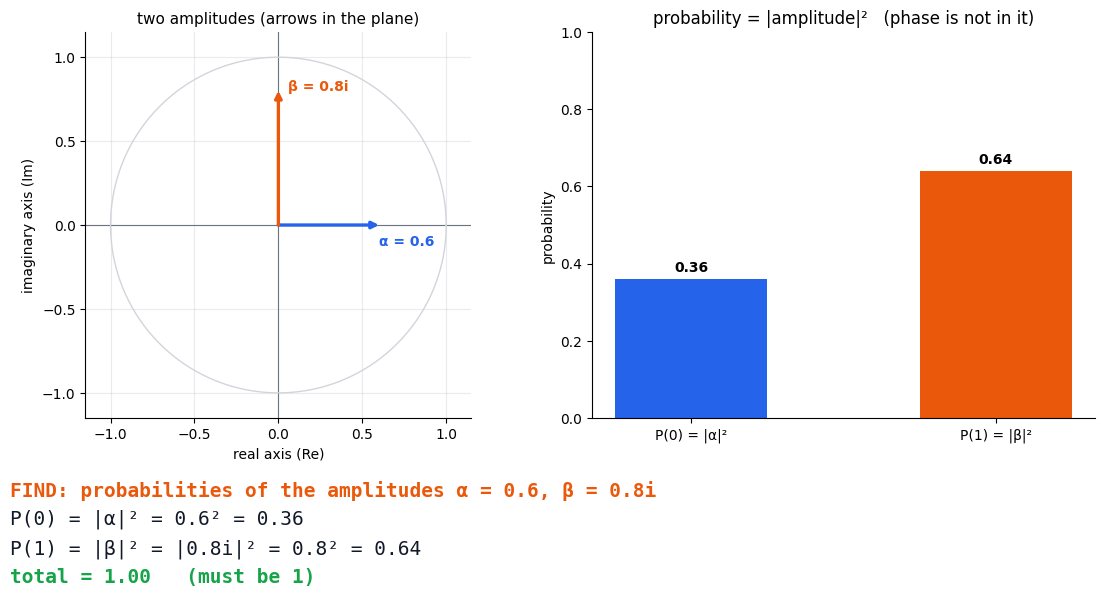

In [18]:
alpha, beta = 0.6, 0.8j                      # amplitudes of one qubit
p = np.array([abs(alpha) ** 2, abs(beta) ** 2])
print("amplitudes:", alpha, beta)
print("probabilities |α|², |β|² =", p, "  sum =", p.sum())

u = np.array([1, 1j]) / np.sqrt(2)
print("\nwithout conjugate  u·u        =", np.round(u @ u, 10) + 0.0, "   <- zero 'length': wrong")
print("with conjugate     np.vdot(u,u) =", np.round(np.vdot(u, u), 10) + 0.0, "   <- 1: a valid state")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
ax = new_plane(lim=1.15, title="two amplitudes (arrows in the plane)", ax=axs[0], unit_circle=True)
draw_arrow(ax, alpha, BLUE, "α = 0.6", offset=(0.0, -0.12))
draw_arrow(ax, beta, ORANGE, "β = 0.8i", offset=(0.06, 0.0))
ax = axs[1]
bars = ax.bar(["P(0) = |α|²", "P(1) = |β|²"], p, color=[BLUE, ORANGE], width=0.5)
for b_, val in zip(bars, p):
    ax.text(b_.get_x() + b_.get_width() / 2, val + 0.02, f"{val:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, 1)
ax.set_ylabel("probability")
ax.set_title("probability = |amplitude|²   (phase is not in it)")
show_steps(f"FIND: probabilities of the amplitudes α = {alpha:g}, β = {beta.imag:g}i", [
    f"P(0) = |α|² = {abs(alpha):g}² = {p[0]:.2f}",
    f"P(1) = |β|² = |{beta.imag:g}i|² = {abs(beta):g}² = {p[1]:.2f}",
    f"total = {p.sum():.2f}   (must be 1)"])

plt.show()

### 1.13 Why does rotation show up in systems that do not visibly rotate?

**Short answer.** Rotation is the mathematical shape of *two things trading places*. Take any system with two linked quantities where one fills up as the other empties and the "total" stays constant:

- a mass on a spring: **position ↔ velocity**
- a radio wave: **electric ↔ magnetic field**
- a quantum state: the **real ↔ imaginary** part of an amplitude

Plot the pair against each other and the state moves around a **circle** in an abstract plane. **Nothing spins in space; the *state* spins in a plane made of the two quantities.** Look at that circle from the side (one quantity over time) and you see a **wave**. A complex number is the natural bookkeeping for such a plane: one number holds both quantities, and "move along the circle" is just `· e^{iθ}`.

| What happens | In complex numbers | Where you see it |
|---|---|---|
| **Multiplication → rotation** | `z · e^{iθ}` turns `z` by θ | phase shifts, delays, quantum gates |
| **Addition → interference** | `z₁ + z₂` can reinforce or cancel | overlapping radio signals, quantum paths |
| **Leaving the real numbers → oscillation** | roots become `±i` instead of failing | springs, circuits, qubit evolution |

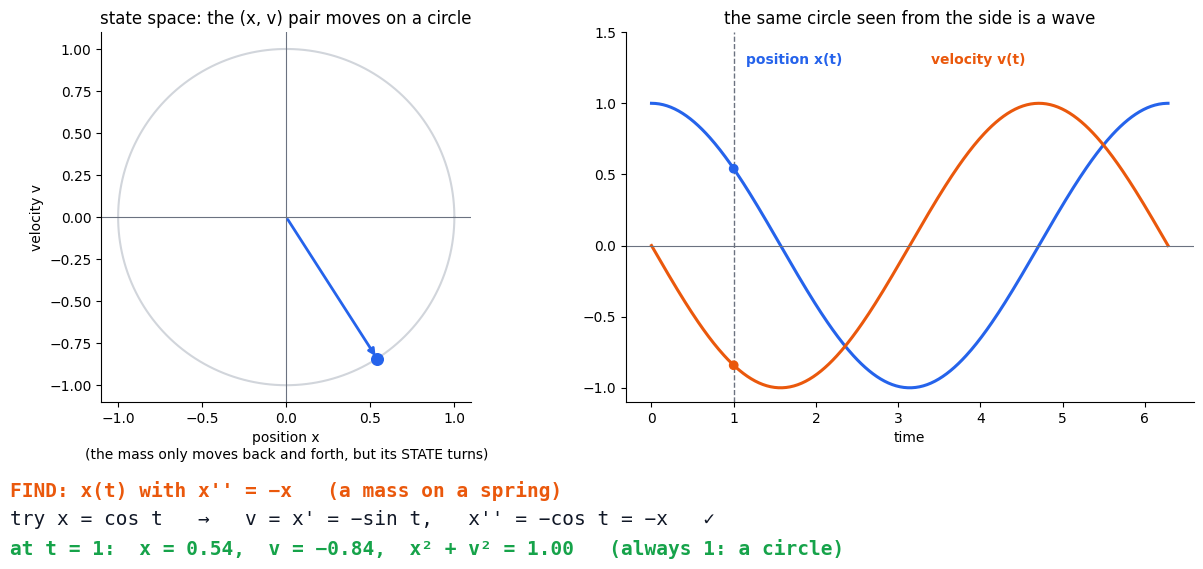

In [19]:
# a mass on a spring: x'' = -x  ->  x(t) = cos t,  v(t) = -sin t.  Nothing rotates in space, yet (x, v) goes around a circle.
t = np.linspace(0, 2 * np.pi, 400)
x, v = np.cos(t), -np.sin(t)
t0 = 1.0

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axs[0]
ax.plot(x, v, color="#d1d5db", lw=1.5)
ax.scatter([np.cos(t0)], [-np.sin(t0)], color=BLUE, s=70, zorder=3)
ax.annotate("", xy=(np.cos(t0), -np.sin(t0)), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2))
ax.axhline(0, color=GRAY, lw=0.8)
ax.axvline(0, color=GRAY, lw=0.8)
ax.set_aspect("equal")
ax.set_xlabel("position x\n(the mass only moves back and forth, but its STATE turns)")
ax.set_ylabel("velocity v")
ax.set_title("state space: the (x, v) pair moves on a circle")

ax = axs[1]
ax.plot(t, x, color=BLUE, lw=2.2)
ax.plot(t, v, color=ORANGE, lw=2.2)
ax.axvline(t0, color=GRAY, ls="--", lw=1)
ax.scatter([t0, t0], [np.cos(t0), -np.sin(t0)], color=[BLUE, ORANGE], zorder=3)
ax.text(1.15, 1.28, "position x(t)", color=BLUE, fontweight="bold")
ax.set_ylim(-1.1, 1.5)
ax.text(3.4, 1.28, "velocity v(t)", color=ORANGE, fontweight="bold")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xlabel("time")
ax.set_title("the same circle seen from the side is a wave")
show_steps("FIND: x(t) with x'' = −x   (a mass on a spring)", [
    "try x = cos t   →   v = x' = −sin t,   x'' = −cos t = −x   ✓",
    f"at t = {t0:g}:  x = {np.cos(t0):.2f},  v = {-np.sin(t0):.2f},  x² + v² = {np.cos(t0) ** 2 + np.sin(t0) ** 2:.2f}   (always 1: a circle)".replace("-", "−")])

plt.show()

#### Example 1: radio waves (signal processing) — classical trigonometry vs. complex numbers

**Setting.** Two paths (or two antennas) deliver the **same-frequency** signal to a receiver, with different strengths `A` and different timing offsets `φ`:

`s₁(t) = A₁ cos(ωt + φ₁)`   and   `s₂(t) = A₂ cos(ωt + φ₂)`

- `A` — amplitude (signal strength), `ω` — angular frequency (same for both), `t` — time, `φ` — phase (timing offset)

**Question:** what does the receiver see, `s₁ + s₂`? It is again a wave of the same frequency, so we want its amplitude and phase.

**Classical trigonometry** — expand each cosine with the angle-addition identity, collect terms, and convert back:
1. `A cos(ωt + φ) = A cos φ · cos ωt − A sin φ · sin ωt`   (identity to remember)
2. add the `cos ωt` coefficients: `C = A₁ cos φ₁ + A₂ cos φ₂`
3. add the `sin ωt` coefficients: `S = A₁ sin φ₁ + A₂ sin φ₂`
4. the sum is `C cos ωt − S sin ωt`; convert back with `A = √(C² + S²)`, `φ = atan2(S, C)`

**Complex numbers** — give each wave one arrow (a **phasor**) `z = A · e^{iφ}` and just **add the arrows**:
1. `z = z₁ + z₂`
2. amplitude = `abs(z)`, phase = `np.angle(z)`

The two routes produce the same numbers (the picture and the code check it). Notice that `C` and `S` from the trigonometry route are simply the **real and imaginary parts** of `z`: complex numbers do the bookkeeping for you.

**Why the complex route wins**
- **Adding waves = adding arrows.** No trig identities to remember or to get wrong.
- **A time delay or phase shift is one multiplication** (`z * np.exp(1j * shift)`); a gain change is another multiplication (`z * 0.5`). Filters and channels are just numbers multiplied onto the phasor.
- **It scales.** 100 antennas are one line: `np.sum(A * np.exp(1j * phi))`. The trig route would expand 100 cosines.
- **Interference becomes visible.** Arrows pointing the same way add up (constructive); opposite arrows cancel (destructive) — right-hand picture.

trigonometry : amplitude = 1.1444, phase = 0.9518
complex      : amplitude = 1.1444, phase = 0.9518
(C, S) = (0.6640, 0.9320)   vs   (Re z, Im z) = (0.6640, 0.9320)   <- the same numbers
max difference from brute-force time-domain sum: 1.7e-15   (rounding noise: the two agree)
100 signals combined: (0.5447-6.6514j)


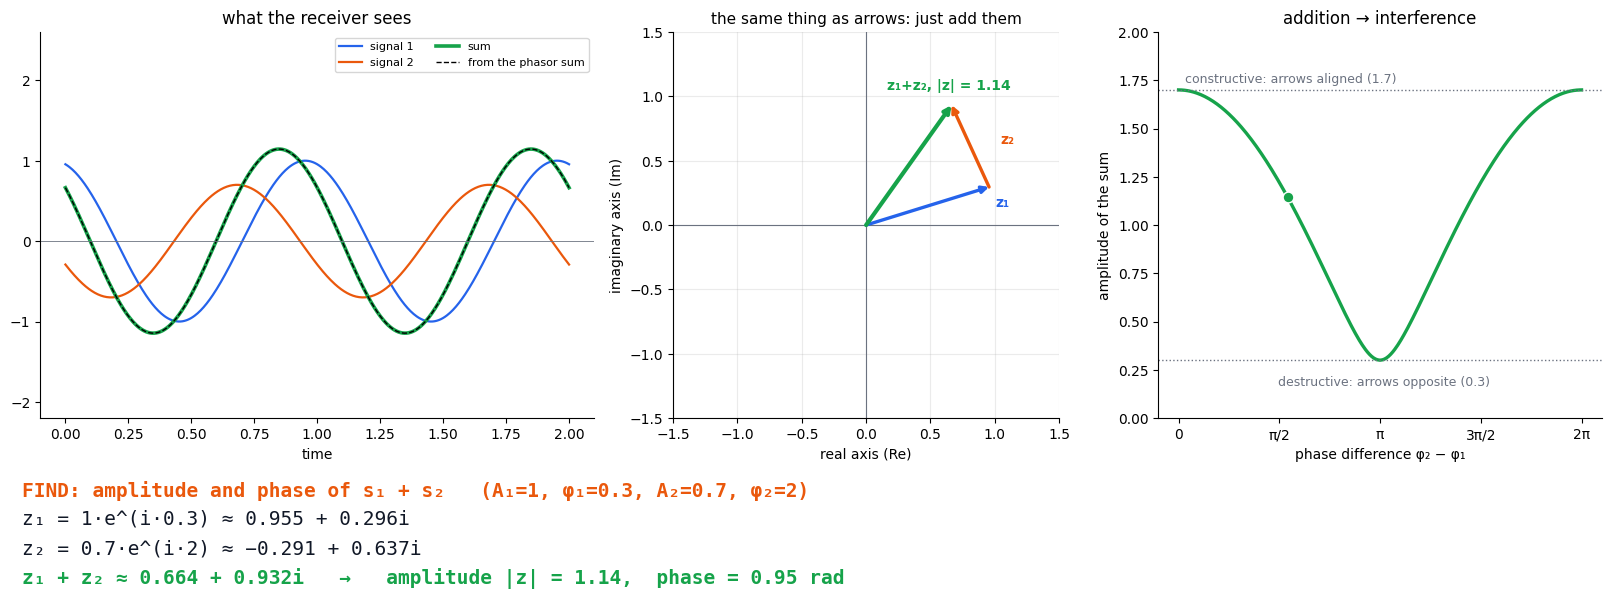

In [20]:
A1, phi1 = 1.0, 0.3
A2, phi2 = 0.7, 2.0
w = 2 * np.pi                                  # one cycle per time unit

# --- route 1: classical trigonometry ---------------------------------------------------------------
C = A1 * np.cos(phi1) + A2 * np.cos(phi2)      # total coefficient of cos(wt)
S = A1 * np.sin(phi1) + A2 * np.sin(phi2)      # total coefficient of sin(wt)
A_trig, phi_trig = np.hypot(C, S), np.arctan2(S, C)

# --- route 2: complex numbers (phasors) -------------------------------------------------------------
z1, z2 = A1 * np.exp(1j * phi1), A2 * np.exp(1j * phi2)
z_sum = z1 + z2
A_cplx, phi_cplx = abs(z_sum), np.angle(z_sum)

print(f"trigonometry : amplitude = {A_trig:.4f}, phase = {phi_trig:.4f}")
print(f"complex      : amplitude = {A_cplx:.4f}, phase = {phi_cplx:.4f}")
print(f"(C, S) = ({C:.4f}, {S:.4f})   vs   (Re z, Im z) = ({z_sum.real:.4f}, {z_sum.imag:.4f})   <- the same numbers")

t = np.linspace(0, 2, 500)
direct = A1 * np.cos(w * t + phi1) + A2 * np.cos(w * t + phi2)           # brute force on the raw waves
print(f"max difference from brute-force time-domain sum: {np.max(np.abs(direct - A_cplx * np.cos(w * t + phi_cplx))):.1e}   (rounding noise: the two agree)")

rng_ant = np.random.default_rng(7)                                       # 100 antennas, one line
amps, phases = rng_ant.uniform(0.5, 1.5, 100), rng_ant.uniform(0, 2 * np.pi, 100)
print("100 signals combined:", np.round(np.sum(amps * np.exp(1j * phases)), 4))

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.25, 1, 1]})

ax = axs[0]
ax.plot(t, A1 * np.cos(w * t + phi1), color=BLUE, lw=1.6, label="signal 1")
ax.plot(t, A2 * np.cos(w * t + phi2), color=ORANGE, lw=1.6, label="signal 2")
ax.plot(t, direct, color=GREEN, lw=2.6, label="sum")
ax.plot(t, A_cplx * np.cos(w * t + phi_cplx), color="black", lw=1, ls="--", label="from the phasor sum")
ax.axhline(0, color=GRAY, lw=0.6)
ax.set_xlabel("time")
ax.set_title("what the receiver sees")
ax.legend(loc="upper right", fontsize=8, ncol=2)
ax.set_ylim(-2.2, 2.6)

ax = new_plane(lim=1.5, title="the same thing as arrows: just add them", ax=axs[1])
draw_arrow(ax, z1, BLUE, "z₁", offset=(0.05, -0.15))
draw_arrow(ax, z1 + z2, ORANGE, "z₂", tail=z1, offset=(0.38, -0.3))
draw_arrow(ax, z_sum, GREEN, f"z₁+z₂, |z| = {A_cplx:.2f}", lw=3, offset=(-0.5, 0.12))

ax = axs[2]
dphi = np.linspace(0, 2 * np.pi, 400)
ax.plot(dphi, np.abs(A1 + A2 * np.exp(1j * dphi)), color=GREEN, lw=2.4)
cur = phi2 - phi1
ax.scatter([cur], [abs(A1 + A2 * np.exp(1j * cur))], color=GREEN, s=60, zorder=3, edgecolor="white")
ax.axhline(A1 + A2, color=GRAY, ls=":", lw=1)
ax.axhline(abs(A1 - A2), color=GRAY, ls=":", lw=1)
ax.text(0.1, A1 + A2 + 0.04, "constructive: arrows aligned (1.7)", color=GRAY, fontsize=9)
ax.text(1.55, abs(A1 - A2) - 0.13, "destructive: arrows opposite (0.3)", color=GRAY, fontsize=9)
ax.set_ylim(0, 2)
ax.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
ax.set_xticklabels(["0", "π/2", "π", "3π/2", "2π"])
ax.set_xlabel("phase difference φ₂ − φ₁")
ax.set_ylabel("amplitude of the sum")
ax.set_title("addition → interference")
show_steps(f"FIND: amplitude and phase of s₁ + s₂   (A₁={A1:g}, φ₁={phi1:g}, A₂={A2:g}, φ₂={phi2:g})", [
    f"z₁ = {A1:g}·e^(i·{phi1:g}) ≈ {cstr(z1, 3)}",
    f"z₂ = {A2:g}·e^(i·{phi2:g}) ≈ {cstr(z2, 3)}",
    f"z₁ + z₂ ≈ {cstr(z_sum, 3)}   →   amplitude |z| = {A_cplx:.2f},  phase = {phi_cplx:.2f} rad"])

plt.show()

#### Example 2: quantum-scale physical systems

A quantum system in a state with definite energy `E` has an amplitude that evolves as

$$\psi(t) = \psi(0)\, e^{-iEt}$$

- `ψ(t)` — the complex amplitude at time `t`
- `E` — the energy of that state (units chosen so that Planck's constant ħ = 1)
- `e^{−iEt}` — a **rotation** by the angle `−E·t`: the higher the energy, the faster the arrow spins

Nothing moves through space; only the **phase** turns. And a single spinning amplitude is *invisible*: its magnitude `|ψ|²` (the probability) never changes. That is why a system in one energy level looks perfectly static.

Now put the system in a **superposition of two energy levels** and add their amplitudes (**addition → interference**):
- each level alone: constant probability, nothing visible happens;
- but the two arrows spin at *different speeds*, so the angle between them grows steadily, and their sum **grows and shrinks**: the probability of finding the system in the "+" combination oscillates like `cos²((E₁ − E₀)t / 2)`.

This is the physics behind qubit oscillations, atomic clocks, and MRI: a **hidden rotation made visible by interference**.

level probabilities stay constant: 0.5 0.5 | 0.5 0.5
P(+) matches cos²((E1-E0)t/2): True


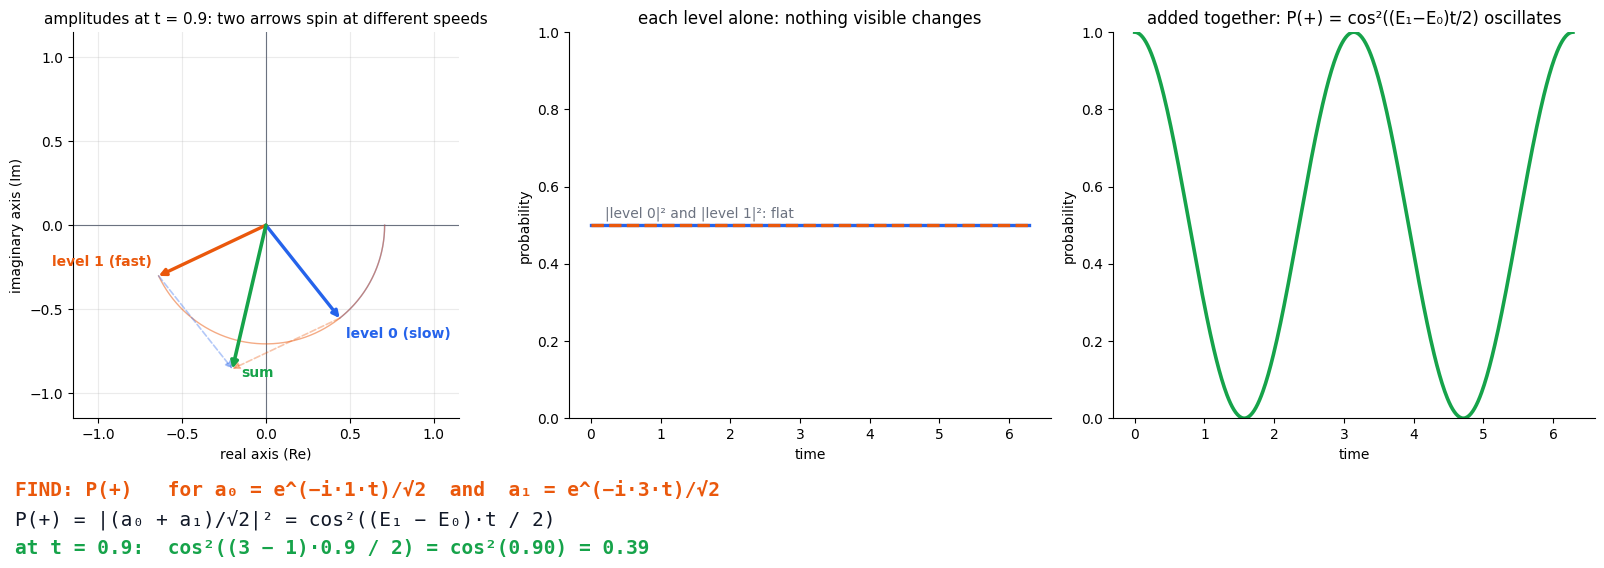

In [21]:
E0, E1 = 1.0, 3.0                                   # two energy levels (ħ = 1)
t = np.linspace(0, 2 * np.pi, 500)
a0 = np.exp(-1j * E0 * t) / np.sqrt(2)              # amplitude of level 0: a spinning arrow
a1 = np.exp(-1j * E1 * t) / np.sqrt(2)              # amplitude of level 1: spins 3x faster

p0, p1 = np.abs(a0) ** 2, np.abs(a1) ** 2           # each level alone: constant 0.5, nothing visible
p_plus = np.abs((a0 + a1) / np.sqrt(2)) ** 2        # probability of the "+" combination: add first, square after

print("level probabilities stay constant:", p0.min().round(3), p0.max().round(3), "|", p1.min().round(3), p1.max().round(3))
print("P(+) matches cos²((E1-E0)t/2):", np.allclose(p_plus, np.cos((E1 - E0) * t / 2) ** 2))

ts = 0.9
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))

ax = new_plane(lim=1.15, title=f"amplitudes at t = {ts}: two arrows spin at different speeds", ax=axs[0])
tt = np.linspace(0, ts, 60)
ax.plot((np.exp(-1j * E0 * tt) / np.sqrt(2)).real, (np.exp(-1j * E0 * tt) / np.sqrt(2)).imag, color=BLUE, lw=1, alpha=0.5)
ax.plot((np.exp(-1j * E1 * tt) / np.sqrt(2)).real, (np.exp(-1j * E1 * tt) / np.sqrt(2)).imag, color=ORANGE, lw=1, alpha=0.5)
A0, A1_ = np.exp(-1j * E0 * ts) / np.sqrt(2), np.exp(-1j * E1 * ts) / np.sqrt(2)
draw_arrow(ax, A0, BLUE, "level 0 (slow)", offset=(0.04, -0.12))
draw_arrow(ax, A1_, ORANGE, "level 1 (fast)", offset=(-0.04, 0.06), ha="right")
draw_arrow(ax, A0 + A1_, GREEN, "sum", lw=2.6, offset=(0.05, -0.05))
draw_arrow(ax, A0 + A1_, BLUE, tail=A1_, linestyle="--", alpha=0.35, lw=1.2)
draw_arrow(ax, A0 + A1_, ORANGE, tail=A0, linestyle="--", alpha=0.35, lw=1.2)

ax = axs[1]
ax.plot(t, p0, color=BLUE, lw=2.4)
ax.plot(t, p1, color=ORANGE, lw=2.4, ls="--")
ax.text(0.2, 0.52, "|level 0|² and |level 1|²: flat", color=GRAY)
ax.set_ylim(0, 1)
ax.set_xlabel("time")
ax.set_ylabel("probability")
ax.set_title("each level alone: nothing visible changes")

ax = axs[2]
ax.plot(t, p_plus, color=GREEN, lw=2.6)
ax.set_ylim(0, 1)
ax.set_xlabel("time")
ax.set_ylabel("probability")
ax.set_title("added together: P(+) = cos²((E₁−E₀)t/2) oscillates")
show_steps(f"FIND: P(+)   for a₀ = e^(−i·{E0:g}·t)/√2  and  a₁ = e^(−i·{E1:g}·t)/√2", [
    "P(+) = |(a₀ + a₁)/√2|² = cos²((E₁ − E₀)·t / 2)",
    f"at t = {ts}:  cos²(({E1:g} − {E0:g})·{ts} / 2) = cos²({(E1 - E0) * ts / 2:.2f}) = {np.cos((E1 - E0) * ts / 2) ** 2:.2f}"])

plt.show()

#### When an equation leaves the real numbers, the system does not break: it oscillates

Take the simplest motion law, "acceleration = −position" (a spring): `x'' = −x`. Look for solutions of the form `x(t) = e^{rt}` (a growth/decay rate `r`). Plug it in and `r² = −1` falls out. **That is exactly the equation from section 1.1.**

If we insisted on real numbers only we would say "no solution, the model is broken". Allow complex `r` and the answer is `r = ±i`, which gives `e^{it} = cos t + i sin t`: a perfectly good **oscillation**.

| Where the roots `r` sit | Behaviour of the system | Example equation |
|---|---|---|
| **real**, e.g. ±1 | growth or decay (it *blows up* or *dies out*) | `x'' = x` |
| **purely imaginary**, ±i | **steady oscillation** | `x'' = −x` |
| **complex**, e.g. −0.2 ± i | oscillation that slowly **fades** (damped) | `x'' + 0.4x' + 1.04x = 0` |

So: *the real part of the root* controls growth or decay, and *the imaginary part* controls oscillation. (This applies to linear systems, the kind that quantum evolution and most signal-processing models belong to.)

x'' =  x  : r² − 1 = 0     -> roots [-1.  1.]
x'' = −x  : r² + 1 = 0     -> roots [0.+1.j 0.-1.j]
damped    : r² + 0.4r + 1.04 = 0 -> roots [-0.2+1.j -0.2-1.j]


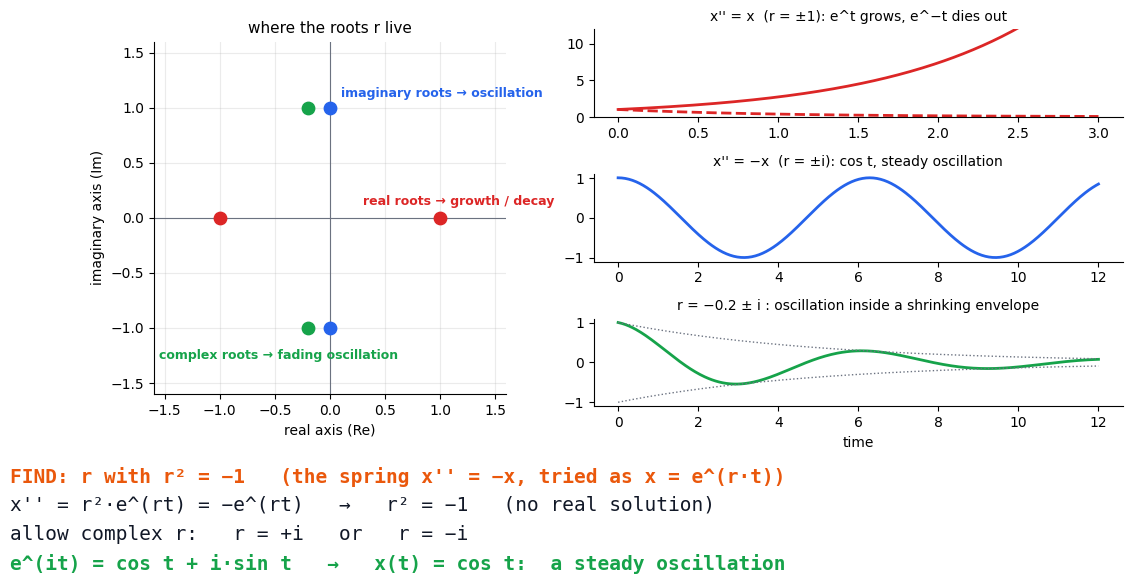

In [22]:
print("x'' =  x  : r² − 1 = 0     -> roots", np.round(np.roots([1, 0, -1]), 4) + 0.0)
print("x'' = −x  : r² + 1 = 0     -> roots", np.round(np.roots([1, 0, 1]), 4) + 0.0)
print("damped    : r² + 0.4r + 1.04 = 0 -> roots", np.round(np.roots([1, 0.4, 1.04]), 4) + 0.0)

fig = plt.figure(figsize=(12.5, 6.6))
gs = fig.add_gridspec(3, 2, width_ratios=[1, 1.5], hspace=0.65)

ax = new_plane(lim=1.6, title="where the roots r live", ax=fig.add_subplot(gs[:, 0]))
for r, c in [((1, 0), RED), ((-1, 0), RED), ((0, 1), BLUE), ((0, -1), BLUE), ((-0.2, 1), GREEN), ((-0.2, -1), GREEN)]:
    ax.scatter([r[0]], [r[1]], color=c, s=80, zorder=3)
ax.text(0.3, 0.12, "real roots → growth / decay", color=RED, fontweight="bold", fontsize=9)
ax.text(0.1, 1.1, "imaginary roots → oscillation", color=BLUE, fontweight="bold", fontsize=9)
ax.text(-1.55, -1.28, "complex roots → fading oscillation", color=GREEN, fontweight="bold", fontsize=9)

ax1 = fig.add_subplot(gs[0, 1])
tt = np.linspace(0, 3, 200)
ax1.plot(tt, np.exp(tt), color=RED, lw=2)
ax1.plot(tt, np.exp(-tt), color=RED, lw=2, ls="--")
ax1.set_ylim(0, 12)
ax1.set_title("x'' = x  (r = ±1): e^t grows, e^−t dies out", fontsize=10)

ax2 = fig.add_subplot(gs[1, 1])
tt = np.linspace(0, 12, 400)
ax2.plot(tt, np.cos(tt), color=BLUE, lw=2)
ax2.set_title("x'' = −x  (r = ±i): cos t, steady oscillation", fontsize=10)

ax3 = fig.add_subplot(gs[2, 1])
ax3.plot(tt, np.exp(-0.2 * tt) * np.cos(tt), color=GREEN, lw=2)
ax3.plot(tt, np.exp(-0.2 * tt), color=GRAY, lw=1, ls=":")
ax3.plot(tt, -np.exp(-0.2 * tt), color=GRAY, lw=1, ls=":")
ax3.set_xlabel("time")
ax3.set_title("r = −0.2 ± i : oscillation inside a shrinking envelope", fontsize=10)
show_steps("FIND: r with r² = −1   (the spring x'' = −x, tried as x = e^(r·t))", [
    "x'' = r²·e^(rt) = −e^(rt)   →   r² = −1   (no real solution)",
    "allow complex r:   r = +i   or   r = −i",
    "e^(it) = cos t + i·sin t   →   x(t) = cos t:  a steady oscillation"], max_h=5.0, tight=False)
plt.show()

### 1.14 Example for an ML engineer — rotary embeddings (RoPE)

If you know **RoPE** from transformers, you already use complex multiplication: pair up two embedding dimensions `(x₁, x₂)`, view them as `z = x₁ + i·x₂`, and rotate by an angle proportional to the token position `m`: `z → z · e^{imθ}`. The attention score `Re(conj(q_m) · k_n)` then depends only on the **relative position** `n − m`, because angles *add* (section 1.11), exactly like phases in quantum amplitudes.

In [23]:
rng = np.random.default_rng(0)
q = rng.normal() + 1j * rng.normal()
k = rng.normal() + 1j * rng.normal()
theta = 0.3


def score(m, n):                                         # <q rotated to position m, k rotated to position n>
    return (np.conj(q * np.exp(1j * m * theta)) * (k * np.exp(1j * n * theta))).real


print("score(2, 5)   =", round(score(2, 5), 4))
print("score(10, 13) =", round(score(10, 13), 4), "  (same offset 3 -> same score)")
print("score(2, 6)   =", round(score(2, 6), 4), "  (different offset)")

# the same rotation written as a real 2x2 matrix acting on (x1, x2)
R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
print("complex mult :", np.round(q * np.exp(1j * theta), 4))
print("real matrix  :", R @ [q.real, q.imag])

score(2, 5)   = -0.0352
score(10, 13) = -0.0352   (same offset 3 -> same score)
score(2, 6)   = -0.067   (different offset)
complex mult : (0.1592-0.089j)
real matrix  : [ 0.1592 -0.089 ]


### 1.15 Summary — complex numbers

**One sentence.** A complex number is a 2D point `z = a + bi` (two floats) with a multiplication that **turns and scales**, which is exactly what a quantum amplitude needs: a size (probability) and a direction (phase).

**Every point on one page**

| Point | What it is | Python | Picture | Why it matters for qubits |
|---|---|---|---|---|
| Real part | `a`: how far right | `z.real` | drop a vertical line | the "0-like" component of an amplitude |
| Imaginary part | `b`: how far up (a real float) | `z.imag` | drop a horizontal line | carries the phase information |
| Addition | add parts separately | `z + w` | tip to tail | amplitudes add → interference |
| Magnitude | length of the arrow | `abs(z)` | distance from origin | `abs(z)**2` = probability |
| Phase | angle from the real axis | `np.angle(z)` | the angle arc | hidden in one measurement, decisive in interference |
| Conjugate | flip the sign of `b` | `z.conjugate()` | mirror image | inner products, `z·z* = abs(z)**2` |
| Polar form | `(r, θ)` instead of `(a, b)` | `cmath.polar(z)` | rings and rays | "how much" and "which direction" separated |
| Euler's formula | `e^{iθ}` = point on the unit circle | `np.exp(1j*θ)` | glide around the circle | a **phase factor** is one setting of the dial |
| Multiplication | lengths multiply, angles add | `z * w` | turn + stretch | a gate multiplies amplitudes by phases |

**Six ideas to remember**
1. **History.** `x² = −1` has no answer on the number line. Instead of giving up, mathematicians added a second dimension; complex numbers began as a calculation trick (Cardano, Bombelli) and got their geometry ~250 years later.
2. **What `i` does.** Multiplying by `i` is a quarter turn (90°). `i² = −1` means two quarter turns make a half turn.
3. **The imaginary axis is geometric.** It is just the perpendicular direction. "Imaginary" is an old insult, not a property.
4. **Rotation as multiplication.** Nothing in the real numbers turns things; complex numbers make rotation an ordinary multiplication.
5. **One number vs. four.** A 2D rotation matrix stores 4 numbers; a rotation as a complex number is exactly one, and combining rotations is one multiplication.
6. **Euler's formula is continuous rotation.** `e^{iθ}` is a dial: turn `θ` smoothly and the point circles; `i` is the setting θ = π/2.

**Three slogans**
- **Multiplication → rotation.**
- **Addition → interference.**
- **Leave the real numbers and the system does not break; it begins to oscillate.**

**Common mistakes**
- Writing `i = √−1` and then manipulating `√` as if it were real: define `i` by `i² = −1` instead.
- Thinking "imaginary" means "unreal": it is a historical insult; `b` is an ordinary real coordinate.
- Squaring a complex number to get a probability: use `|z|² = z·z*`, **not** `z²` (for `z = i`, `z² = −1` but `|z|² = 1`).
- Adding probabilities when you should add amplitudes (or the other way round).
- Typing `i` or `2 j` in Python: it is `1j` and `2j`.

**Worked example — a phase you cannot see, until you interfere.** Take the qubit amplitudes `α = 1/√2` and `β = i/√2` and follow the concepts above:

1. **Magnitude and phase:** `|α| = |β| = 1/√2`, phases `0°` and `90°`. Probabilities: ½, ½.
2. **Mix** the two amplitudes (add and subtract, scaled by `1/√2`; this is what the Hadamard gate does): `(α+β)/√2 = (1+i)/2` and `(α−β)/√2 = (1−i)/2`, each with `|·|² = ½`. The 90° phase is **invisible**: still a 50/50 coin.
3. **Turn** `β` by another 90° (multiply by `e^{iπ/2} = i`): `β → i · i/√2 = −1/√2`. The probabilities are **still** ½, ½ (a rotation preserves magnitude).
4. **Mix again:** `(α+β)/√2 = 0` and `(α−β)/√2 = 1`. The two contributions **cancel** in the first output and **add** in the second: the outcome is now deterministic.

Same magnitudes before and after the turn, completely different result: the information was stored in the phase. A classical probability distribution (½, ½) has no such hidden variable, and quantum algorithms use exactly this resource.

**Video to revisit:** [Complex numbers on YouTube](https://www.youtube.com/watch?v=2i5AqFWc-Qo)

In [24]:
amp = np.array([1, 1j]) / np.sqrt(2)           # amplitudes (alpha, beta) of one qubit

print("1) amplitudes    :", amp)
print("   magnitudes    :", np.abs(amp), "   phases (deg):", np.degrees(np.angle(amp)))
print("   probabilities :", np.abs(amp) ** 2, "  sum =", round(float(np.sum(np.abs(amp) ** 2)), 12))


def mix(a):                                     # add and subtract the two amplitudes (the Hadamard gate)
    return np.array([a[0] + a[1], a[0] - a[1]]) / np.sqrt(2)


print("\n2) mix directly        -> probabilities", np.abs(mix(amp)) ** 2, "  (phase invisible)")

turned = amp * np.array([1, np.exp(1j * np.pi / 2)])     # multiply beta by e^{i pi/2} = i : a 90-degree turn
print("\n3) after the turn      :", turned)
print("   probabilities       :", np.abs(turned) ** 2, "  (turn kept the magnitudes)")
print("   mix after the turn  -> probabilities", np.abs(mix(turned)) ** 2, "  (cancel / add: deterministic)")

# the common mistake: z^2 is not a probability, |z|^2 is
print("\nmistake check: i**2 =", 1j ** 2, "  but |i|^2 =", abs(1j) ** 2)

1) amplitudes    : [0.7071+0.j     0.    +0.7071j]
   magnitudes    : [0.7071 0.7071]    phases (deg): [ 0. 90.]
   probabilities : [0.5 0.5]   sum = 1.0

2) mix directly        -> probabilities [0.5 0.5]   (phase invisible)

3) after the turn      : [ 0.7071+0.j -0.7071+0.j]
   probabilities       : [0.5 0.5]   (turn kept the magnitudes)
   mix after the turn  -> probabilities [0. 1.]   (cancel / add: deterministic)

mistake check: i**2 = (-1+0j)   but |i|^2 = 1.0


### 1.16 The big picture: four takeaways

**One line for programmers:** a complex number is a numeric type that **already knows how to rotate**.

**1. Real numbers carry magnitude; complex numbers carry magnitude *and* rotation, together.**
A real number answers "how much?" (`3`, `−2`, `0.5`): a size and, at most, a sign (a flip). A complex number answers "how much **and** which way?" in a single object: `z = r · e^{iθ}`, where `r` is the magnitude and `θ` is the rotation.
*Benefit:* one value holds size and orientation, so you never keep a separate `(length, angle)` pair in sync, and one multiplication scales and rotates at the same time.

**2. The imaginary unit extends numbers from *measuring* to *describing rotations*.**
Real numbers are rulers: they measure distance along one line. Adding `i` gives numbers a second direction, and `× i` means "turn a quarter". Numbers become rulers **plus dials**.
*Benefit:* a rotation is now just a value you can store, multiply, combine and undo (with the conjugate), instead of a procedure.

**3. Equations that looked unsolvable become solvable, and their solutions are rotations.**
`x² = −1` has no real answer, but it has two complex ones: a quarter turn and a three-quarter turn. More generally `xⁿ = 1` has **n** solutions spaced evenly around the unit circle (`x³ = 1` has one real root and two more at ±120°). The same idea reaches far beyond algebra:
- **Algebra:** every polynomial of degree n has exactly n roots once complex numbers are allowed.
- **Waves:** `x'' = −x` has no real exponential solution, but `e^{±it}` gives the oscillation.
- **Quantum physics:** a state with energy `E` evolves by the rotation `e^{−iEt}`.

*Benefit:* "no solution" dead ends disappear, and the full set of answers has a geometric pattern you can see.

**4. Complex numbers are a mathematical language in which rotational structure becomes explicit.**
Without them, rotation hides inside trigonometric identities and 2×2 matrices. With them, "angles add when you combine rotations" is simply `e^{iα} · e^{iβ} = e^{i(α+β)}`.
*Benefit:* shorter formulas, fewer sign errors, and patterns such as phase, interference and oscillation become visible instead of buried.

| Takeaway | Without complex numbers | With complex numbers | Where you meet it |
|---|---|---|---|
| 1. magnitude + rotation | length and angle stored separately | one number `r·e^{iθ}` | phasors, amplitudes |
| 2. `i` adds turning | rotation = a 2×2 matrix (4 numbers) | rotation = one multiplication | gates, phase shifts |
| 3. more equations solvable | "no real solution" | all roots exist, evenly spaced | polynomials, oscillators, quantum evolution |
| 4. explicit rotation | trig identities to memorise | `e^{iα}·e^{iβ} = e^{i(α+β)}` | signal processing, quantum circuits |

roots of x**3 = 1: [-0.5+0.866j -0.5-0.866j  1. +0.j   ]   angles (deg): [ 120. -120.    0.]
roots of x**2 = -1: [0.+1.j 0.-1.j]
check angles add: True


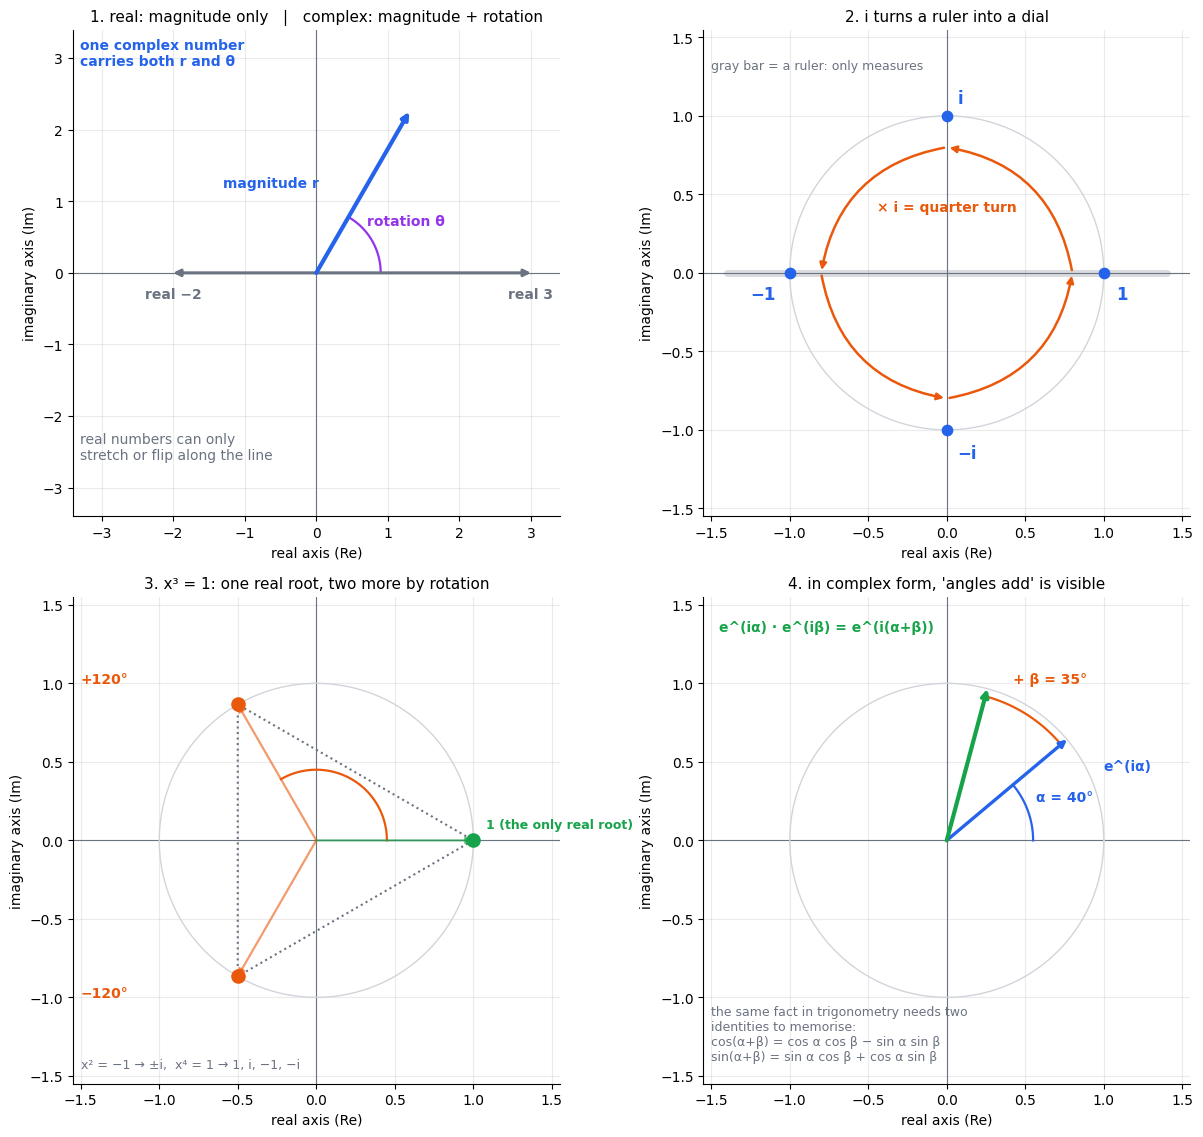

In [25]:
fig, axs = plt.subplots(2, 2, figsize=(12, 11.5))

# ---- 1. real numbers: magnitude only | complex numbers: magnitude + rotation ----------------------
ax = new_plane(lim=3.4, title="1. real: magnitude only   |   complex: magnitude + rotation", ax=axs[0, 0], unit_circle=False)
for val, lab in [(3, "real 3"), (-2, "real −2")]:
    draw_arrow(ax, val, GRAY, lw=2.2)
    ax.text(val, -0.35, lab, color=GRAY, ha="center", fontweight="bold")
z1 = 2.6 * np.exp(1j * np.radians(60))
draw_arrow(ax, z1, BLUE, lw=3)
draw_arc(ax, 0.9, 0, np.radians(60), color=PURPLE, label="rotation θ", label_radius=1.45)
ax.text(-1.3, 1.2, "magnitude r", color=BLUE, fontweight="bold")
ax.text(-3.3, 2.9, "one complex number\ncarries both r and θ", color=BLUE, fontweight="bold")
ax.text(-3.3, -2.6, "real numbers can only\nstretch or flip along the line", color=GRAY)

# ---- 2. the imaginary unit: from ruler to dial ----------------------------------------------------
ax = new_plane(lim=1.55, title="2. i turns a ruler into a dial", ax=axs[0, 1], unit_circle=True)
ax.plot([-1.4, 1.4], [0, 0], color=GRAY, lw=5, alpha=0.25, solid_capstyle="round")
ax.text(-1.5, 1.3, "gray bar = a ruler: only measures", color=GRAY, fontsize=9)
for k, lab in enumerate(["1", "i", "−1", "−i"]):
    p = (1j) ** k
    ax.scatter([p.real], [p.imag], color=BLUE, s=55, zorder=3)
    off = {0: (0.08, -0.17), 1: (0.07, 0.08), 2: (-0.25, -0.17), 3: (0.07, -0.18)}[k]
    ax.text(p.real + off[0], p.imag + off[1], lab, color=BLUE, fontweight="bold", fontsize=12)
for k in range(4):
    a_, b_ = (1j) ** k, (1j) ** (k + 1)
    ax.annotate("", xy=(b_.real * 0.8, b_.imag * 0.8), xytext=(a_.real * 0.8, a_.imag * 0.8),
                arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.8, connectionstyle="arc3,rad=0.35"))
ax.text(0, 0.42, "× i = quarter turn", color=ORANGE, ha="center", va="center", fontweight="bold")

# ---- 3. unsolvable equations: solutions are rotations -----------------------------------------------
roots = np.roots([1, 0, 0, -1])                       # x^3 = 1
print("roots of x**3 = 1:", np.round(roots, 4), "  angles (deg):", np.round(np.degrees(np.angle(roots)), 1))
print("roots of x**2 = -1:", np.round(np.roots([1, 0, 1]), 4) + 0.0)
ax = new_plane(lim=1.55, title="3. x³ = 1: one real root, two more by rotation", ax=axs[1, 0], unit_circle=True)
for r_ in roots:
    isreal = abs(r_.imag) < 1e-9
    ax.scatter([r_.real], [r_.imag], color=GREEN if isreal else ORANGE, s=90, zorder=3)
    draw_arrow(ax, r_, GREEN if isreal else ORANGE, lw=1.6, alpha=0.6)
tri = list(roots) + [roots[0]]
ax.plot([p.real for p in tri], [p.imag for p in tri], ":", color=GRAY)
ax.text(1.08, 0.08, "1 (the only real root)", color=GREEN, fontweight="bold", fontsize=9)
ax.text(-1.5, 1.0, "+120°", color=ORANGE, fontweight="bold")
ax.text(-1.5, -1.0, "−120°", color=ORANGE, fontweight="bold")
ax.text(-1.5, -1.45, "x² = −1 → ±i,  x⁴ = 1 → 1, i, −1, −i", color=GRAY, fontsize=9)
draw_arc(ax, 0.45, 0, np.radians(120), color=ORANGE)

# ---- 4. explicit rotational structure ---------------------------------------------------------------
ax = new_plane(lim=1.55, title="4. in complex form, 'angles add' is visible", ax=axs[1, 1], unit_circle=True)
a_deg, b_deg = 40, 35
ea, eb = np.exp(1j * np.radians(a_deg)), np.exp(1j * np.radians(b_deg))
draw_arrow(ax, ea, BLUE, lw=2.4)
draw_arrow(ax, eb * ea, GREEN, lw=3)
draw_arc(ax, 0.55, 0, np.radians(a_deg), color=BLUE, label=f"α = {a_deg}°", label_radius=0.8)
draw_arc(ax, 0.95, np.radians(a_deg), np.radians(a_deg + b_deg), color=ORANGE, label=f"+ β = {b_deg}°", label_radius=1.22)
ax.text(1.0, 0.45, "e^(iα)", color=BLUE, fontweight="bold")
ax.text(-1.45, 1.33, "e^(iα) · e^(iβ) = e^(i(α+β))", color=GREEN, fontweight="bold")
ax.text(-1.5, -1.05, "the same fact in trigonometry needs two\nidentities to memorise:\ncos(α+β) = cos α cos β − sin α sin β\nsin(α+β) = sin α cos β + cos α sin β", color=GRAY, fontsize=9, va="top")
print("check angles add:", np.allclose(ea * eb, np.exp(1j * np.radians(a_deg + b_deg))))
plt.tight_layout()
plt.show()

---
## 2. Complex vectors

### 2.1 Definition

A <span style="color:red">**complex vector** is an ordered list of $n$ complex numbers</span> :

$$v = \begin{pmatrix} v_1 \\ \vdots \\ v_n \end{pmatrix}\in\mathbb{C}^n, \qquad v_i = r_i e^{i\theta_i}$$

- Add component-wise; scale by a **complex** scalar $c$: $cv=(cv_1,\dots,cv_n)$.
- The components $v_i$ are called **amplitudes**: $\lvert v_i\rvert$ is the "how much" (its square will be a probability) and $\arg v_i$ is the phase.
- It carries $2n$ real numbers: $n$ lengths and $n$ angles.
- <span style="color:red">**A qubit is a complex vector**</span> in $\mathbb{C}^2$ with $\lvert v_1\rvert^2+\lvert v_2\rvert^2=1$; $n$ qubits give $\mathbb{C}^{2^n}$.

### 2.2 Global phase vs. relative phase

Multiply the whole vector by $e^{i\gamma}$ and **every** component rotates by the same angle — a **global phase**. The vector looks different but all lengths (hence all probabilities) are identical; it is physically unobservable.

Change the angle of **one** component only and you get a **relative phase** — a genuinely different state that interferes differently with others.

### 2.3 Visualization

A vector in $\mathbb{C}^2$ has 4 real dimensions, so draw **one arrow per component**, each in its own complex plane.

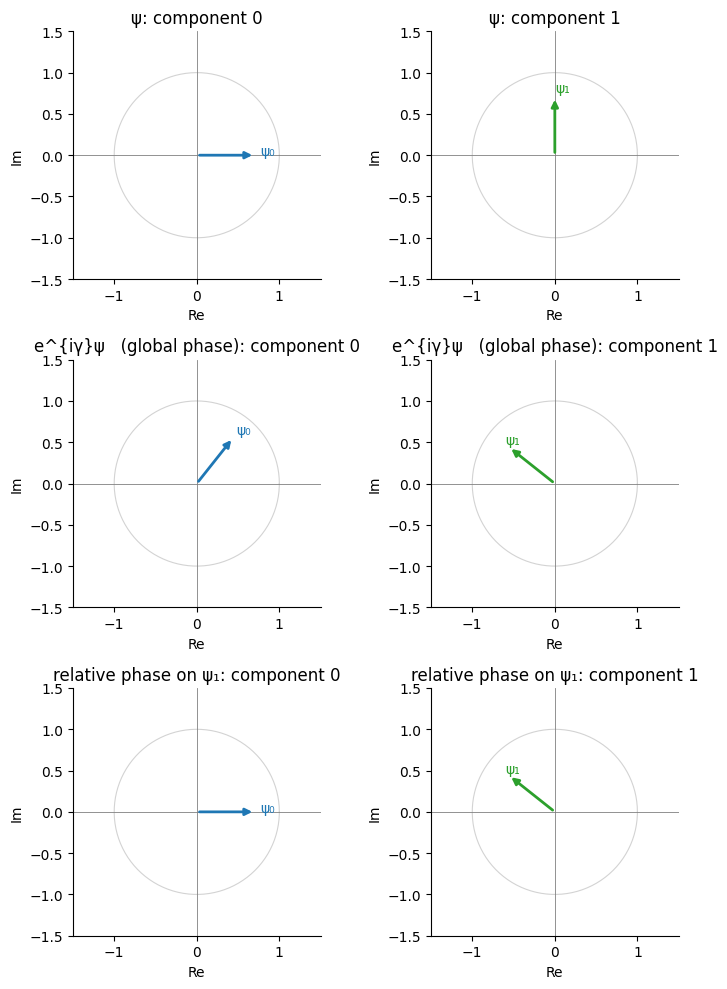

ψ                            probabilities = [0.5 0.5]   sum = 1.000
e^{iγ}ψ   (global phase)     probabilities = [0.5 0.5]   sum = 1.000
relative phase on ψ₁         probabilities = [0.5 0.5]   sum = 1.000


In [95]:
# ---- helper: unit circle + labelled arrows from the origin ----
def complex_plane(ax, arrows, title="", lim=1.5):
    """Helper reused by later sections: unit circle + labelled arrows from the origin."""
    t = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(t), np.sin(t), color="lightgray", lw=0.8)
    ax.axhline(0, color="gray", lw=0.6)
    ax.axvline(0, color="gray", lw=0.6)
    for (label, z, color) in arrows:
        ax.annotate("", xy=(z.real, z.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2))
        ax.text(z.real * 1.08, z.imag * 1.08, label, color=color)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.set_title(title)


psi = np.array([1 / np.sqrt(2), 1j / np.sqrt(2)])                       # a vector in C^2
glob = np.exp(1j * 0.9) * psi                                           # global phase: both arrows rotate together
rel  = np.array([psi[0], psi[1] * np.exp(1j * 0.9)])                    # relative phase: only component 1 rotates

fig, axs = plt.subplots(3, 2, figsize=(7.5, 10))
rows = [("ψ", psi), ("e^{iγ}ψ   (global phase)", glob), ("relative phase on ψ₁", rel)]
for r, (name, v) in enumerate(rows):
    complex_plane(axs[r, 0], [("ψ₀", v[0], "tab:blue")], f"{name}: component 0")
    complex_plane(axs[r, 1], [("ψ₁", v[1], "tab:green")], f"{name}: component 1")
plt.tight_layout(); plt.show()

for name, v in rows:
    print(f"{name:28s} probabilities = {np.abs(v) ** 2}   sum = {np.sum(np.abs(v) ** 2):.3f}")

### 2.4 Example for an ML engineer — the Fourier transform is a complex vector

`np.fft.fft(signal)` returns a **complex vector**: the magnitudes are the "how much" of each frequency, the phases are the "where it sits in time". Shifting a signal in time changes **only the phases** — the magnitude spectrum (what a power-spectrum feature sees) is unchanged. That is the same split as in a qubit: magnitudes are observable, phases are hidden until things interfere.

magnitudes equal : True
phases equal     : False


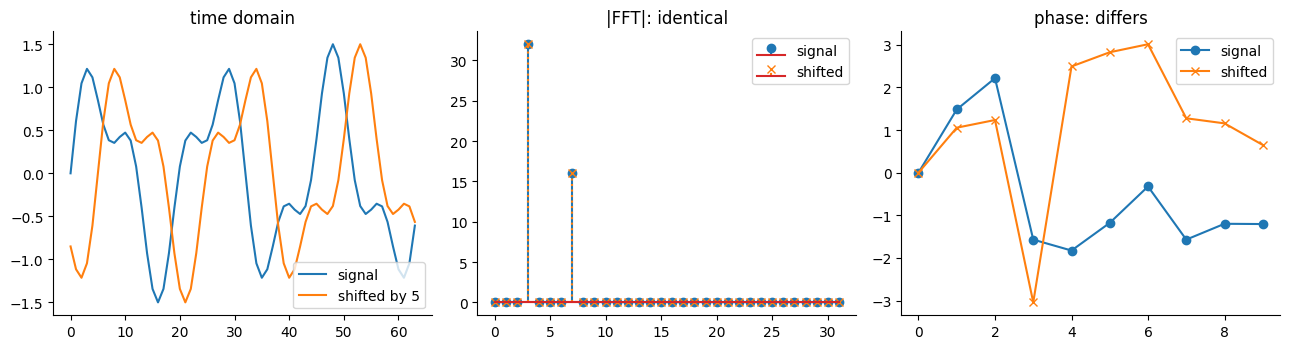

In [96]:
n = 64
tt = np.arange(n)
signal = np.sin(2 * np.pi * 3 * tt / n) + 0.5 * np.sin(2 * np.pi * 7 * tt / n)
shifted = np.roll(signal, 5)

F, Fs = np.fft.fft(signal)[:n // 2], np.fft.fft(shifted)[:n // 2]
print("magnitudes equal :", np.allclose(np.abs(F), np.abs(Fs)))
print("phases equal     :", np.allclose(np.angle(F[3]), np.angle(Fs[3])))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].plot(signal, label="signal"); axs[0].plot(shifted, label="shifted by 5"); axs[0].legend(); axs[0].set_title("time domain")
axs[1].stem(np.abs(F), markerfmt="C0o", label="signal"); axs[1].stem(np.abs(Fs), markerfmt="C1x", linefmt="C1:", label="shifted")
axs[1].set_title("|FFT|: identical"); axs[1].legend()
axs[2].plot(np.angle(F[:10]), "o-", label="signal"); axs[2].plot(np.angle(Fs[:10]), "x-", label="shifted")
axs[2].set_title("phase: differs"); axs[2].legend()
plt.tight_layout(); plt.show()

---
## 3. Vector spaces and Hilbert spaces

### 3.1 From a vector to a space

A **complex vector space** is the *collection* of all complex vectors of a given size, closed under the two operations:

- **add** any two vectors → still in the space;
- **scale** by any complex number → still in the space.

Adding two states with complex weights is a **superposition**: $\alpha|0\rangle+\beta|1\rangle$. "Superposition" is nothing more than "linear combination in a complex vector space".

A **Hilbert space** $\mathcal{H}$ is a complex vector space that also has

1. an **inner product** $\langle u, v\rangle=\sum_i\overline{u_i}\,v_i$ — lets you measure lengths, angles and overlaps (details in section 4), and
2. **completeness** — no "holes" (limits of sequences stay inside). In finite dimensions this is automatic.

So for qubits: **Hilbert space = $\mathbb{C}^n$ with the inner product above.**

| System | Hilbert space | Dimension |
|---|---|---|
| 1 qubit | $\mathbb{C}^2$ | 2 |
| 2 qubits | $\mathbb{C}^4$ | 4 |
| $n$ qubits | $\mathbb{C}^{2^n}$ | $2^n$ |

> **Why this matters.** The state of a quantum system *is* a unit vector in a Hilbert space. Everything else — gates, measurement, entanglement — is a statement about this space.


### 3.2 Properties and dimensionality

**Vector-space properties.** Complex vectors obey the same rules as real ones, with scalars taken from $\mathbb{C}$:

| Property | Statement |
|---|---|
| Closure | $u+v\in\mathcal{H}$ and $c\,v\in\mathcal{H}$ for every complex $c$ |
| Zero and inverses | $0\in\mathcal{H}$; every $v$ has $-v$ |
| Linearity | $c(u+v)=cu+cv$, $(c+d)v=cv+dv$, $c(dv)=(cd)v$ |
| Linear combination (superposition) | $\alpha u+\beta v$ with complex weights |
| Linear independence | no vector is a combination of the others |
| Subspace | a subset closed under the two operations, e.g. $\mathrm{span}\{\lvert00\rangle,\lvert11\rangle\}$ |

**Dimension** is the number of vectors in any basis. $\mathbb{C}^n$ has **complex dimension $n$** (equivalently $2n$ real dimensions). So $n$ qubits need $\mathbb{C}^{2^n}$.

**Counting real degrees of freedom of a state.** An $n$-dimensional complex vector has $2n$ real numbers. A *physical state* is a unit vector (**−1** for normalization) defined up to a global phase (**−1**). That leaves $2n-2$ real parameters:

| System | Complex dim $n$ | Real parameters of a state |
|---|---|---|
| 1 qubit | 2 | $2\cdot2-2=2$  → the two angles of the **Bloch sphere** |
| 2 qubits | 4 | $2\cdot4-2=6$ |
| $k$ qubits | $2^k$ | $2^{k+1}-2$ |

**Hilbert-space extras.** A Hilbert space also carries an inner product (next section) with $\langle u|v\rangle=\overline{\langle v|u\rangle}$, linear in the second slot, and $\langle v|v\rangle>0$ for $v\ne0$; and it is **complete**, which is automatic in finite dimensions.

In [97]:
rng_ = np.random.default_rng(3)
u = rng_.normal(size=4) + 1j * rng_.normal(size=4)
v = rng_.normal(size=4) + 1j * rng_.normal(size=4)
a, b = 0.3 + 0.4j, -0.2 + 0.9j

w = a * u + b * v                                   # closure: a superposition is still a vector in C^4
print("closure OK, w =", w)

# dimension = number of linearly independent vectors = matrix rank
basis4 = np.eye(4, dtype=complex)
print("rank of 4 random vectors in C^4 :", np.linalg.matrix_rank(np.column_stack([u, v, rng_.normal(size=4) + 0j, rng_.normal(size=4) * 1j])))
print("rank of {u, v, 2u+3v}            :", np.linalg.matrix_rank(np.column_stack([u, v, 2 * u + 3 * v])), " (third vector is dependent -> dimension of span = 2)")

# real parameters of a quantum state of dimension n
for k in (1, 2, 3):
    n_ = 2 ** k
    print(f"{k} qubit(s): C^{n_} -> {2 * n_} real numbers - 1 (norm) - 1 (global phase) = {2 * n_ - 2}")

closure OK, w = [ 1.2195-0.0419j -0.7438+2.0374j  1.8379-0.0245j  0.3447-0.5359j]
rank of 4 random vectors in C^4 : 4
rank of {u, v, 2u+3v}            : 2  (third vector is dependent -> dimension of span = 2)
1 qubit(s): C^2 -> 4 real numbers - 1 (norm) - 1 (global phase) = 2
2 qubit(s): C^4 -> 8 real numbers - 1 (norm) - 1 (global phase) = 6
3 qubit(s): C^8 -> 16 real numbers - 1 (norm) - 1 (global phase) = 14


### 3.3 Visualization

Normalized states of one qubit, ignoring the unobservable global phase, form a **sphere** (the Bloch sphere). With real amplitudes only you get just a **circle** (the equator-to-pole slice); complex amplitudes add the phase direction and fill out the sphere. Points are coloured by relative phase.

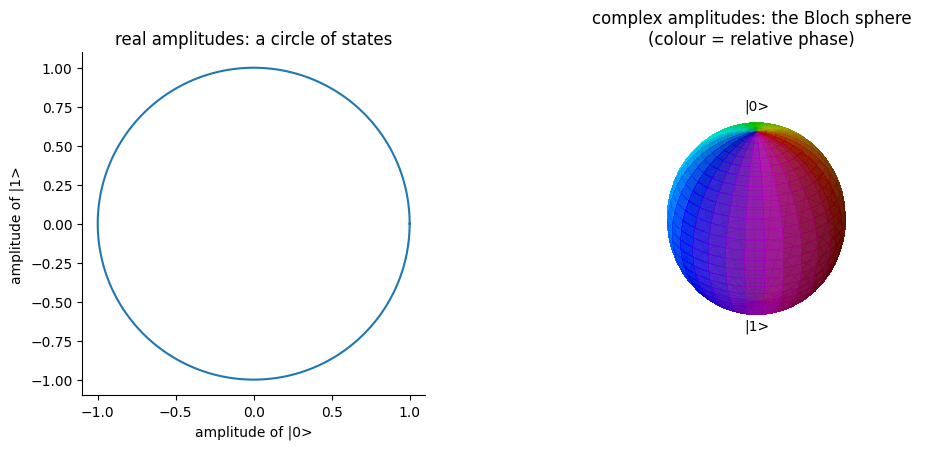

In [98]:
fig = plt.figure(figsize=(11, 4.6))

# real amplitudes only: the unit circle of states (cos t, sin t)
ax = fig.add_subplot(1, 2, 1)
t = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(t), np.sin(t), color="tab:blue")
ax.set_aspect("equal"); ax.set_xlabel("amplitude of |0>"); ax.set_ylabel("amplitude of |1>")
ax.set_title("real amplitudes: a circle of states")

# complex amplitudes: the Bloch sphere (state (cos th/2, e^{i ph} sin th/2) -> point on the sphere)
ax = fig.add_subplot(1, 2, 2, projection="3d")
th, ph = np.meshgrid(np.linspace(0, np.pi, 30), np.linspace(0, 2 * np.pi, 60))
X, Y, Z = np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)
ax.plot_surface(X, Y, Z, facecolors=plt.cm.hsv(ph / (2 * np.pi)), alpha=0.8, linewidth=0, antialiased=False)
ax.text(0, 0, 1.25, "|0>", ha="center"); ax.text(0, 0, -1.35, "|1>", ha="center")
ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
ax.set_title("complex amplitudes: the Bloch sphere\n(colour = relative phase)")
plt.tight_layout(); plt.show()

### 3.4 Example for an ML engineer — a Hilbert space is a *feature space*

You have already used Hilbert spaces: the **kernel trick**. A feature map $\phi:\mathcal{X}\to\mathcal{H}$ sends data into a Hilbert space, and a kernel is the inner product there:

$$k(x, y) = \langle \phi(x), \phi(y)\rangle$$

Quantum machine learning does exactly this, with one twist: **$\phi(x)$ is a quantum state** — a unit vector in $\mathbb{C}^{2^n}$ prepared by a circuit. The "model" is then a kernel method (or a linear model) in that Hilbert space.

Below: the classical polynomial kernel evaluated two ways (explicit features vs. kernel), then a tiny **quantum-style feature map** $x\mapsto(\cos x, \sin x)$ whose kernel is $\cos^2(x-y)$.

In [99]:
# 1) Classical: polynomial kernel k(x,y) = (x·y)^2  <=>  explicit feature map in a bigger space
def phi_poly(x):                       # for x in R^2 : (x1², √2 x1x2, x2²)
    return np.array([x[0]**2, np.sqrt(2) * x[0] * x[1], x[1]**2])

x, y = np.array([1.0, 2.0]), np.array([3.0, -0.5])
print("kernel            :", (x @ y) ** 2)
print("<phi(x), phi(y)>  :", phi_poly(x) @ phi_poly(y))

kernel            : 4.0
<phi(x), phi(y)>  : 3.9999999999999987


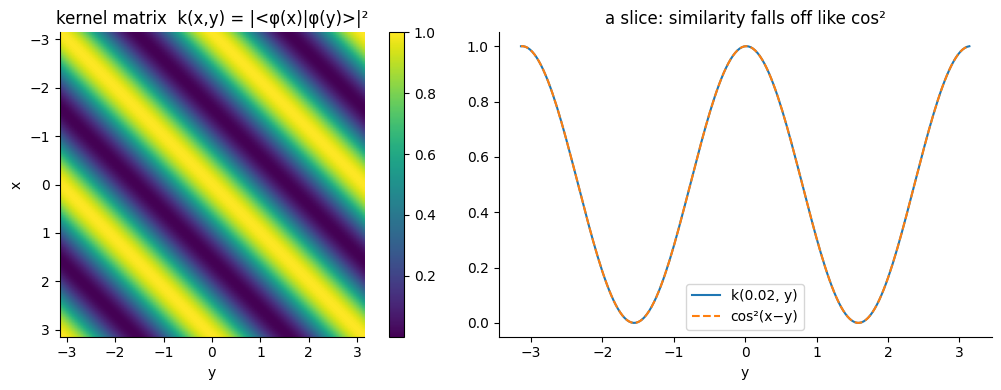

In [100]:
# 2) Quantum-style feature map: x -> unit vector (cos x, sin x)  (this is 'angle encoding', Week 3)
def phi_quantum(x):
    return np.array([np.cos(x), np.sin(x)], dtype=complex)

def quantum_kernel(x, y):
    return np.abs(np.vdot(phi_quantum(x), phi_quantum(y))) ** 2    # |<phi(x)|phi(y)>|^2

xs = np.linspace(-np.pi, np.pi, 200)
K = np.array([[quantum_kernel(a, b) for b in xs] for a in xs])

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
im = axs[0].imshow(K, extent=[-np.pi, np.pi, np.pi, -np.pi], cmap="viridis")
axs[0].set_title("kernel matrix  k(x,y) = |<φ(x)|φ(y)>|²"); axs[0].set_xlabel("y"); axs[0].set_ylabel("x")
plt.colorbar(im, ax=axs[0])
i0 = 100                                              # slice at x = xs[i0]
axs[1].plot(xs, K[i0], label=f"k({xs[i0]:.2f}, y)")
axs[1].plot(xs, np.cos(xs - xs[i0]) ** 2, "--", label="cos²(x−y)")
axs[1].set_title("a slice: similarity falls off like cos²"); axs[1].set_xlabel("y"); axs[1].legend()
plt.tight_layout(); plt.show()

---
## 4. Inner product

For $u, v\in\mathbb{C}^n$:

$$\langle u | v\rangle = \sum_i \overline{u_i}\, v_i, \qquad \|v\| = \sqrt{\langle v|v\rangle}$$

Two differences from the real dot product:
- the **first argument is conjugated** (so $\langle v|v\rangle$ is real and $\ge 0$);
- $\langle u|v\rangle$ is **complex in general** — its modulus is the "overlap", its angle is a relative phase.

`np.vdot(u, v)` conjugates the first argument — use it, not `u @ v`.

Key facts:

| Fact | Statement |
|---|---|
| Orthogonal | $\langle u\vert v\rangle = 0$ |
| Cauchy–Schwarz | $\lvert\langle u\vert v\rangle\rvert \le \lVert u\rVert\,\lVert v\rVert$ |
| Unit vector (valid quantum state) | $\lVert v\rVert = 1$ |
| **Born rule preview** | probability of outcome $i$ = $\lvert\langle i\vert\psi\rangle\rvert^2$ |

In [101]:
u = np.array([1, 1j]) / np.sqrt(2)
v = np.array([1, -1j]) / np.sqrt(2)

print("<u|v>        =", np.vdot(u, v), "   -> orthogonal!")
print("<u|u>        =", np.vdot(u, u))
print("u @ u (WRONG)=", u @ u, "   <- no conjugate, not a norm")
print("np.linalg.norm(u) =", np.linalg.norm(u))

<u|v>        = (-2.2371143170757382e-17+0j)    -> orthogonal!
<u|u>        = (0.9999999999999998+0j)
u @ u (WRONG)= (-2.2371143170757382e-17+0j)    <- no conjugate, not a norm
np.linalg.norm(u) = 0.9999999999999999


### Angle between states

The inner product also gives an **angle** between two states:

$$\cos\theta=\frac{\lvert\langle u|v\rangle\rvert}{\lVert u\rVert\,\lVert v\rVert},\qquad \theta\in[0^\circ,90^\circ]$$

so the overlap probability is $\lvert\langle u|v\rangle\rvert^2=\cos^2\theta$ for unit vectors. Orthogonal states have $\theta=90^\circ$. The modulus makes the angle blind to a global phase.

> **Hilbert-space angle vs. Bloch-sphere angle.** On the Bloch sphere the same pair of states is **twice** as far apart. $|0\rangle$ and $|1\rangle$ are orthogonal ($90^\circ$ in Hilbert space) yet sit at opposite poles ($180^\circ$ on the sphere).

In [102]:
k0, k1 = np.array([1, 0], dtype=complex), np.array([0, 1], dtype=complex)
kplus, kminus, kplus_i = (k0 + k1) / np.sqrt(2), (k0 - k1) / np.sqrt(2), (k0 + 1j * k1) / np.sqrt(2)

def state_angle(u, v):
    c = abs(np.vdot(u, v)) / (np.linalg.norm(u) * np.linalg.norm(v))
    return np.degrees(np.arccos(np.clip(c, 0, 1)))

def bloch(psi):
    a, b = psi / np.linalg.norm(psi)
    return np.array([2 * (np.conj(a) * b).real, 2 * (np.conj(a) * b).imag, abs(a) ** 2 - abs(b) ** 2])

pairs = {"|0>, |1>": (k0, k1), "|0>, |+>": (k0, kplus), "|+>, |->": (kplus, kminus), "|0>, |+i>": (k0, kplus_i), "|+>, |+> (global phase i)": (kplus, 1j * kplus)}
print(f"{'pair':28s} {'Hilbert angle':>14s} {'Bloch angle':>12s}")
for name, (u_, v_) in pairs.items():
    ba = np.degrees(np.arccos(np.clip(bloch(u_) @ bloch(v_), -1, 1)))
    print(f"{name:28s} {state_angle(u_, v_):14.1f} {ba:12.1f}")

pair                          Hilbert angle  Bloch angle
|0>, |1>                               90.0        180.0
|0>, |+>                               45.0         90.0
|+>, |->                               90.0        180.0
|0>, |+i>                              45.0         90.0
|+>, |+> (global phase i)               0.0          0.0


### Visualization — overlap as a function of angle

Take the real unit vectors $a=(1,0)$ and $b=(\cos t,\sin t)$. The **cosine similarity** is $\cos t$; the quantum overlap probability is its **square**, $|\langle a|b\rangle|^2=\cos^2 t$. Orthogonal vectors ($t=\pi/2$) have zero overlap; parallel ones have overlap 1.

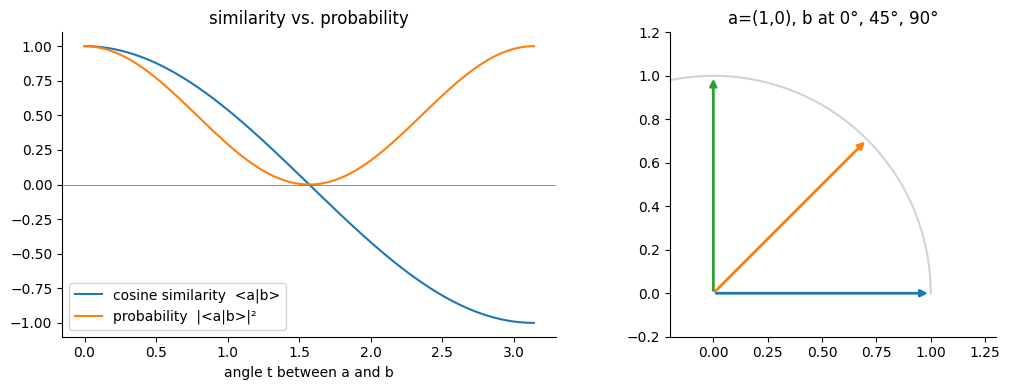

In [103]:
t = np.linspace(0, np.pi, 300)
a = np.array([1.0, 0.0])
overlap = np.array([np.vdot(a, [np.cos(ti), np.sin(ti)]) for ti in t])

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(t, overlap.real, label="cosine similarity  <a|b>")
axs[0].plot(t, np.abs(overlap) ** 2, label="probability  |<a|b>|²")
axs[0].axhline(0, color="gray", lw=0.6)
axs[0].set_xlabel("angle t between a and b"); axs[0].legend(); axs[0].set_title("similarity vs. probability")

for ti, c in zip([0, np.pi / 4, np.pi / 2], ["tab:blue", "tab:orange", "tab:green"]):
    axs[1].annotate("", xy=(np.cos(ti), np.sin(ti)), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2))
axs[1].plot(np.cos(t), np.sin(t), color="lightgray"); axs[1].set_aspect("equal")
axs[1].set_title("a=(1,0), b at 0°, 45°, 90°"); axs[1].set_xlim(-0.2, 1.3); axs[1].set_ylim(-0.2, 1.2)
plt.tight_layout(); plt.show()

### Example for an ML engineer — cosine similarity *is* the overlap

For real embeddings, **cosine similarity** is $\langle\hat a|\hat b\rangle$ with $\hat a=a/\lVert a\rVert$. Quantum states are complex, so the overlap is the Hermitian inner product, and the physically meaningful number is its **modulus** — which is invariant to a global phase, unlike the naive no-conjugate product `a @ b`. The same applies to complex embeddings such as FFT features or ComplEx knowledge-graph embeddings.

In [104]:
# real embeddings: cosine similarity == inner product of the normalized vectors
a_r, b_r = rng.normal(size=8), rng.normal(size=8)
print("cosine similarity       :", a_r @ b_r / (np.linalg.norm(a_r) * np.linalg.norm(b_r)))
print("<a_hat|b_hat>           :", np.vdot(a_r / np.linalg.norm(a_r), b_r / np.linalg.norm(b_r)))

# complex embeddings: |<a|b>| ignores global phase, a @ b does not
a_c = rng.normal(size=8) + 1j * rng.normal(size=8)
b_c = rng.normal(size=8) + 1j * rng.normal(size=8)
b_c2 = np.exp(1j * 1.1) * b_c                              # same state, different global phase
print("\n|<a|b>|  :", abs(np.vdot(a_c, b_c)), "  |<a|b e^{i g}>| :", abs(np.vdot(a_c, b_c2)))
print("a @ b     :", a_c @ b_c, "  a @ (b e^{i g}) :", a_c @ b_c2, "  <- changes!")

cosine similarity       : -0.081836491322079
<a_hat|b_hat>           : -0.08183649132207896

|<a|b>|  : 4.931098065250722   |<a|b e^{i g}>| : 4.931098065250722
a @ b     : (-0.8050849356723224+2.6082759996907745j)   a @ (b e^{i g}) : (-2.6896981722351425+0.4656062569213941j)   <- changes!


---
## 5. Norm and normalization

### 5.1 Norm = length

$$\lVert v\rVert=\sqrt{\langle v|v\rangle}=\sqrt{\sum_i\lvert v_i\rvert^2}$$

It is the length of the vector, built from the **moduli** of the amplitudes (so complex entries still give a real length).

| Property | Statement |
|---|---|
| Positive | $\lVert v\rVert\ge0$, and $=0$ only for $v=0$ |
| Homogeneous | $\lVert c\,v\rVert=\lvert c\rvert\,\lVert v\rVert$ |
| Triangle inequality | $\lVert u+v\rVert\le\lVert u\rVert+\lVert v\rVert$ |
| **Phase-blind** | $\lVert e^{i\gamma}v\rVert=\lVert v\rVert$ |

### 5.2 Normalization

Dividing by the length gives a **unit vector**: $\hat v=v/\lVert v\rVert$.

**Why quantum states must be normalized.** The Born rule says outcome $i$ has probability $\lvert v_i\rvert^2$. Probabilities must sum to 1, i.e. $\sum_i\lvert v_i\rvert^2=\lVert v\rVert^2=1$. So a **normalized quantum state is exactly a unit vector** in the Hilbert space.

- Normalizing removes only the overall scale. The **ratios** of amplitudes and the **relative phases** are untouched — vectors that differ by a nonzero complex factor describe the same state.
- Example: $(1,\,2i)$ has $\lVert\cdot\rVert^2=1+4=5$, so the state is $(1,\,2i)/\sqrt5$ with probabilities $(0.2,\,0.8)$.

In [105]:
def norm(v): return np.sqrt(np.vdot(v, v).real)
def normalize(v):
    n = norm(v); assert n > 0, "cannot normalize the zero vector"
    return v / n

v = np.array([1, 2j]); w = np.array([0.5 - 1j, 2.0 + 0.3j])
print("||v||                     :", norm(v), "  (sqrt 5 =", np.sqrt(5), ")")
print("||c v|| = |c| ||v||        :", norm((2 + 1j) * v), "=", abs(2 + 1j) * norm(v))
print("triangle ||v+w|| <= sum    :", norm(v + w), "<=", norm(v) + norm(w))
print("global phase keeps norm    :", norm(np.exp(1j * 0.7) * v))

vhat = normalize(v)
print("\nnormalized                 :", vhat, "  norm =", norm(vhat))
print("probabilities |v_i|^2      :", np.abs(vhat) ** 2, "  sum =", np.sum(np.abs(vhat) ** 2))
print("relative phase preserved   :", np.angle(vhat[1]) - np.angle(vhat[0]), "=", np.angle(v[1]) - np.angle(v[0]))

||v||                     : 2.23606797749979   (sqrt 5 = 2.23606797749979 )
||c v|| = |c| ||v||        : 5.0 = 5.000000000000001
triangle ||v+w|| <= sum    : 3.5411862419251547 <= 4.546911979158058
global phase keeps norm    : 2.23606797749979

normalized                 : [0.4472+0.j     0.    +0.8944j]   norm = 0.9999999999999999
probabilities |v_i|^2      : [0.2 0.8]   sum = 0.9999999999999999
relative phase preserved   : 1.5707963267948966 = 1.5707963267948966


### Visualization — normalizing

Left: vectors of different lengths all land on the **unit circle** after normalization, keeping their direction. Right: the squared moduli of $(1,2i)$ before normalization sum to 5 — not probabilities — and after normalization sum to 1.

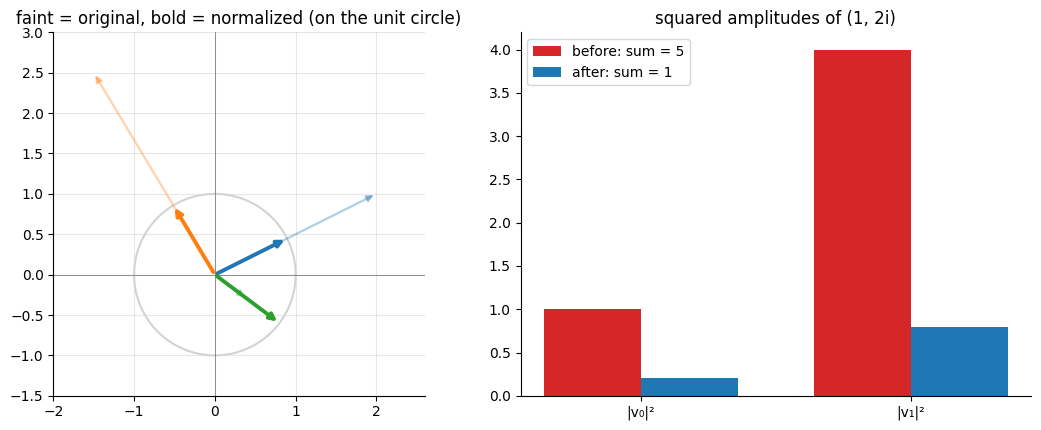

In [106]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

ax = axs[0]
t = np.linspace(0, 2 * np.pi, 200); ax.plot(np.cos(t), np.sin(t), color="lightgray")
for vec, c in zip([np.array([2.0, 1.0]), np.array([-1.5, 2.5]), np.array([0.4, -0.3])], ["tab:blue", "tab:orange", "tab:green"]):
    ax.annotate("", xy=vec, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=1.6, alpha=0.35))
    nv = vec / np.linalg.norm(vec)
    ax.annotate("", xy=nv, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.8))
ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
ax.set_aspect("equal"); ax.set_xlim(-2, 2.6); ax.set_ylim(-1.5, 3); ax.grid(alpha=0.3)
ax.set_title("faint = original, bold = normalized (on the unit circle)")

ax = axs[1]
before, after = np.abs(v) ** 2, np.abs(vhat) ** 2
x = np.arange(2); w_ = 0.36
ax.bar(x - w_ / 2, before, w_, label=f"before: sum = {before.sum():.0f}", color="tab:red")
ax.bar(x + w_ / 2, after, w_, label=f"after: sum = {after.sum():.0f}", color="tab:blue")
ax.set_xticks(x); ax.set_xticklabels(["|v₀|²", "|v₁|²"]); ax.legend(); ax.set_title("squared amplitudes of (1, 2i)")
plt.tight_layout(); plt.show()

### Example for an ML engineer — L2-normalized embeddings *are* quantum states

Take any embedding $e\in\mathbb{R}^d$. After $e\mapsto e/\|e\|$ it is a valid (real) state, and:

- **cosine similarity** of two embeddings = their inner product $\langle a|b\rangle$;
- squaring the entries of a unit vector gives a **probability distribution** — like softmax, but with a different nonlinearity ($p_i = z_i^2$ instead of $e^{z_i}/\sum e^{z_j}$).

That second point *is* the Born rule: a quantum model outputs $p_i=|\psi_i|^2$.

softmax : [0.16   0.3099 0.0443 0.2386 0.2471]   sum = 1.0
born    : [0.     0.1772 0.6826 0.0642 0.076 ]   sum = 1.0


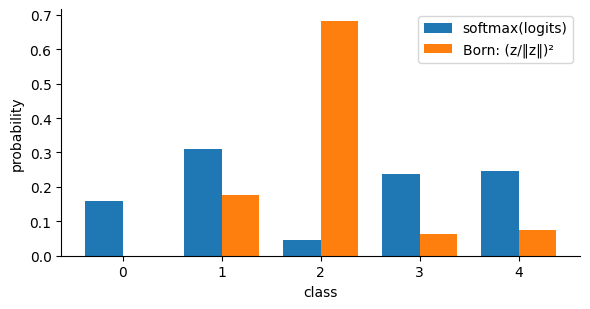

In [107]:
logits = rng.normal(size=5)
softmax = np.exp(logits) / np.exp(logits).sum()

state = logits / np.linalg.norm(logits)          # L2-normalize -> valid "quantum state"
born = state ** 2                                 # Born rule

print("softmax :", softmax, "  sum =", softmax.sum())
print("born    :", born,    "  sum =", born.sum())

fig, ax = plt.subplots(figsize=(6, 3.2))
w = 0.38; i = np.arange(5)
ax.bar(i - w/2, softmax, w, label="softmax(logits)"); ax.bar(i + w/2, born, w, label="Born: (z/‖z‖)²")
ax.set_xlabel("class"); ax.set_ylabel("probability"); ax.legend(); plt.tight_layout(); plt.show()

---
## 6. Basis and change of basis

**Dirac (bra–ket) notation** is just compact linear algebra:

| Notation | Meaning | numpy |
|---|---|---|
| $\lvert v\rangle$ ("ket") | column vector | `v` |
| $\langle v\rvert$ ("bra") | conjugate transpose (row) | `v.conj()` |
| $\langle u\vert v\rangle$ | inner product (a number) | `np.vdot(u, v)` |
| $\lvert u\rangle\langle v\rvert$ | outer product (a matrix) | `np.outer(u, v.conj())` |

An **orthonormal basis** $\{|e_i\rangle\}$ satisfies $\langle e_i|e_j\rangle=\delta_{ij}$. Any state expands as

$$|\psi\rangle = \sum_i c_i |e_i\rangle, \qquad c_i = \langle e_i|\psi\rangle, \qquad \sum_i |c_i|^2 = 1$$

and the projectors $|e_i\rangle\langle e_i|$ sum to the identity (**completeness**). Two bases for a qubit you will use constantly:

- computational (Z) basis: $|0\rangle, |1\rangle$
- Hadamard (X) basis: $|\pm\rangle = (|0\rangle\pm|1\rangle)/\sqrt2$

In [108]:
ket0 = np.array([1, 0], dtype=complex)
ket1 = np.array([0, 1], dtype=complex)
plus  = (ket0 + ket1) / np.sqrt(2)
minus = (ket0 - ket1) / np.sqrt(2)

Z_basis = [ket0, ket1]
X_basis = [plus, minus]

# completeness: sum of projectors = identity
print(sum(np.outer(e, e.conj()) for e in Z_basis).real)
print(sum(np.outer(e, e.conj()) for e in X_basis).real)

def coefficients(psi, basis):
    return np.array([np.vdot(e, psi) for e in basis])

[[1. 0.]
 [0. 1.]]
[[1. 0.]
 [0. 1.]]


### Change of basis as a matrix

Stack an orthonormal basis as the **columns** of a matrix $B=[\,e_1\;e_2\;\cdots\,]$. Then

$$c = B^\dagger\psi\quad(\text{coordinates in the new basis}),\qquad \psi=B\,c\quad(\text{back to the old}).$$

$B$ is **unitary**, so the change of basis preserves lengths. For the Hadamard (X) basis, $B=[\,|+\rangle\;|-\rangle\,]=\tfrac1{\sqrt2}\begin{bmatrix}1&1\\1&-1\end{bmatrix}$ — the **Hadamard matrix**. That is why the Hadamard *gate* turns "Z-basis questions" into "X-basis questions".

*(If the basis is not orthonormal you need $B^{-1}$ instead of $B^\dagger$.)*

In [109]:
Hh = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
B = np.column_stack(X_basis)                         # columns: |+>, |->
psi = np.array([3 / 5, 4j / 5])

c = B.conj().T @ psi                                 # coordinates in the X basis
print("B == Hadamard matrix :", np.allclose(B, Hh))
print("B unitary            :", np.allclose(B.conj().T @ B, np.eye(2)))
print("coordinates c        :", c, "   sum |c|^2 =", np.sum(np.abs(c) ** 2))
print("matches coefficients():", np.allclose(c, coefficients(psi, X_basis)))
print("round trip  B c == psi:", np.allclose(B @ c, psi))

B == Hadamard matrix : True
B unitary            : True
coordinates c        : [0.4243+0.5657j 0.4243-0.5657j]    sum |c|^2 = 0.9999999999999998
matches coefficients(): True
round trip  B c == psi: True


### Visualization — same state, two bases

The state is a fixed arrow; the **coefficients** depend on which axes you measure against. Rotating the axes by 45° turns "50/50" into "100/0".

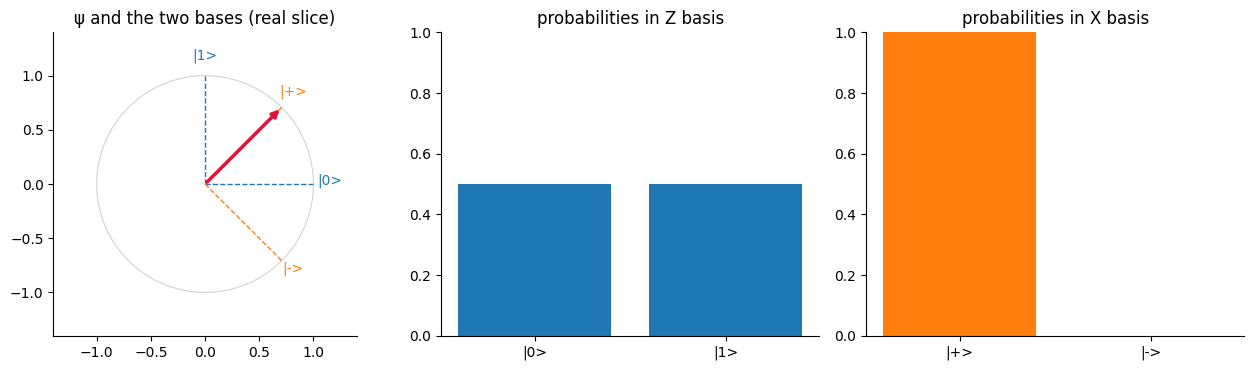

In [110]:
psi = plus                                         # try: ket0, minus, or a random normalized vector

pz = np.abs(coefficients(psi, Z_basis)) ** 2
px = np.abs(coefficients(psi, X_basis)) ** 2

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))

# real-plane picture: arrow psi, with Z axes and X axes
t = np.linspace(0, 2 * np.pi, 200)
axs[0].plot(np.cos(t), np.sin(t), color="lightgray", lw=0.8)
for e, c, lab in [(ket0, "tab:blue", "|0>"), (ket1, "tab:blue", "|1>"), (plus, "tab:orange", "|+>"), (minus, "tab:orange", "|->")]:
    axs[0].plot([0, e[0].real], [0, e[1].real], color=c, lw=1, ls="--")
    axs[0].text(e[0].real * 1.15, e[1].real * 1.15, lab, color=c, ha="center")
axs[0].annotate("", xy=(psi[0].real, psi[1].real), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="crimson", lw=2.5))
axs[0].set_aspect("equal"); axs[0].set_xlim(-1.4, 1.4); axs[0].set_ylim(-1.4, 1.4); axs[0].set_title("ψ and the two bases (real slice)")

axs[1].bar(["|0>", "|1>"], pz, color="tab:blue"); axs[1].set_ylim(0, 1); axs[1].set_title("probabilities in Z basis")
axs[2].bar(["|+>", "|->"], px, color="tab:orange"); axs[2].set_ylim(0, 1); axs[2].set_title("probabilities in X basis")
plt.tight_layout(); plt.show()

### Example for an ML engineer — coefficients are PCA-style coordinates

Computing $c_i=\langle e_i|\psi\rangle$ is exactly projecting a vector onto an orthonormal basis, as in **PCA**: the principal components form an orthonormal basis, and the "scores" are inner products with them. Changing the measurement basis in QML is the same as choosing different principal axes — the vector is unchanged, only its coordinates are.

Below, an orthonormal basis from PCA of random 2-D data; the squared normalized scores play the role of measurement probabilities.

In [111]:
X = rng.normal(size=(500, 2)) @ np.array([[2.0, 0.5], [0.0, 0.6]])
X -= X.mean(0)
_, _, Vt = np.linalg.svd(X, full_matrices=False)        # rows of Vt: orthonormal basis (principal axes)

x0 = X[0] / np.linalg.norm(X[0])                         # one sample, as a unit vector
scores_pca = Vt @ x0                                     # coefficients  c_i = <e_i|x>
scores_std = np.eye(2) @ x0                              # coefficients in the standard basis

print("Σ c_i² (PCA basis)      :", np.sum(scores_pca ** 2))
print("Σ c_i² (standard basis) :", np.sum(scores_std ** 2))
print("same vector, different coordinates:", scores_std, "vs", scores_pca)

Σ c_i² (PCA basis)      : 0.9999999999999997
Σ c_i² (standard basis) : 0.9999999999999999
same vector, different coordinates: [ 0.9784 -0.2069] vs [-0.891  -0.4539]


---
## 7. Linear transformations: matrices acting on vectors

### 7.1 What a linear map is

A map $A:\mathbb{C}^n\to\mathbb{C}^m$ is **linear** if

$$A(\alpha u+\beta v)=\alpha\,Au+\beta\,Av.$$

Every linear map is a **matrix**, and the matrix is read off from what it does to the basis vectors: **column $j$ of $A$ is $A e_j$**. Applying it is the matrix–vector product $(A\psi)_i=\sum_jA_{ij}\psi_j$.

- **Superposition principle.** Quantum evolution is linear: a gate acts on every branch of a superposition separately.
- **Composition is multiplication, and order matters.** "First $A$, then $B$" is $BA$, and $AB\neq BA$ in general (for instance $XZ=-ZX$).
- **Matrix elements:** $A_{ij}=\langle e_i|A|e_j\rangle$, and $A=\sum_{ij}A_{ij}\,|e_i\rangle\langle e_j|$ (outer products).
- The **adjoint** $A^\dagger=\overline{A}^{\,T}$ satisfies $\langle u|Av\rangle=\langle A^\dagger u|v\rangle$.

In [112]:
Xg = np.array([[0, 1], [1, 0]], dtype=complex)
Zg = np.array([[1, 0], [0, -1]], dtype=complex)
Hg = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

a, b = 0.3 + 0.4j, -0.2 + 0.9j
u2 = np.array([0.6, 0.8j]); v2 = np.array([1, 1j]) / np.sqrt(2)
print("linearity     :", np.allclose(Hg @ (a * u2 + b * v2), a * (Hg @ u2) + b * (Hg @ v2)))

print("column 0 of H :", Hg[:, 0], "= H|0> =", Hg @ ket0)
print("<0|H|1>       :", np.vdot(ket0, Hg @ ket1), "= H[0,1] =", Hg[0, 1])
print("X from outer products |0><1| + |1><0| :\n", np.outer(ket0, ket1.conj()) + np.outer(ket1, ket0.conj()))

print("\nXZ == ZX  :", np.allclose(Xg @ Zg, Zg @ Xg))
print("XZ == -ZX :", np.allclose(Xg @ Zg, -Zg @ Xg))
print("adjoint rule <u|Av> = <A†u|v> :", np.isclose(np.vdot(u2, Hg @ v2 * 1j), np.vdot((1j * Hg).conj().T @ u2, v2)))

linearity     : True
column 0 of H : [0.7071+0.j 0.7071+0.j] = H|0> = [0.7071+0.j 0.7071+0.j]
<0|H|1>       : (0.7071067811865475+0j) = H[0,1] = (0.7071067811865475+0j)
X from outer products |0><1| + |1><0| :
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

XZ == ZX  : False
XZ == -ZX : True
adjoint rule <u|Av> = <A†u|v> : True


### Visualization — a matrix moves the whole grid

A real $2\times2$ matrix drags the coordinate grid. The two coloured arrows are the **columns** $Ae_1$ and $Ae_2$: they say where the basis vectors land, and so determine where *everything* lands. Straight lines stay straight and the origin stays fixed — that is what "linear" looks like.

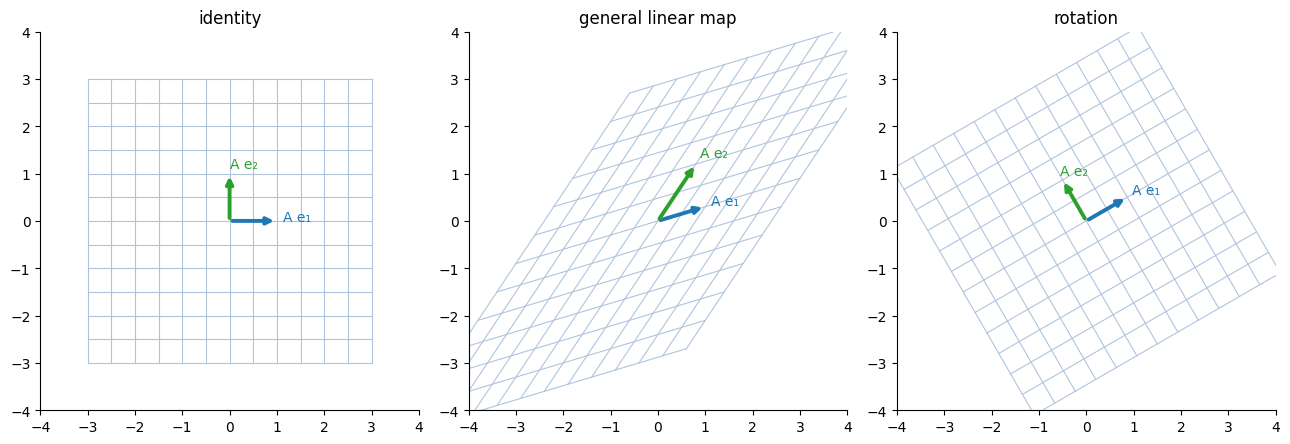

In [113]:
def draw_grid(ax, M, title):
    ks = np.linspace(-3, 3, 13)
    for k in ks:
        for line in (np.array([[k, k], [-3, 3]]), np.array([[-3, 3], [k, k]])):
            p = M @ line
            ax.plot(p[0], p[1], color="lightsteelblue", lw=0.8)
    for col, c, lab in ((M[:, 0], "tab:blue", "A e₁"), (M[:, 1], "tab:green", "A e₂")):
        ax.annotate("", xy=col, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.8))
        ax.text(col[0] * 1.12, col[1] * 1.12, lab, color=c)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_title(title)

ang = np.deg2rad(30)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4))
draw_grid(axs[0], np.eye(2), "identity")
draw_grid(axs[1], np.array([[1.0, 0.8], [0.3, 1.2]]), "general linear map")
draw_grid(axs[2], np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]]), "rotation")
plt.tight_layout(); plt.show()

### Example for an ML engineer — a stack of linear layers is one matrix

A dense layer without activation is a linear map $y=Wx$; the columns of $W$ are the images of the input features. Two such layers collapse into **one** matrix $W_2W_1$ — the reason you need nonlinearities. A quantum circuit is the same: ten gates multiply into **one** unitary. The only nonlinearity in a quantum model enters through **measurement** (squaring the amplitudes) and through how the data is encoded.

In [114]:
W1, W2 = rng.normal(size=(4, 3)), rng.normal(size=(2, 4))
x = rng.normal(size=3)
print("two linear layers == one matrix W2@W1 :", np.allclose(W2 @ (W1 @ x), (W2 @ W1) @ x))

U = Hg @ Zg @ Hg @ Xg @ Hg                         # five gates -> one 2x2 matrix
step = Hg @ (Xg @ (Hg @ (Zg @ (Hg @ ket0))))
print("circuit collapses to a single matrix  :", np.allclose(U @ ket0, step), "\n", U)

psi = U @ ket0
print("\ndoubling the input state: amplitudes x2, probabilities x4 ->", np.abs(2 * psi) ** 2 / np.abs(psi) ** 2)

two linear layers == one matrix W2@W1 : True
circuit collapses to a single matrix  : True 
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

doubling the input state: amplitudes x2, probabilities x4 -> [4. 4.]


---
## 8. Eigenvalues and eigenvectors

### 8.1 The eigenvalue equation

$$A\,|v\rangle=\lambda\,|v\rangle,\qquad |v\rangle\neq0$$

Most vectors change direction when a matrix acts on them. **Eigenvectors are the special directions that $A$ only stretches** — by the **eigenvalue** $\lambda\in\mathbb{C}$ (a negative or complex $\lambda$ flips or phase-rotates the vector). They are found from $\det(A-\lambda I)=0$.

### 8.2 What eigenvalues mean in quantum computing

**Hermitian matrices ($H^\dagger=H$) — observables.**
- eigenvalues are **real**, eigenvectors for different eigenvalues are **orthogonal**, and they form an orthonormal basis;
- **spectral decomposition:** $O=\sum_k\lambda_k\,|v_k\rangle\langle v_k|$;
- **measuring $O$** returns an eigenvalue $\lambda_k$ with probability $\lvert\langle v_k|\psi\rangle\rvert^2$ and leaves the state in $|v_k\rangle$; the average is $\langle O\rangle=\sum_k\lambda_kp_k=\langle\psi|O|\psi\rangle$.

**Unitary matrices — gates.** Eigenvalues have modulus 1, $\lambda=e^{i\varphi}$: the gate only applies a **phase** to its eigenvectors.

| Matrix | Eigenvalues | Eigenvectors |
|---|---|---|
| $Z$ | $+1,\,-1$ | $\lvert0\rangle,\,\lvert1\rangle$ (computational basis) |
| $X$ | $+1,\,-1$ | $\lvert+\rangle,\,\lvert-\rangle$ (Hadamard basis) |
| $Y$ | $+1,\,-1$ | $\lvert{+i}\rangle,\,\lvert{-i}\rangle$ |
| $S=\mathrm{diag}(1,i)$ | $1,\,i$ | $\lvert0\rangle,\,\lvert1\rangle$ |
| $R_Z(\theta)$ | $e^{-i\theta/2},\,e^{+i\theta/2}$ | $\lvert0\rangle,\,\lvert1\rangle$ |

So "measure in the computational basis" means "measure $Z$", and "measure in the Hadamard basis" means "measure $X$" — the bases of section 6 are the eigenbases of these observables.

In [115]:
Yg = np.array([[0, -1j], [1j, 0]])
Sg = np.diag([1, 1j])
def rz(t): return np.diag([np.exp(-0.5j * t), np.exp(0.5j * t)])

# Hermitian observables: real eigenvalues, A v = lambda v
for name, M in {"Z": Zg, "X": Xg, "Y": Yg}.items():
    vals, vecs = np.linalg.eigh(M)
    ok = all(np.allclose(M @ vecs[:, k], vals[k] * vecs[:, k]) for k in range(2))
    print(f"{name}: eigenvalues {vals}   A v = lambda v for all: {ok}   eigenvectors orthonormal: {np.allclose(vecs.conj().T @ vecs, np.eye(2))}")

# spectral decomposition + measurement statistics of X on a state
vals, vecs = np.linalg.eigh(Xg)
rebuilt = sum(l * np.outer(vecs[:, k], vecs[:, k].conj()) for k, l in enumerate(vals))
print("\nX = sum lambda |v><v| :", np.allclose(rebuilt, Xg))

psi = np.array([3 / 5, 4 / 5], dtype=complex)
p = np.abs(vecs.conj().T @ psi) ** 2
print("measuring X on psi -> outcomes", vals, "with probabilities", p)
print("<X> = sum lambda p    :", np.sum(vals * p), "   <psi|X|psi> =", np.vdot(psi, Xg @ psi).real)

# unitary: eigenvalues on the unit circle
Q, _ = np.linalg.qr(rng.normal(size=(3, 3)) + 1j * rng.normal(size=(3, 3)))
print()
for name, U_ in {"H": Hg, "S": Sg, "RZ(0.7)": rz(0.7), "random 3x3 unitary": Q}.items():
    ev = np.linalg.eigvals(U_)
    print(f"{name:20s} eigenvalues {np.round(ev, 3)}   |lambda| = {np.round(np.abs(ev), 6)}")

Z: eigenvalues [-1.  1.]   A v = lambda v for all: True   eigenvectors orthonormal: True
X: eigenvalues [-1.  1.]   A v = lambda v for all: True   eigenvectors orthonormal: True
Y: eigenvalues [-1.  1.]   A v = lambda v for all: True   eigenvectors orthonormal: True

X = sum lambda |v><v| : True
measuring X on psi -> outcomes [-1.  1.] with probabilities [0.02 0.98]
<X> = sum lambda p    : 0.9599999999999999    <psi|X|psi> = 0.96

H                    eigenvalues [ 1.+0.j -1.+0.j]   |lambda| = [1. 1.]
S                    eigenvalues [1.+0.j 0.+1.j]   |lambda| = [1. 1.]
RZ(0.7)              eigenvalues [0.939-0.343j 0.939+0.343j]   |lambda| = [1. 1.]
random 3x3 unitary   eigenvalues [ 0.708-0.706j -0.962-0.275j -0.461+0.887j]   |lambda| = [1. 1. 1.]


### Visualization — eigenvectors keep their direction

Left: a symmetric matrix $A=\begin{bmatrix}2&1\\1&2\end{bmatrix}$ turns the unit circle into an ellipse. Along its two eigenvectors the matrix acts as **pure stretching**: the green unit eigenvector maps to the red arrow on the same line, scaled by $\lambda$ (3 and 1). Right: where eigenvalues live in the complex plane — **Hermitian** matrices on the real axis, **unitary** matrices on the unit circle.

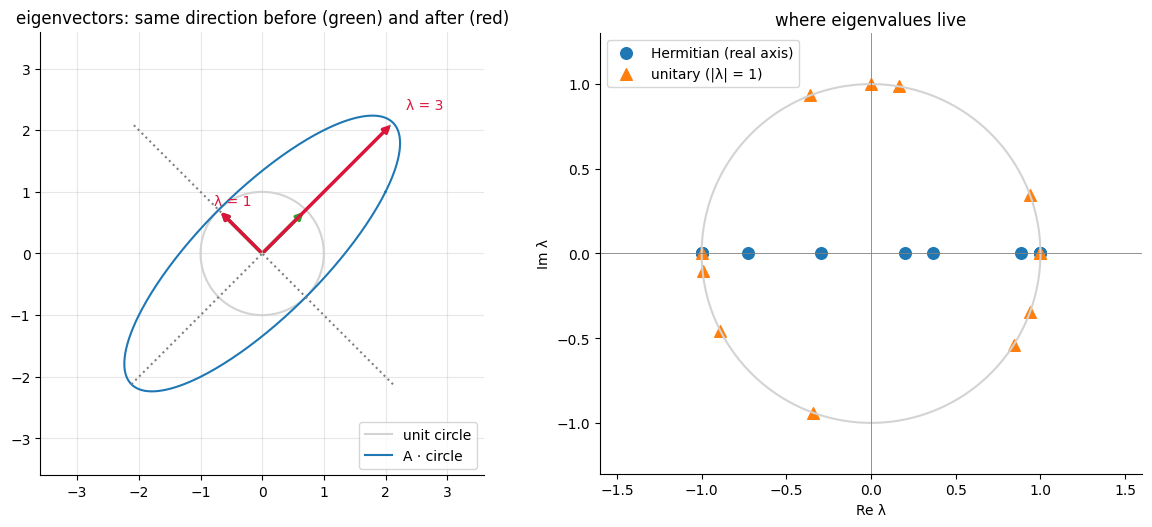

In [116]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2))

# --- left: ellipse and eigen-axes
A = np.array([[2.0, 1.0], [1.0, 2.0]])
lam, V = np.linalg.eigh(A)
t = np.linspace(0, 2 * np.pi, 300)
P = np.vstack([np.cos(t), np.sin(t)]); E = A @ P
ax = axs[0]
ax.plot(P[0], P[1], color="lightgray", label="unit circle"); ax.plot(E[0], E[1], color="tab:blue", label="A · circle")
for k, c in zip(range(2), ["tab:orange", "tab:red"]):
    v = V[:, k]
    ax.plot([-3 * v[0], 3 * v[0]], [-3 * v[1], 3 * v[1]], ":", color="gray")
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="tab:green", lw=2.5))
    ax.annotate("", xy=lam[k] * v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="crimson", lw=2.5))
    ax.text(*(lam[k] * v * 1.1), f"λ = {lam[k]:.0f}", color="crimson")
ax.set_aspect("equal"); ax.set_xlim(-3.6, 3.6); ax.set_ylim(-3.6, 3.6); ax.grid(alpha=0.3); ax.legend(loc="lower right")
ax.set_title("eigenvectors: same direction before (green) and after (red)")

# --- right: eigenvalues in the complex plane
ax = axs[1]
ax.plot(np.cos(t), np.sin(t), color="lightgray"); ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
Ah = rng.normal(size=(5, 5)) + 1j * rng.normal(size=(5, 5)); Ah = (Ah + Ah.conj().T) / 2
Q6, _ = np.linalg.qr(rng.normal(size=(6, 6)) + 1j * rng.normal(size=(6, 6)))
herm = np.concatenate([np.linalg.eigvalsh(M) for M in (Zg, Xg, Yg)] + [np.linalg.eigvalsh(Ah) / 3]).astype(complex)
unit = np.concatenate([np.linalg.eigvals(M) for M in (Hg, Sg, rz(0.7), Q6)])
ax.scatter(herm.real, herm.imag, s=70, marker="o", label="Hermitian (real axis)")
ax.scatter(unit.real, unit.imag, s=70, marker="^", label="unitary (|λ| = 1)")
ax.set_aspect("equal"); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.3, 1.3); ax.legend(loc="upper left")
ax.set_xlabel("Re λ"); ax.set_ylabel("Im λ"); ax.set_title("where eigenvalues live")
plt.tight_layout(); plt.show()

### 8.3 Example for an ML engineer — PCA is an eigendecomposition

The covariance matrix $C$ is Hermitian (real symmetric). Its eigenvectors are the **principal axes** and its eigenvalues are the **variances** along them — the same spectral decomposition $C=\sum_k\lambda_k|v_k\rangle\langle v_k|$ as an observable, with "outcome probability" replaced by "share of variance". When the matrix is too big to diagonalize, **power iteration** (repeated multiplication and normalization, as in PageRank) converges to the top eigenvector.

eigenvalue 5.316   variance of data along its eigenvector = 5.316
eigenvalue 0.297   variance of data along its eigenvector = 0.297
power iteration vs top eigenvector |cos| = 0.9999999999999998


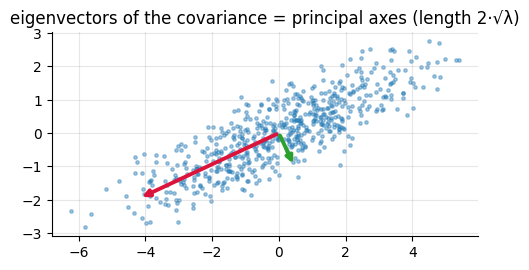

In [117]:
Xd = rng.normal(size=(600, 2)) @ np.array([[2.0, 0.9], [0.0, 0.6]])
Xd -= Xd.mean(0)
C = Xd.T @ Xd / len(Xd)
lam_c, V_c = np.linalg.eigh(C)                       # ascending order

for k in (1, 0):
    print(f"eigenvalue {lam_c[k]:.3f}   variance of data along its eigenvector = {np.var(Xd @ V_c[:, k]):.3f}")

v = rng.normal(size=2)
for _ in range(50):
    v = C @ v; v /= np.linalg.norm(v)                # power iteration
print("power iteration vs top eigenvector |cos| =", abs(v @ V_c[:, 1]))

plt.figure(figsize=(5.5, 5))
plt.scatter(Xd[:, 0], Xd[:, 1], s=6, alpha=0.4)
for k, c in [(1, "crimson"), (0, "tab:green")]:
    plt.annotate("", xy=2 * np.sqrt(lam_c[k]) * V_c[:, k], xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.8))
plt.gca().set_aspect("equal"); plt.grid(alpha=0.3)
plt.title("eigenvectors of the covariance = principal axes (length 2·√λ)"); plt.show()

---
## 9. Preview — unitaries and Hermitian operators

> A first look. `2_quantum_mathematics.ipynb` (topics 10–11) develops these in depth.

A **linear operator** is a matrix $A$ acting on $|\psi\rangle$. Its **adjoint** is $A^\dagger=\overline{A}^{T}$ (conjugate transpose).

| Type | Condition | Role in QML |
|---|---|---|
| **Unitary** | $U^\dagger U = I$ | quantum **gates** — the layers of a circuit |
| **Hermitian** | $H^\dagger = H$ | **observables** — real eigenvalues, the measurable quantities |

**Unitaries preserve inner products and norms**: $\langle U u|U v\rangle=\langle u|v\rangle$. So a gate can never turn a valid state into an invalid one — it only *rotates* in $\mathbb{C}^n$. (Real unitaries are the orthogonal matrices you know.)

**Observables and expectation values.** For Hermitian $O$ the expectation is

$$\langle O\rangle_\psi = \langle\psi|O|\psi\rangle \in \mathbb{R}$$

and this number is the **output of a quantum model**. Example, Pauli-Z $=\mathrm{diag}(1,-1)$: $\langle Z\rangle = P(0)-P(1)$.

In [118]:
def is_unitary(U): return np.allclose(U.conj().T @ U, np.eye(len(U)))
def is_hermitian(H): return np.allclose(H, H.conj().T)

X_gate = np.array([[0, 1], [1, 0]], dtype=complex)
Z_gate = np.array([[1, 0], [0, -1]], dtype=complex)
H_gate = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

for name, M in [("X", X_gate), ("Z", Z_gate), ("H", H_gate)]:
    print(f"{name}: unitary={is_unitary(M)}  hermitian={is_hermitian(M)}")

print("not unitary:", is_unitary(np.array([[1, 1], [0, 1]], dtype=complex)))

psi = np.array([3/5, 4/5], dtype=complex)
print("<Z> =", np.vdot(psi, Z_gate @ psi).real, "  vs  P(0)-P(1) =", 0.36 - 0.64)

X: unitary=True  hermitian=True
Z: unitary=True  hermitian=True
H: unitary=True  hermitian=True
not unitary: False
<Z> = -0.2800000000000001   vs  P(0)-P(1) = -0.28


### Visualization — unitary = rigid rotation, non-unitary = distortion

Push the unit circle through three matrices. A unitary (here a real rotation) keeps every point on the circle. A shear changes lengths and angles — such a map cannot be a quantum gate.

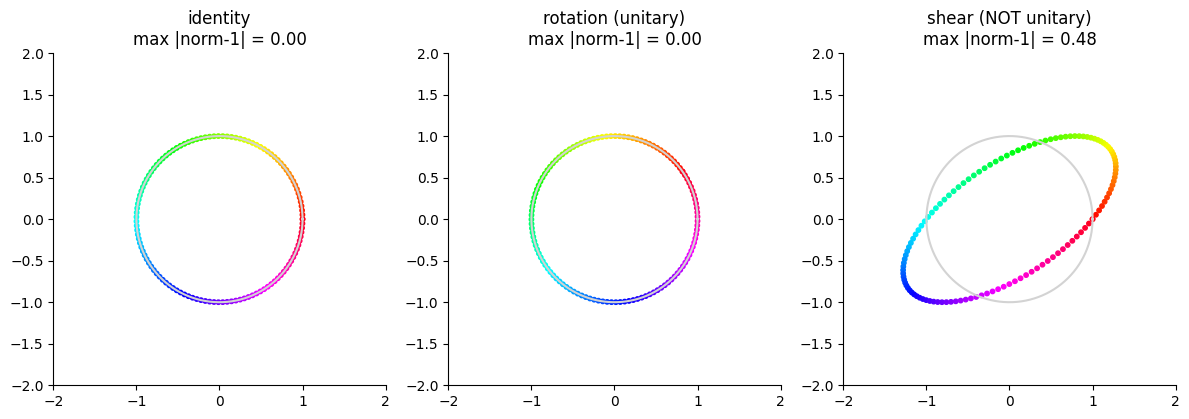

In [119]:
theta = np.deg2rad(35)
R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])   # unitary (orthogonal)
S = np.array([[1.0, 0.8], [0.0, 1.0]])                                             # shear: not unitary

t = np.linspace(0, 2 * np.pi, 120)
P = np.vstack([np.cos(t), np.sin(t)])

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, M) in zip(axs, [("identity", np.eye(2)), ("rotation (unitary)", R), ("shear (NOT unitary)", S)]):
    Q = M @ P
    ax.plot(np.cos(t), np.sin(t), color="lightgray")
    ax.scatter(Q[0], Q[1], c=t, cmap="hsv", s=10)
    ax.set_aspect("equal"); ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
    ax.set_title(f"{name}\nmax |norm-1| = {np.abs(np.linalg.norm(Q, axis=0) - 1).max():.2f}")
plt.tight_layout(); plt.show()

### Example for an ML engineer — orthogonal/unitary maps never explode or vanish

Deep nets and RNNs suffer from exploding/vanishing signals because repeated multiplication by $W$ scales the norm like $\|W\|^k$. **Orthogonal initialization** and **unitary RNNs** fix this by using norm-preserving maps — exactly the property quantum circuits have for free. Stacking 50 gates keeps the state valid.

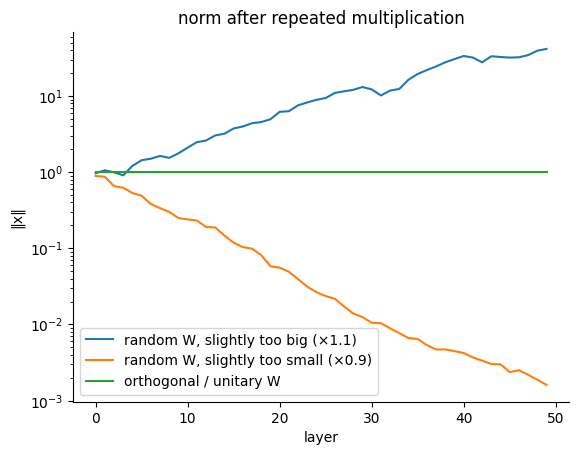

In [120]:
n, depth = 64, 50
x0 = rng.normal(size=n); x0 /= np.linalg.norm(x0)

def run(make_W):
    x, norms = x0.copy(), []
    for _ in range(depth):
        x = make_W() @ x
        norms.append(np.linalg.norm(x))
    return norms

gauss = lambda s: (lambda: s * rng.normal(size=(n, n)) / np.sqrt(n))
Qmat, _ = np.linalg.qr(rng.normal(size=(n, n)))                    # one fixed orthogonal matrix

plt.semilogy(run(gauss(1.1)), label="random W, slightly too big (×1.1)")
plt.semilogy(run(gauss(0.9)), label="random W, slightly too small (×0.9)")
plt.semilogy(run(lambda: Qmat), label="orthogonal / unitary W")
plt.xlabel("layer"); plt.ylabel("‖x‖"); plt.legend(); plt.title("norm after repeated multiplication"); plt.show()

---
## 10. Preview — tensor product

> A first look. `2_quantum_mathematics.ipynb` (topic 12) develops this in depth.

To combine two systems, take the **tensor (Kronecker) product** of their spaces: $\mathbb{C}^m\otimes\mathbb{C}^n=\mathbb{C}^{mn}$.

$$\begin{pmatrix}a\\b\end{pmatrix}\otimes\begin{pmatrix}c\\d\end{pmatrix}=\begin{pmatrix}ac\\ad\\bc\\bd\end{pmatrix}$$

- Dimensions **multiply** — hence $2^n$ for $n$ qubits.
- Gates on separate qubits combine as $A\otimes B$.
- Not every vector in $\mathbb{C}^4$ is a product $u\otimes v$. The rest are **entangled**.

Reshape the 4-vector into a $2\times2$ matrix $M_{ij}$: a product state is exactly a **rank-1** matrix ($M = u v^T$).

In [121]:
u = np.array([1, 2j]) / np.sqrt(5)
v = np.array([3, 4]) / 5
prod = np.kron(u, v)                                   # product state in C^4
bell = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)

print("kron(u, v) =", prod)
print("rank of reshape(product) =", np.linalg.matrix_rank(prod.reshape(2, 2)))
print("rank of reshape(bell)    =", np.linalg.matrix_rank(bell.reshape(2, 2)))

kron(u, v) = [0.2683+0.j     0.3578+0.j     0.    +0.5367j 0.    +0.7155j]
rank of reshape(product) = 1
rank of reshape(bell)    = 2


### Visualization — product vs. entangled as a 2×2 matrix

The reshaped amplitude matrix of a product state has a clean outer-product structure (rank 1). The Bell state is diagonal with equal entries — rank 2, cannot be factored.

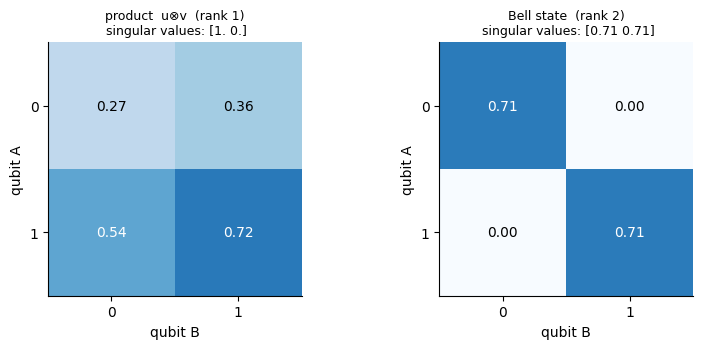

In [122]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, (name, s) in zip(axs, [("product  u⊗v  (rank 1)", prod), ("Bell state  (rank 2)", bell)]):
    M = np.abs(s.reshape(2, 2))
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    for (i, j), val in np.ndenumerate(M):
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="white" if val > 0.5 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel("qubit B"); ax.set_ylabel("qubit A")
    ax.set_title(f"{name}\n singular values: {np.round(np.linalg.svd(s.reshape(2,2), compute_uv=False), 2)}", fontsize=9)
plt.tight_layout(); plt.show()

### Example for an ML engineer — feature crossing and low-rank structure

- `np.kron(u, v)` is the **outer-product / feature-crossing** layer: all pairwise products $u_iv_j$ (as in bilinear pooling, factorization machines).
- A product state is a **rank-1 tensor**; an entangled state is a higher-rank one. Quantum "expressivity" partly means access to correlations that low-rank (product) models miss — the same trade-off as rank in matrix/tensor factorization.

In [123]:
# A 'user' embedding x 'item' embedding, crossed: rank-1 by construction
user = rng.normal(size=3); item = rng.normal(size=4)
crossed = np.kron(user, item).reshape(3, 4)
print("crossed shape:", crossed.shape, "  rank:", np.linalg.matrix_rank(crossed))

# A generic interaction matrix is NOT rank-1 -> needs a sum of crosses (= 'entangled')
generic = rng.normal(size=(3, 4))
print("generic rank :", np.linalg.matrix_rank(generic))

crossed shape: (3, 4)   rank: 1
generic rank : 3


<div style="border-left: 5px solid #2563eb; background: rgba(37, 99, 235, 0.12); padding: 10px 16px; border-radius: 4px;">

<b style="color:#2563eb">🔵 Big idea, for a programmer</b>

A complex number is a **pair of floats** `(re, im)` plus **one extra rule: multiplying two pairs rotates and scales.** That rotation rule is the whole reason quantum computing is written in complex numbers. The code cell right below shows it in 10 lines of plain Python.

</div>

In [124]:
import math

# A complex number is just a pair of floats (re, im) ...
z = (3.0, 2.0)                     # the point 3 + 2i
i = (0.0, 1.0)                     # the imaginary unit


# ... plus ONE extra rule: how to multiply two pairs
def mul(p, q):
    (a, b), (c, d) = p, q
    return (a * c - b * d, a * d + b * c)


print("z * i =", mul(z, i), "   <- (3, 2) became (-2, 3): turned by 90°")

# multiply by a pair of length 1.5 and angle 40°: it turns by 40° and stretches by 1.5
angle = math.radians(40)
w = (1.5 * math.cos(angle), 1.5 * math.sin(angle))
zw = mul(z, w)


def length_and_angle(p):
    return math.hypot(*p), math.degrees(math.atan2(p[1], p[0]))


print("before:", length_and_angle(z))
print("after :", length_and_angle(zw), "   <- length x 1.5, angle + 40°")

# Python's built-in complex type implements exactly this rule
print("built-in complex agrees:", complex(*z) * complex(*w), "==", complex(*zw))

z * i = (-2.0, 3.0)    <- (3, 2) became (-2, 3): turned by 90°
before: (3.605551275463989, 33.690067525979785)
after : (5.408326913195984, 73.69006752597979)    <- length x 1.5, angle + 40°
built-in complex agrees: (1.5188371649757832+5.1906775729463615j) == (1.5188371649757832+5.1906775729463615j)


---
## 11. Exercises

Do them on paper first, then verify in code.

**Exercise 1 — complex arithmetic.** Compute $(1+2i)(3-i)$ and $|1+2i|$ by hand, then check with Python complex numbers. What does multiplying by $i$ do geometrically?

In [125]:
# TODO

**Exercise 2 — inner product.** For $u=(1, i)/\sqrt2$ and $v=(1, 1)/\sqrt2$ compute $\langle u|v\rangle$, $\langle v|u\rangle$, and $|\langle u|v\rangle|^2$. How are the first two related?

In [126]:
# TODO

**Exercise 3 — orthonormal basis.** Show that $\{(1,i)/\sqrt2,\ (1,-i)/\sqrt2\}$ is an orthonormal basis of $\mathbb{C}^2$. Expand $|0\rangle$ in it and check $\sum|c_i|^2=1$.

In [127]:
# TODO

**Exercise 4 — unitarity.** Write `is_unitary` for the matrix $\begin{pmatrix}1&0\\0&i\end{pmatrix}$ and for $\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ (without the $1/\sqrt2$). Which are unitary? Fix the second.

In [128]:
# TODO

**Exercise 5 — expectation.** For $|\psi\rangle=(\cos\tfrac{\theta}{2},\sin\tfrac{\theta}{2})$ show $\langle Z\rangle=\cos\theta$ and plot it for $\theta\in[0,2\pi]$. Why is this the shape of a QML model's output as a function of a rotation angle?

In [129]:
# TODO

**Exercise 6 — tensor product.** Build $|+\rangle\otimes|-\rangle$, list its 4 amplitudes, and verify it has rank 1. Then check that $\tfrac{1}{\sqrt2}(|01\rangle+|10\rangle)$ has rank 2.

In [130]:
# TODO

**Exercise 7 (ML link).** Write a kernel $k(x,y)=|\langle\phi(x)|\phi(y)\rangle|^2$ with $\phi(x)=(\cos x,\sin x)$ and fit scikit-learn's `SVC(kernel='precomputed')` on `make_moons` after scaling features to $[0,\pi]$ (use only the first feature). Report accuracy vs. an RBF kernel.

In [131]:
# TODO

**Exercise 8 — Euler.** Show numerically that $e^{i\pi}+1=0$. Then use $e^{i\alpha}e^{i\beta}=e^{i(\alpha+\beta)}$ and Euler's formula to derive $\cos(\alpha+\beta)=\cos\alpha\cos\beta-\sin\alpha\sin\beta$ (compare real parts), and verify it for two angles.

In [132]:
# TODO

**Exercise 9 — normalization.** Normalize $(1+i,\ 2,\ -i)$ and report the three outcome probabilities. Multiply the state by $e^{0.7i}$ and show the probabilities do not change. Multiply only the *second* component by $e^{0.7i}$ — do the probabilities change? Does the state?

In [133]:
# TODO

**Exercise 10 — angles.** Compute the Hilbert-space angle and the Bloch-sphere angle between $|0\rangle$ and $\cos\tfrac{\pi}{8}|0\rangle+\sin\tfrac{\pi}{8}|1\rangle$. What is the relation between the two?

In [134]:
# TODO

**Exercise 11 — change of basis.** Write $|\psi\rangle=(3/5,\ 4i/5)$ in the Hadamard basis with $c=B^\dagger\psi$. Check $\sum\lvert c_i\rvert^2=1$ and that $c=H\psi$. Then give the coordinates in the basis $\{(1,i)/\sqrt2,\ (1,-i)/\sqrt2\}$.

In [135]:
# TODO

**Exercise 12 — linear maps.** A linear map sends $|0\rangle\to|+\rangle$ and $|1\rangle\to|-\rangle$. Write its matrix from the *columns = images* rule. Which gate is it? What does it do to $|+\rangle$?

In [136]:
# TODO

**Exercise 13 — eigenvalues.** Find the eigenvalues and eigenvectors of $Y=\begin{bmatrix}0&-i\\i&0\end{bmatrix}$ by hand ($\det(Y-\lambda I)=0$) and check with `np.linalg.eigh`. If $Y$ is measured on $|0\rangle$, what are the outcomes, their probabilities, and $\langle Y\rangle$?

In [137]:
# TODO

**Exercise 14 — eigen and gates.** Show that the eigenvalues of $R_Z(\theta)$ are $e^{\mp i\theta/2}$, and that $|0\rangle$ and $|1\rangle$ stay eigenvectors for any $\theta$. Why does $R_Z$ never change computational-basis probabilities?

In [138]:
# TODO

---
## 12. Cheat sheet and what's next

| Topic | Key facts | Quantum meaning | ML analogue |
|---|---|---|---|
| Complex number | $z=a+bi=re^{i\theta}$, $\bar z$, $\lvert z\rvert$; $e^{i\theta}=\cos\theta+i\sin\theta$ | amplitude = length (probability) + angle (phase) | RoPE rotations |
| Complex vector | $\mathbb{C}^n$, components are amplitudes | a state; global phase invisible, relative phase observable | FFT coefficients |
| Hilbert space | complex vector space + inner product; dim $n$; $\mathbb{C}^{2^k}$ for $k$ qubits | the space of states | kernel feature space |
| Inner product | $\langle u\vert v\rangle=\sum\bar u_iv_i$; $\cos\theta=\lvert\langle u\vert v\rangle\rvert/(\lVert u\rVert\lVert v\rVert)$ | overlap, orthogonality | cosine similarity |
| Norm / normalization | $\lVert v\rVert=\sqrt{\sum\lvert v_i\rvert^2}$; $\hat v=v/\lVert v\rVert$ | valid state = unit vector; Born rule $p_i=\lvert v_i\rvert^2$ | L2-normalization, softmax |
| Basis / change of basis | $c_i=\langle e_i\vert\psi\rangle$; $c=B^\dagger\psi$ | Z basis vs. Hadamard basis ($B=H$) | PCA scores |
| Linear map | columns of $A$ are $Ae_j$; $BA$ = first $A$ then $B$; $AB\ne BA$ | gates, evolution (superposition principle) | dense layer |
| Eigen-pair | $Av=\lambda v$; Hermitian: real $\lambda$, orthogonal $v_k$; unitary: $\lvert\lambda\rvert=1$ | measurement outcomes and post-measurement states; $\langle O\rangle=\sum\lambda_kp_k$ | PCA, power iteration |
| *Preview:* unitary | $U^\dagger U=I$ | gate: norm-preserving rotation | orthogonal layer |
| *Preview:* tensor product | $\otimes$ (`np.kron`), dims multiply | multi-qubit states, entanglement | feature crossing |

**Next:** `2_quantum_mathematics.ipynb` (matrix operations, unitaries, Hermitian matrices, tensor products, Born rule, measurement, matrix exponentials, density matrices, entanglement), then **Week 1: qubits, state vectors, measurement**.